# Strong forward flow map $\Psi_\nu$ for a CIR process 

This notebook learns the **strong forward flow map** of the Cox–Ingersoll–Ross process $\mathrm dX=\theta(\mu-X)\,\mathrm dt+\sigma\sqrt X\,\mathrm dW$, with the Feller condition $2\theta\mu\ge\sigma^2$ satisfied. 

The map takes the state $x=X_s$ and the Legendre coefficients $\hat I$ of the Brownian path on $[s,t]$ and returns $X_t$, in the form of the *Strong Stochastic Flow Maps* paper (McCallum, Blasingame et al., 2026).

With respect to SSFM, three things change. The data are simulated by a **drift-implicit scheme on $\sqrt X$** that is positive for every Brownian increment. The map is **multiplicative**, $\Psi=x\exp(E)$ with a bounded exponent, so it is positive for every value of the weights and a chain of map calls can never reach zero. The residuals are weighted by $1/(h\,x_s)$ to match the state-dependent noise.

## §0 Theory used by this notebook

### 0.1 The process

$$\mathrm dX_u=\theta(\mu-X_u)\,\mathrm du+\sigma\sqrt{X_u}\,\mathrm dW_u,\qquad \theta=1.5,\ \mu=0.5,\ \sigma=0.8,\qquad X_0\sim\mathrm{Gamma}(4,\,0.3)\ \text{independent of }W.$$

The Feller ratio is $2\theta\mu/\sigma^2=2.34\ge1$, so $X_u>0$ for all $u$ almost surely. The conditional mean is linear, $\mathbb E[X_t\mid X_s=x]=\mu+e^{-\theta h}(x-\mu)$ with $h=t-s$, and the transition law is a scaled non-central $\chi^2$:

$$2cX_t\mid X_s=x\ \sim\ \chi'^2_d\bigl(2cxe^{-\theta h}\bigr),\qquad c=\frac{2\theta}{\sigma^2(1-e^{-\theta h})},\quad d=\frac{4\theta\mu}{\sigma^2},$$

$$\mathrm{Var}[X_t\mid X_s=x]=x\,\frac{\sigma^2}{\theta}\bigl(e^{-\theta h}-e^{-2\theta h}\bigr)+\mu\,\frac{\sigma^2}{2\theta}\bigl(1-e^{-\theta h}\bigr)^2 .$$

The marginal mean and variance of $X_t$ follow by averaging over $X_0$. The marginal law is a Gamma mixture of these transitions and is evaluated by Gauss–Laguerre quadrature over $X_0$.

### 0.2 Why a strong flow map exists for CIR

The diffusion coefficient $\sqrt x$ is not Lipschitz at $0$, and the noise is state-dependent, so the additive-noise argument of the paper does not apply as it stands. The Lamperti transform $Y=\sqrt X$ removes both problems:

$$\mathrm dY_u=\Bigl(\frac{\alpha}{Y_u}-\frac{\theta}{2}Y_u\Bigr)\mathrm du+\frac{\sigma}{2}\,\mathrm dW_u,\qquad \alpha=\frac{4\theta\mu-\sigma^2}{8}>0 .$$

The noise of $Y$ is additive and the drift is smooth on $(0,\infty)$, which $Y$ never leaves under the Feller condition. With $Z_u=Y_u-\tfrac\sigma2(W_u-W_s)$ the equation becomes a random ODE, so $Y_t$ is a function of $Y_s$ and of the increments $\{W_u-W_s\}_{s\le u\le t}$, and $X_t=Y_t^2$ is a function of $X_s$ and of the same increments. This is the Itô map that $\Psi_\nu$ approximates. In one dimension the comparison theorem makes it increasing in $x$, and it satisfies the cocycle $\phi_{s,t}=\phi_{u,t}\circ\phi_{s,u}$.

The Jacobian $\partial_x\phi_{s,t}$ is random (it depends on the path through $1/Y$)

### 0.3 The data scheme, positive by construction

The paths are simulated by the drift-implicit Euler scheme on $Y=\sqrt X$ (Alfonsi 2005; strong convergence in Dereich, Neuenkirch and Szpruch 2012):

$$Y_{k+1}=Y_k+\Bigl(\frac{\alpha}{Y_{k+1}}-\frac\theta2Y_{k+1}\Bigr)\Delta t+\frac\sigma2\Delta W_k .$$

Multiplying by $Y_{k+1}$ gives $(1+\tfrac\theta2\Delta t)Y_{k+1}^2-(Y_k+\tfrac\sigma2\Delta W_k)Y_{k+1}-\alpha\Delta t=0$. The product of the two roots is $-\alpha\Delta t/(1+\tfrac\theta2\Delta t)<0$, so exactly one root is positive:

$$Y_{k+1}=\frac{c_k+\sqrt{c_k^2+4(1+\tfrac\theta2\Delta t)\,\alpha\Delta t}}{2(1+\tfrac\theta2\Delta t)},\qquad c_k=Y_k+\tfrac\sigma2\Delta W_k,\qquad X_{k+1}=Y_{k+1}^2>0 .$$

This holds for every value of $\Delta W_k$ as soon as $\alpha>0$, i.e. $4\theta\mu>\sigma^2$, which the Feller condition implies. The scheme is a deterministic function of $X_k$ and $\Delta W_k$, so the data are a pathwise function of $X_0$ and the fine increments: exactly the object a strong map learns.

### 0.4 Legendre coefficients

With $\tilde P_n(x)=P_n(2x-1)$ the shifted Legendre polynomials ($\int_0^1\tilde P_n\tilde P_m=\delta_{nm}/(2n+1)$), $I^{(n)}_{s,t}=\int_s^t\tilde P_n\bigl(\tfrac{r-s}{t-s}\bigr)\mathrm dW_r$. 

They are independent $N\bigl(0,\tfrac{t-s}{2n+1}\bigr)$ (Theorem 3.4 of the SSFM paper), $I^{(0)}=W_t-W_s$, the degree-$N$ polynomial approximation of the path is $W^{(N)}_{u,v}=\sum_{n<N}\tfrac{2n+1}{t-s}I^{(n)}\int_u^v\tilde P_n\bigl(\tfrac{r-s}{t-s}\bigr)\mathrm dr$, and the coefficients obey the Chen relations $I^{(n)}_{s,t}=\sum_{m\le n}c_{n,m}\bigl(I^{(m)}_{s,u}+(-1)^{n+m}I^{(m)}_{u,t}\bigr)$ for the midpoint $u$ (Proposition A.5). 

The network receives the normalised coefficients $\hat I_n=I^{(n)}\sqrt{(2n+1)/(t-s)}$, which are standard normal. Nothing here depends on the process.

### 0.5 The multiplicative map

$$\Psi_\nu(x,\hat I,h)=x\,\exp(E),\qquad E=c\,\tanh(\tilde E/c),\qquad \tilde E=h\,M^{(1)}_\nu(z,\hat I,\sqrt h)+w\,M^{(2)}_\nu(z,\hat I,\sqrt h),$$

with $w=\hat I_0\sqrt h=W_t-W_s$, the state input $z=8\tanh\bigl(\log(x/\mu)/8\bigr)$ and the cap $c=10$.

The form comes from Itô's formula for $\log X$: $\mathrm d\log X=\bigl(\theta(\mu-X)/X-\sigma^2/(2X)\bigr)\mathrm dt+(\sigma/\sqrt X)\,\mathrm dW$, so over a short window $\log(X_t/X_s)\approx h\cdot(\text{log-drift})+w\cdot(\text{log-diffusion})$, which is $\tilde E$ with the two heads in those roles. Both heads see the state, because the noise is multiplicative. 

The exponential makes $\Psi>0$ for every weight; the $\tanh$ cap bounds $|E|<c$, so $\Psi\in(xe^{-c},xe^{c})$ and one call can neither explode nor collapse to zero. The cap is far from binding on the data: the largest $|\log(X_t/X_s)|$ over windows of the training paths is printed in §N4 (below $8$, against $c=10$). 

The state enters through $\log(x/\mu)$, saturated at $\pm8$: on the data range ($\log(x/\mu)\in[-6.9,2.1]$) it is close to the logarithm, and a state far below the data is treated like the lowest observed states instead of being extrapolated. Without the saturation, in development a few chains that undershot into the sparse region near zero kept shrinking (to $10^{-35}$, positive but meaningless). The heads are SiLU perceptrons with $3$ hidden layers of width $64$; one network serves every window length $h$.

**Tangent identification.** Expanding the exponential, $\Psi-x\approx x\bigl(hM^{(1)}+wM^{(2)}+\tfrac12w^2(M^{(2)})^2\bigr)$, so as $h\to0$

$$\frac{\mathbb E[\Psi]-x}{h}\to x\Bigl(M^{(1)}+\tfrac12(M^{(2)})^2\Bigr)=b(x),\qquad \frac{\mathrm{Var}[\Psi]}{h}\to x^2(M^{(2)})^2=\sigma^2x,$$

i.e. $M^{(2)}\to\sigma/\sqrt x$ and $M^{(1)}\to\theta(\mu-x)/x-\sigma^2/(2x)$. These are the read-outs of §N6.6.

### 0.6 The training objective

As in the repository of original Paper, one loss with both conditions:

$$\mathcal L=\eta\,\mathbb E\,\frac{\bigl(\Psi(x_s,\hat I_{s,t},h)-x_t\bigr)^2}{h\,x_s}+(1-\eta)\,\mathbb E\,\frac{\bigl(\Psi(x_s,\hat I_{s,t},h)-\mathrm{sg}[\Psi_{\rm ema}(\Psi_{\rm ema}(x_s,\hat I_{s,u},\tfrac h2),\hat I_{u,t},\tfrac h2)]\bigr)^2}{h\,x_s},\qquad \eta=0.75,$$

with $u$ the midpoint and $\hat I_{s,t}$ the Chen combination of $\hat I_{s,u},\hat I_{u,t}$. Batch $4096$, Adam with cosine rate $10^{-3}\to10^{-5}$, global-norm clip $10$, EMA decay $0.999$ (with warm-up $\min(0.999,(1+t)/(10+t))$); the EMA network is both the teacher and the network that is evaluated and frozen.

The residual weight is $1/(h\,x_s)$ instead of the repository's $1/h$. The conditional variance of the target is $\approx\sigma^2x_sh$, so this weight puts all states on the same footing, and since it depends only on the input it does not change the population minimiser $\mathbb E[X_t\mid x_s,\hat I]$.

**Oversampling of low states.** Only $0.5\%$ of the training states lie below $0.05$, yet that is where a chain that undershoots ends up. A quarter of every tangent sub-batch is therefore drawn among the windows that start below the $5\%$ quantile of the states. This changes the distribution of inputs only, so the minimiser is unchanged. Development runs (single seed, $12\,000$ iterations, validation paths): without it the strong error was $0.063$ and $13$ of $12\,000$ chains fell below $10^{-4}$; with it $0.079$ and $1$ chain (smallest state $3.6\cdot10^{-6}$). `TAN_LOW_SHARE = 0` restores uniform sampling. Two other options were tried and dropped: the weight $1/(hx_s^2)$ (training became unstable) and feeding the semigroup term jittered states (worse on every measure).

Not used: a curriculum on the window length, adaptive clipping, selection of a checkpoint on validation data, early stopping, a tuned weight between the two terms.

### 0.7 Known limits

**Read-out bias at finite $h$.** For the exact flow $\hat b_h(x)=\theta(\mu-x)\,(1-e^{-\theta h})/(\theta h)$ and $\hat\sigma^2_h(x)=\mathrm{Var}[X_h\mid x]/h\to\sigma^2x$. Both are reported and the $O(h)$ part is removed by Richardson extrapolation $2\hat f_h-\hat f_{2h}$.

**Contraction only on average.** $\mathbb E\,\partial_x\phi=e^{-\theta h}<1$, but the pathwise Jacobian is random, larger where the path visits small states. The damping of chain errors is therefore an average statement.

## N1 — Configuration and utilities

In [1]:
import os, json, time, hashlib, math, csv
import numpy as np
import matplotlib.pyplot as plt
from numpy.polynomial import Legendre
from scipy import stats as sps
from scipy.special import roots_genlaguerre, gammaln
import pandas as pd

VARIANT = 'CIR'
SEED = 777
THETA, MU, SIGMA, T_END = 1.5, 0.5, 0.8, 2.5     # dX = THETA (MU - X) dt + SIGMA sqrt(X) dW
X0_SHAPE, X0_SCALE = 4.0, 0.3                    # X_0 ~ Gamma(shape 4, scale 0.3): mean 1.2, sd 0.6
FELLER = 2 * THETA * MU / SIGMA ** 2
assert FELLER >= 1.0, 'Feller condition 2 theta mu >= sigma^2 is violated'
ALPHA = (4 * THETA * MU - SIGMA ** 2) / 8.0     # drift constant of Y = sqrt(X); ALPHA > 0 keeps the scheme positive
N_PATHS, N_FINE = 20000, 1200
DT = T_END / N_FINE
MAX_CHAIN = 50                      # ceiling on the number of jumps of a chain
CELLS_AN = N_FINE                   # the reconstruction runs on the whole horizon [0, T]
NS_AVG = (20, 24, 25, 30, 40, 50)   # chains averaged in the strong error
NS_REC = (2, 5, 10, 20, 30, 50)     # chains drawn in the reconstruction figures
NS_TAB = (1, 2, 5, 10) + NS_AVG     # chains printed in the tables
KC = 6                              # number of Legendre coefficients given to the map
LOGCAP = 10.0                       # cap of the exponent: |log(Psi / x)| < LOGCAP
ZC = 8.0                            # saturation of the state input: z = ZC tanh(log(x / mu) / ZC)
SPLITS = {'train': (0, 12000), 'val': (12000, 16000), 'test': (16000, 20000)}
LV = (2, 8, 24, 48, 80, 240, 480, 1200)     # window lengths in fine cells (all even): validation and diagnostics

SMOKE = False                       # True only in a temporary smoke-test copy

# ---- budgets ----
IT_G, B_G = 12000, 4096             # the SSFM run (the repository: 100000 steps, batch 4096); about 20 min single-threaded
ETA = 0.75                          # share of every batch used by the tangent term
LR_S, LR_S_MIN, CLIP_S = 1e-3, 1e-5, 10.0
EMA_S = 0.999
EMA_WARMUP = True                   # decay min(0.999, (1+t)/(10+t)); False: constant 0.999 as in the repository
NET_W, NET_D = 64, 3
L_TAN = 4                           # tangent windows of 1..L_TAN fine cells
TAN_LOW_SHARE = 0.25                # share of every tangent sub-batch drawn at states below the LOW_Q quantile (0: uniform, as in the repository)
LOW_Q = 0.05
VAL_EVERY = 250
N_VAL, N_TEST_WIN = 2000, 4000      # validation / test windows per length
N_BOOT = 2000
N_RO = 2000                         # coefficient draws per state in the read-out of b and sigma
REF_PATH = 16000                    # test path of the reconstruction figure

OVERWRITE_FROZEN = False
TEST_UNLOCKED = False

if SMOKE:
    IT_G, B_G = 40, 256
    VAL_EVERY = 10
    N_VAL, N_TEST_WIN = 300, 400
    N_BOOT, N_RO = 200, 200

MODEL_DIR, RES_DIR, SHARED_DIR = 'models_' + VARIANT + '_fwd', 'results_' + VARIANT + '_fwd', 'results_shared'
for d in (MODEL_DIR, RES_DIR, SHARED_DIR):
    os.makedirs(d, exist_ok=True)
REG_PATH = os.path.join(MODEL_DIR, 'registry_' + VARIANT + '_fwd.json')

print('VARIANT =', VARIANT, '| SMOKE =', SMOKE)
print(f'theta, mu, sigma, T = {THETA}, {MU}, {SIGMA}, {T_END} | Feller ratio 2 theta mu / sigma^2 = {FELLER:.3f} | alpha = {ALPHA:.4f}')
print(f'dt = {DT:.6f} | K coefficients = {KC} | exponent cap = {LOGCAP}')
print('budgets: SSFM run', IT_G, B_G, '| eta', ETA, '| EMA warm-up', EMA_WARMUP, '| strong error averaged over n =', NS_AVG)
assert all(CELLS_AN % n_ == 0 and n_ <= MAX_CHAIN for n_ in set(NS_AVG) | set(NS_REC) | set(NS_TAB))

VARIANT = CIR | SMOKE = False
theta, mu, sigma, T = 1.5, 0.5, 0.8, 2.5 | Feller ratio 2 theta mu / sigma^2 = 2.344 | alpha = 0.2950
dt = 0.002083 | K coefficients = 6 | exponent cap = 10.0
budgets: SSFM run 12000 4096 | eta 0.75 | EMA warm-up True | strong error averaged over n = (20, 24, 25, 30, 40, 50)


### Utilities: streams, activations, parameter trees, Adam

In [2]:
def rg(*key):
    # named sub-stream; the data generator default_rng(777) is created only in N2
    return np.random.default_rng(list(key))

def sigmoid(z):
    return 0.5 * (1.0 + np.tanh(0.5 * z))           # numerically stable logistic

def silu(z):
    return z * sigmoid(z)

def silu_d1(z):
    s = sigmoid(z)
    return s * (1.0 + z * (1.0 - s))

# ---- parameter trees: dict name -> list of [W, c] ----
def tree_copy(T):
    return {k: [[W.copy(), c.copy()] for W, c in v] for k, v in T.items()}

def tree_zeros(T):
    return {k: [[np.zeros_like(W), np.zeros_like(c)] for W, c in v] for k, v in T.items()}

def tree_add(A, B, scale=1.0):          # A + scale*B (new tree)
    return {k: [[A[k][l][0] + scale * B[k][l][0], A[k][l][1] + scale * B[k][l][1]]
                for l in range(len(A[k]))] for k in A}

def tree_scale(A, s):
    return {k: [[W * s, c * s] for W, c in v] for k, v in A.items()}

def tree_flat(A):
    return np.concatenate([np.concatenate([W.ravel(), c.ravel()]) for k in sorted(A) for W, c in A[k]])

def tree_norm(A):
    return float(np.sqrt(np.sum(tree_flat(A) ** 2)))

def n_params(A):
    return int(tree_flat(A).size)

# ---- optimiser ----
def adam_init(T):
    return {'m': tree_zeros(T), 'v': tree_zeros(T), 't': 0}

def adam_step(T, G, st, lr, b1=0.9, b2=0.999, eps=1e-8):
    st['t'] += 1
    t = st['t']
    out = {}
    for k in T:
        out[k] = []
        for l in range(len(T[k])):
            newl = []
            for i in range(2):
                st['m'][k][l][i] = b1 * st['m'][k][l][i] + (1 - b1) * G[k][l][i]
                st['v'][k][l][i] = b2 * st['v'][k][l][i] + (1 - b2) * G[k][l][i] ** 2
                mh = st['m'][k][l][i] / (1 - b1 ** t)
                vh = st['v'][k][l][i] / (1 - b2 ** t)
                newl.append(T[k][l][i] - lr * mh / (np.sqrt(vh) + eps))
            out[k].append(newl)
    return out

def clip_tree(G, maxnorm):
    nrm = tree_norm(G)
    if nrm > maxnorm:
        G = tree_scale(G, maxnorm / nrm)
    return G, nrm

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        h.update(f.read())
    return h.hexdigest()

### Utilities: statistical tests, tables, bootstrap

In [3]:
try:
    from IPython.display import display
except Exception:
    display = print
pd.options.display.float_format = '{:.4g}'.format
pd.options.display.width = 220
pd.options.display.max_columns = 60

def show(df):
    display(df)

norm_cdf = sps.norm.cdf
norm_pdf = sps.norm.pdf
norm_ppf = sps.norm.ppf

def ks_test(x, cdf):
    # one-sample Kolmogorov-Smirnov test against a vectorised cdf: (D, p-value)
    r = sps.kstest(np.asarray(x, float), cdf)
    return float(r.statistic), float(r.pvalue)

def ks_normal(x, mean, sd):
    return ks_test(x, sps.norm(loc=mean, scale=sd).cdf)

def ks_uniform(u):
    return ks_test(u, sps.uniform.cdf)

def dagostino_k2(x):
    r = sps.normaltest(np.asarray(x, float))
    return float(r.statistic), float(r.pvalue)

def jarque_bera(x):
    r = sps.jarque_bera(np.asarray(x, float))
    return float(r.statistic), float(r.pvalue)

def paired_boot_idx(n_items, n_boot, key):
    return rg(*key).integers(0, n_items, size=(n_boot, n_items)).astype(np.int32)

def boot_ci(vals):
    return float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))

### Utilities: freeze, registry, load

In [4]:
def file_id(mid):
    return 'SF_' + VARIANT + '_' + mid.replace(':', '_').replace('.', '_')

def tree_to_arrays(T, prefix=''):
    out = {}
    for k in T:
        for l, (W, c) in enumerate(T[k]):
            out[f'{prefix}{k}_W{l}'] = W
            out[f'{prefix}{k}_c{l}'] = c
    return out

def arrays_to_tree(A, names, prefix=''):
    T = {}
    for k in names:
        T[k] = []
        l = 0
        while f'{prefix}{k}_W{l}' in A:
            T[k].append([np.array(A[f'{prefix}{k}_W{l}']), np.array(A[f'{prefix}{k}_c{l}'])])
            l += 1
    return T

def read_registry(path=None):
    path = path or REG_PATH
    if not os.path.exists(path):
        return {}
    with open(path) as f:
        return json.load(f)

def write_registry(reg, path=None):
    path = path or REG_PATH
    with open(path, 'w') as f:
        json.dump(reg, f, indent=1)

def save_readonly(path, arrays, overwrite):
    if os.path.exists(path):
        if not overwrite:
            raise RuntimeError(f'{path} is frozen; set OVERWRITE_FROZEN = True to retrain')
        os.chmod(path, 0o644)
        os.remove(path)
    np.savez(path, **arrays)
    os.chmod(path, 0o444)
    return sha256_file(path)

def freeze(mid, arrays, meta, val_fn, overwrite=None):
    # val_fn(arrays_dict) -> float (deterministic validation number)
    overwrite = OVERWRITE_FROZEN if overwrite is None else overwrite
    path = os.path.join(MODEL_DIR, file_id(mid) + '.npz')
    v0 = val_fn(arrays)
    sha = save_readonly(path, arrays, overwrite)
    with np.load(path) as Z:
        reloaded = {k: np.array(Z[k]) for k in Z.files}
    v1 = val_fn(reloaded)
    assert abs(v1 - v0) <= 1e-12 * max(1.0, abs(v0)), f'reload check failed {v0} vs {v1}'
    reg = read_registry()
    entry = dict(file=path, sha256=sha, data_hash=DATA_HASH, val_reload=float(v1))
    entry.update(meta)
    reg[mid] = entry
    write_registry(reg)
    print(f'frozen {mid}: {path}  sha256 {sha[:16]}...  validation {v1:.10g} (reload check passed)')
    return path, sha

def load_frozen(mid):
    reg = read_registry()
    if mid not in reg:
        raise KeyError(f'{mid} not in registry')
    e = reg[mid]
    if sha256_file(e['file']) != e['sha256']:
        raise RuntimeError(f'SHA-256 mismatch for {e["file"]}')
    if e['data_hash'] != DATA_HASH:
        raise RuntimeError(f'data hash mismatch for {mid}')
    with np.load(e['file']) as Z:
        return {k: np.array(Z[k]) for k in Z.files}

### Utilities: test reporting and finite-difference gradient checks

**What.** report prints a PASS/FAIL line and stops on failure.  fd_check compares a hand-written gradient with Richardson central differences on random entries of every tensor.

**Why.** Every hand-written gradient is checked this way before it is used.

**Expect.** Nothing printed.

In [5]:
PASS_LEVEL = 1e-6
TEST_LOG = []

def report(tid, err, level, what):
    ok = err < level
    TEST_LOG.append((tid, what, err, ok))
    print(f'{tid:5s} {what:66s} err={err:9.2e}  {"PASS" if ok else "FAIL"}')
    if not ok:
        raise AssertionError(f'{tid} failed: {what}')

def fd_check(f, T, G, key, n_pick=12, base=1e-3, scale_rel=False):
    # Richardson central differences on random entries of every tensor of tree T
    rng = rg(*key)
    worst = 0.0
    for k in T:
        for l in range(len(T[k])):
            for i in range(2):
                arr = T[k][l][i]
                garr = G[k][l][i]
                picks = rng.choice(arr.size, size=min(n_pick, arr.size), replace=False)
                gscale = np.max(np.abs(garr)) + 1e-300
                for q in picks:
                    old = arr.flat[q]
                    def D(eps):
                        arr.flat[q] = old + eps; fp_ = f(T)
                        arr.flat[q] = old - eps; fm_ = f(T)
                        arr.flat[q] = old
                        return (fp_ - fm_) / (2 * eps)
                    fd = (4 * D(base / 2) - D(base)) / 3
                    g = garr.flat[q]
                    err = abs(g - fd) / gscale if scale_rel else abs(g - fd) / (abs(g) + abs(fd) + 1e-12)
                    worst = max(worst, err)
    return worst

## N2 — Data

$20\,000$ CIR paths: then $X_0\sim\mathrm{Gamma}(4,0.3)$, then the fine increments, then $1200$ steps of the drift-implicit scheme on $\sqrt X$ of §0.3. Splits by path: train $0$–$11999$, validation $12000$–$15999$, test $16000$–$19999$. Fingerprints are printed and the run stops if any differs.

In [6]:
t0 = time.time()
rng_data = np.random.default_rng(SEED)
X0_all = rng_data.gamma(X0_SHAPE, X0_SCALE, size=N_PATHS)
dW_all = rng_data.normal(0.0, 1.0, size=(N_PATHS, N_FINE)) * np.sqrt(DT)

def scheme_step(y, dw, dt=DT):
    # drift-implicit Euler on Y = sqrt(X): the positive root of (1 + theta dt/2) Y'^2 - (y + sigma dw/2) Y' - alpha dt = 0
    a = 1.0 + 0.5 * THETA * dt
    c = y + 0.5 * SIGMA * dw
    return (c + np.sqrt(c * c + 4.0 * a * ALPHA * dt)) / (2.0 * a)

def scheme_path(x0, dw):
    # x0 (B,), dw (B, L): states at the L+1 nodes (B, L+1); strictly positive for every dw
    Y = np.sqrt(x0)
    out = np.empty((len(x0), dw.shape[1] + 1))
    out[:, 0] = x0
    for k in range(dw.shape[1]):
        Y = scheme_step(Y, dw[:, k])
        out[:, k + 1] = Y * Y
    return out

X_all = scheme_path(X0_all, dW_all)
print(f'generated in {time.time() - t0:.1f}s')
assert np.all(np.isfinite(X_all)) and X_all.min() > 0.0, 'a state is not positive: STOP'
print(f'smallest state {X_all.min():.3e} | share of states below 0.01: {np.mean(X_all < 0.01):.2e}, below 0.05: {np.mean(X_all < 0.05):.2e}')

def coarse(n, rows):
    s = N_FINE // n
    x = X_all[rows][:, ::s].copy()                              # (P, n+1)
    w = dW_all[rows].reshape(len(rows), n, s).sum(2)           # (P, n)
    return x, w

fp = {}
fp['X0[:3]'] = (X0_all[:3], [0.6814352997, 0.5265209315, 1.5047874471])
fp['dW[0,:3]'] = (dW_all[0, :3], [-0.0440537993, 0.0100439373, -0.0583928402])
fp['X[0,[0,240,1200]]'] = (X_all[0, [0, 240, 1200]], [0.6814352997, 0.2439702552, 0.1698596839])
fp['sums X0/dW/X_T'] = (np.array([X0_all.sum(), dW_all.sum(), X_all[:, -1].sum()]), [24139.8190153526, -408.3731401512, 10272.9702573189])
for n, w0, x01 in [(5, -0.9003410982, [0.6814352997, 0.2439702552]),
                   (15, -0.4667083249, [0.6814352997, 0.3938336717]),
                   (25, -0.3992706655, [0.6814352997, 0.4299977009])]:
    x, w = coarse(n, np.array([0]))
    fp[f'n={n} path0 w0, x0:2'] = (np.array([w[0, 0], x[0, 0], x[0, 1]]), [w0] + x01)
all_ok = True
for k, (got, want) in fp.items():
    got = np.atleast_1d(got); want = np.array(want)
    tol = 1e-4 if 'sums' in k else 1e-8
    ok = np.allclose(got, want, atol=tol, rtol=0)
    all_ok &= ok
    print(f'{k:26s} {np.array2string(got, precision=8)}  {"OK" if ok else "MISMATCH"}')
assert all_ok, 'fingerprint mismatch: STOP'
DATA_HASH = hashlib.sha256(json.dumps({k: [round(float(v), 8) for v in np.atleast_1d(g)]
                                       for k, (g, _) in fp.items()}, sort_keys=True).encode()).hexdigest()
print('data hash:', DATA_HASH[:16], '...')

generated in 2.4s
smallest state 4.922e-04 | share of states below 0.01: 1.33e-04, below 0.05: 5.43e-03
X0[:3]                     [0.6814353  0.52652093 1.50478745]  OK
dW[0,:3]                   [-0.0440538   0.01004394 -0.05839284]  OK
X[0,[0,240,1200]]          [0.6814353  0.24397026 0.16985968]  OK
sums X0/dW/X_T             [24139.81901535  -408.37314015 10272.97025732]  OK
n=5 path0 w0, x0:2         [-0.9003411   0.6814353   0.24397026]  OK
n=15 path0 w0, x0:2        [-0.46670832  0.6814353   0.39383367]  OK
n=25 path0 w0, x0:2        [-0.39927067  0.6814353   0.4299977 ]  OK
data hash: 77cba8dfffc69b55 ...


### The exact CIR laws

The conditional mean and variance and the non-central $\chi^2$ transition of §0.1. The marginal mean and variance of $X_t$; the marginal density, cdf and quantile function of $X_t$, obtained by $64$-point generalised Gauss–Laguerre quadrature over $X_0\sim\mathrm{Gamma}(4,0.3)$.


In [7]:
M0 = X0_SHAPE * X0_SCALE               # mean of X_0
V0 = X0_SHAPE * X0_SCALE ** 2          # variance of X_0

def cond_mean(x, h):
    return MU + (x - MU) * np.exp(-THETA * h)

def cond_var(x, h):
    e = np.exp(-THETA * h)
    return x * SIGMA ** 2 / THETA * (e - e * e) + MU * SIGMA ** 2 / (2 * THETA) * (1 - e) ** 2

def m_exact(t):
    return cond_mean(M0, t)

def v_exact(t):
    # Var E[X_t | X_0] + E Var[X_t | X_0]
    return V0 * np.exp(-2 * THETA * np.asarray(t, float)) + cond_var(M0, t)

CIR_DF = 4 * THETA * MU / SIGMA ** 2

def _c(h):
    return 2 * THETA / (SIGMA ** 2 * (1 - np.exp(-THETA * h)))

def cir_cdf(y, x, h):
    # P(X_{s+h} <= y | X_s = x)
    c = _c(h)
    return sps.ncx2.cdf(2 * c * y, CIR_DF, 2 * c * x * np.exp(-THETA * h))

def cir_pdf(y, x, h):
    c = _c(h)
    return 2 * c * sps.ncx2.pdf(2 * c * y, CIR_DF, 2 * c * x * np.exp(-THETA * h))

_GL_U, _GL_W = roots_genlaguerre(64, X0_SHAPE - 1.0)
_GL_X0 = X0_SCALE * _GL_U                          # nodes in X_0
_GL_W = _GL_W / np.exp(gammaln(X0_SHAPE))          # weights of E f(X_0)

def marg_pdf(u, t):
    u = np.asarray(u, float)
    if t <= 0:
        return sps.gamma.pdf(u, X0_SHAPE, scale=X0_SCALE)
    return np.sum(_GL_W[:, None] * cir_pdf(u[None, :], _GL_X0[:, None], t), axis=0)

def marg_cdf(u, t):
    u = np.atleast_1d(np.asarray(u, float))
    if t <= 0:
        return sps.gamma.cdf(u, X0_SHAPE, scale=X0_SCALE)
    out = np.empty(u.size)
    for a in range(0, u.size, 4000):                # chunks: (64, 4000) at most
        out[a:a + 4000] = np.sum(_GL_W[:, None] * cir_cdf(u[None, a:a + 4000], _GL_X0[:, None], t), axis=0)
    return out

def marg_ppf(p, t):
    # quantiles by interpolation of the cdf on a fine grid of the support
    if t <= 0:
        return sps.gamma.ppf(p, X0_SHAPE, scale=X0_SCALE)
    m, s = m_exact(t), np.sqrt(v_exact(t))
    grid = np.linspace(1e-6, m + 12 * s, 6000)
    return np.interp(p, marg_cdf(grid, t), grid)

xT_ = X_all[:, -1]
print(f'X_T sample mean / var {xT_.mean():.4f} / {xT_.var():.5f}   exact {m_exact(T_END):.4f} / {v_exact(T_END):.5f}')
print(f'quadrature check: integral of the marginal density at T = {np.trapezoid(marg_pdf(np.linspace(1e-6, 6, 6001), T_END), np.linspace(1e-6, 6, 6001)):.6f}')

X_T sample mean / var 0.5136 / 0.11031   exact 0.5165 / 0.11367
quadrature check: integral of the marginal density at T = 1.000000


### The accessor
get(kind, split, n) returns read-only arrays: coarse states x, coarse increments w, fine paths Xf, fine increments dWf, and the normalised Legendre coefficients T_h of every coarse window (shape $(P,n,K)$, from §N3). 

In [8]:
_ACC = {}

def _rows(split):
    a, b = SPLITS[split]
    return np.arange(a, b)

def get(kind, split, n=None):
    # kind in {'x', 'w', 'Xf', 'dWf', 'Ih'}
    if split == 'test' and not TEST_UNLOCKED:
        raise PermissionError('test split is locked until the diagnostics (TEST_UNLOCKED = True)')
    key = (kind, split, n)
    if key not in _ACC:
        rows = _rows(split)
        if kind in ('x', 'w'):
            x, w = coarse(n, rows)
            for kk, arr in (('x', x), ('w', w)):
                arr.setflags(write=False)
                _ACC[(kk, split, n)] = arr
        elif kind == 'Xf':
            arr = X_all[rows]; arr.setflags(write=False); _ACC[key] = arr
        elif kind == 'dWf':
            arr = dW_all[rows]; arr.setflags(write=False); _ACC[key] = arr
        elif kind == 'Ih':
            arr = grid_coefs(dW_all[rows], n); arr.setflags(write=False); _ACC[key] = arr
    return _ACC[key]

for n in (5, 25, 50):
    for sp in ('train', 'val'):
        x, w = get('x', sp, n), get('w', sp, n)
        assert get('x', sp, n) is x and get('w', sp, n) is w
        assert not x.flags.writeable and not w.flags.writeable
        s = N_FINE // n
        assert np.allclose(get('dWf', sp)[:, :s].sum(1), w[:, 0], atol=1e-13)
        assert np.array_equal(get('Xf', sp)[:, ::s], x)
try:
    get('x', 'test', 5)
    raise AssertionError('test split should be locked')
except PermissionError:
    pass
print('accessor: same objects, read-only, sums of fine = coarse, test locked: OK')

accessor: same objects, read-only, sums of fine = coarse, test locked: OK


To see that the data follow the CIR law before any model touches them. We print the following:

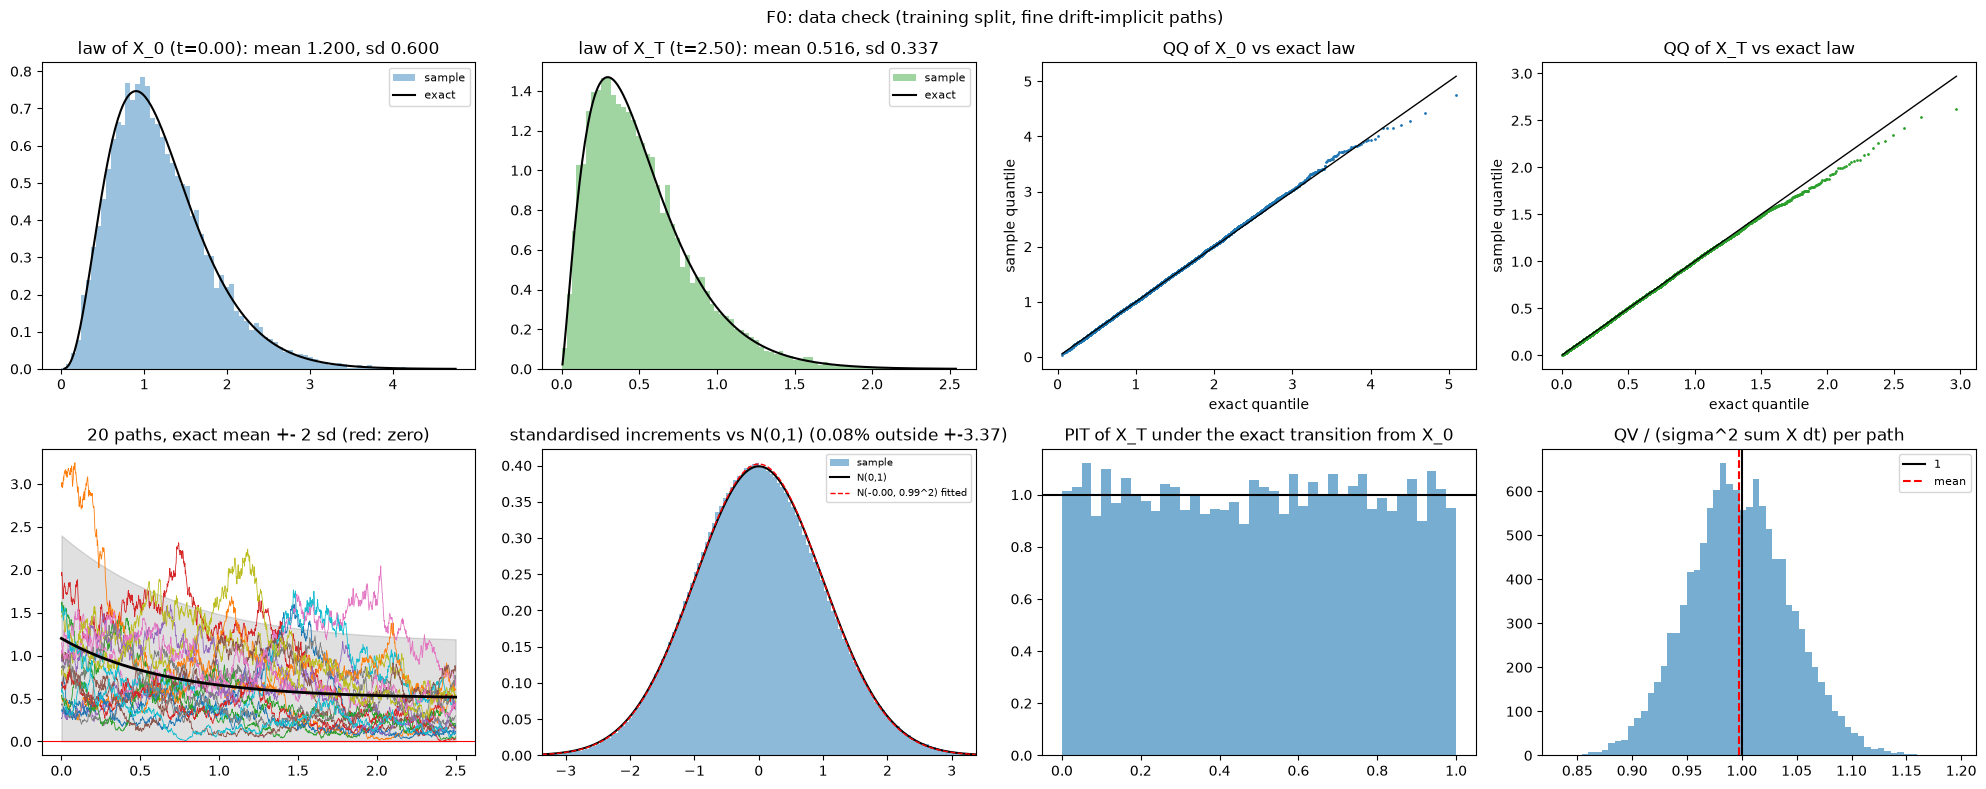

KS0_D=0.009885  KS0_p=0.1902  KST_D=0.006064  KST_p=0.7672  PIT_D=0.006009  PIT_p=0.7768  K2=1291  K2_p=4.917e-281  JB=1296  JB_p=4.232e-282  QV_ratio=0.9976  min_state=0.0004922
regression of X_T on X_0: slope 0.0285 (exact e^(-theta T) = 0.0235), intercept 0.4809 (exact 0.4882)


In [9]:
def law_panels(paths, t_grid, title):
    # paths (P, K+1) on t_grid; the transition PIT is conditional on the first column
    P, K1 = paths.shape
    dt_ = t_grid[1] - t_grid[0]
    dX = np.diff(paths, axis=1)
    xm_ = paths[:, :-1]
    zinc = (dX - THETA * (MU - xm_) * dt_) / (SIGMA * np.sqrt(xm_ * dt_))
    qv = np.sum(dX ** 2, axis=1) / (SIGMA ** 2 * np.sum(xm_, axis=1) * dt_)
    pit = cir_cdf(paths[:, -1], paths[:, 0], t_grid[-1] - t_grid[0])
    fig, ax = plt.subplots(2, 4, figsize=(20, 8))
    ax = ax.ravel()
    pp = (np.arange(1, P + 1) - 0.5) / P
    for j, (k, c, lab) in enumerate(((0, 'C0', '0'), (K1 - 1, 'C2', 'T'))):
        t = t_grid[k]; mt = m_exact(t); sd = np.sqrt(v_exact(t))
        u = np.linspace(max(1e-6, paths[:, k].min()), min(paths[:, k].max(), mt + 6 * sd), 300)
        ax[j].hist(paths[:, k], bins=80, range=(0, u[-1]), density=True, alpha=0.45, color=c, label='sample')
        ax[j].plot(u, marg_pdf(u, t), 'k', lw=1.5, label='exact')
        ax[j].set_title(f'law of X_{lab} (t={t:.2f}): mean {mt:.3f}, sd {sd:.3f}'); ax[j].legend(fontsize=8)
        xs = np.sort(paths[:, k]); qth = marg_ppf(pp, t)
        ax[2 + j].plot(qth, xs, '.', ms=2, color=c); ax[2 + j].plot(qth, qth, 'k-', lw=1)
        ax[2 + j].set_title(f'QQ of X_{lab} vs exact law'); ax[2 + j].set_xlabel('exact quantile'); ax[2 + j].set_ylabel('sample quantile')
    for i in range(min(20, P)):
        ax[4].plot(t_grid, paths[i], lw=0.6)
    ax[4].plot(t_grid, m_exact(t_grid), 'k', lw=2)
    ax[4].fill_between(t_grid, np.maximum(m_exact(t_grid) - 2 * np.sqrt(v_exact(t_grid)), 0),
                       m_exact(t_grid) + 2 * np.sqrt(v_exact(t_grid)), color='k', alpha=0.12)
    ax[4].axhline(0, color='r', lw=0.8); ax[4].set_title('20 paths, exact mean +- 2 sd (red: zero)')
    zz = zinc.ravel()
    zs = zz[:: max(1, zz.size // 2_000_000)]
    lim = max(1.0, 1.2 * float(np.quantile(np.abs(zs), 0.995)))     # zoom on the bulk: central 99.5% of the increments plus a margin
    out_ = np.mean(np.abs(zs) > lim)
    zin = zs[np.abs(zs) <= lim]
    ax[5].hist(zin, bins=120, range=(-lim, lim), density=True, alpha=0.5, label='sample')
    u = np.linspace(-lim, lim, 400); ax[5].plot(u, norm_pdf(u), 'k', label='N(0,1)')
    mz, sz = float(np.mean(zin)), float(np.std(zin))
    ax[5].plot(u, norm_pdf((u - mz) / sz) / sz, 'r--', lw=1, label=f'N({mz:.2f}, {sz:.2f}^2) fitted')
    ax[5].set_xlim(-lim, lim); ax[5].legend(fontsize=7)
    ax[5].set_title(f'standardised increments vs N(0,1) ({100 * out_:.2f}% outside +-{lim:.2f})')
    ax[6].hist(pit, bins=40, range=(0, 1), density=True, alpha=0.6); ax[6].axhline(1, color='k')
    ax[6].set_title('PIT of X_T under the exact transition from X_0')
    ax[7].hist(qv, bins=60, alpha=0.6); ax[7].axvline(1, color='k', label='1'); ax[7].axvline(qv.mean(), color='r', ls='--', label='mean')
    ax[7].set_title('QV / (sigma^2 sum X dt) per path'); ax[7].legend(fontsize=8)
    fig.suptitle(title); fig.tight_layout(); plt.show()
    D0, p0 = ks_test(paths[:, 0], lambda v: marg_cdf(v, t_grid[0]))
    DT_, pT = ks_test(paths[:, -1], lambda v: marg_cdf(v, t_grid[-1]))
    Dp, pp_ = ks_uniform(pit)
    sub_z = zz[:: max(1, zz.size // 1_000_000)]
    K2, pk2 = dagostino_k2(sub_z); JB, pjb = jarque_bera(sub_z)
    out = dict(KS0_D=D0, KS0_p=p0, KST_D=DT_, KST_p=pT, PIT_D=Dp, PIT_p=pp_, K2=K2, K2_p=pk2, JB=JB, JB_p=pjb,
               QV_ratio=float(qv.mean()), min_state=float(paths.min()))
    print('  '.join(f'{k}={v:.4g}' for k, v in out.items()))
    return out

t_fine = np.linspace(0, T_END, N_FINE + 1)
Xf_tr_ = np.array(get('Xf', 'train'))
F0_stats = law_panels(Xf_tr_, t_fine, 'F0: data check (training split, fine drift-implicit paths)')
sl_, ic_ = np.polyfit(Xf_tr_[:, 0], Xf_tr_[:, -1], 1)
print(f'regression of X_T on X_0: slope {sl_:.4f} (exact e^(-theta T) = {np.exp(-THETA * T_END):.4f}), intercept {ic_:.4f} (exact {MU * (1 - np.exp(-THETA * T_END)):.4f})')

## N3 — Legendre coefficients and Chen relations

**What.**

1. Shifted Legendre polynomials $\tilde P_n$ and their primitives $Q_n(x)=\int_0^x\tilde P_n$.

2. The coefficients $I^{(n)}_{s,t}$ of any window of the fine grid, from the fine increments; the fine path is piecewise linear, so the weight of cell $j$ of an $L$-cell window is $L\,[Q_n(\tfrac{j+1}L)-Q_n(\tfrac jL)]$.

3. The normalised coefficients $\hat I_n=I^{(n)}\sqrt{(2n+1)/h}$ that the network receives.

4. The Chen relation for a split at a fraction $\rho$ of the window, with $A_{nm}(\rho)=(2m+1)\int_0^1\tilde P_n(\rho x)\tilde P_m(x)\mathrm dx$:

$$I^{(n)}_{s,t}=\sum_{m\le n}\Bigl(A_{nm}(\rho)\,I^{(m)}_{s,u}+(-1)^{n+m}A_{nm}(1-\rho)\,I^{(m)}_{u,t}\Bigr),\qquad u=s+\rho(t-s).$$

At $\rho=\tfrac12$ this gives $c_{10}=-\tfrac12,\ c_{11}=\tfrac12,\ c_{20}=0,\ c_{21}=-\tfrac34,\ c_{22}=\tfrac14$ (Proposition A.5). Because $m\le n$, the relation is closed for the first $K$ coefficients, which makes the semigroup term well defined for a map that sees only $K$ of them.

5. The polynomial approximation $W^{(N)}_{s,v}=\sum_{n<N}(2n+1)\,I^{(n)}\,Q_n\bigl(\tfrac{v-s}{t-s}\bigr)$.

**Why.** A wrong coefficient is invisible in a loss that only checks outputs.


In [10]:
def leg_val(n, x):
    # shifted Legendre polynomial P~_n(x) = P_n(2x - 1) on [0, 1]
    return Legendre.basis(n)(2.0 * np.asarray(x, float) - 1.0)

def leg_int(n, x):
    # Q_n(x) = int_0^x P~_n(u) du  (Q_n(0) = 0, Q_0(x) = x, Q_n(1) = 0 for n >= 1)
    P = Legendre.basis(n).integ()
    return 0.5 * (P(2.0 * np.asarray(x, float) - 1.0) - P(-1.0))

_WCACHE = {}
def leg_weights(L, K=None):
    # (L, K): weight of fine cell j in the n-th coefficient of an L-cell window (piecewise-linear path)
    K = KC if K is None else K
    key = (L, K)
    if key not in _WCACHE:
        e = np.arange(L + 1) / L
        _WCACHE[key] = np.stack([L * (leg_int(n, e[1:]) - leg_int(n, e[:-1])) for n in range(K)], axis=1)
    return _WCACHE[key]

def hat_scale(h, K=None):
    K = KC if K is None else K
    return np.sqrt((2.0 * np.arange(K) + 1.0) / np.asarray(h, float)[..., None])

def window_coefs(seg, K=None):
    # seg (B, L): fine increments of an L-cell window -> normalised coefficients (B, K)
    K = KC if K is None else K
    L = seg.shape[1]
    return (seg @ leg_weights(L, K)) * hat_scale(L * DT, K)

def coefs_batch(dWf, pi, a, L, K=None):
    # windows [a, a+L) (fine cells) of paths pi; L may differ per row -> grouped by length
    K = KC if K is None else K
    out = np.empty((len(a), K))
    for l in np.unique(L):
        m = np.nonzero(L == l)[0]
        idx = a[m][:, None] + np.arange(l)[None, :]
        out[m] = window_coefs(dWf[pi[m][:, None], idx], K)
    return out

def grid_coefs(dWf, n, K=None):
    # coefficients of every coarse window of the grid n: (P, n, K)
    K = KC if K is None else K
    s = N_FINE // n
    seg = dWf.reshape(dWf.shape[0], n, s)
    return (seg @ leg_weights(s, K)) * hat_scale(T_END / n, K)

# ---- Chen relation for a split at fraction rho ----
_GX, _GW = np.polynomial.legendre.leggauss(12)
_GX, _GW = 0.5 * (_GX + 1.0), 0.5 * _GW                 # nodes/weights on [0, 1]

def chen_A(rho, K=None):
    K = KC if K is None else K
    A = np.zeros((K, K))
    for n in range(K):
        for m in range(n + 1):
            A[n, m] = (2 * m + 1) * np.sum(_GW * leg_val(n, rho * _GX) * leg_val(m, _GX))
    return A

def chen_B(rho, K=None):
    K = KC if K is None else K
    sgn = np.array([[(-1.0) ** (n + m) for m in range(K)] for n in range(K)])
    return sgn * chen_A(1.0 - rho, K)

def chen(I1h, h1, I2h, h2, rho, K=None):
    # normalised coefficients of [s,t] from those of [s,u] (I1h, length h1) and [u,t] (I2h, length h2), rho = h1/(h1+h2)
    K = KC if K is None else K
    nn = np.arange(K)
    r1 = I1h * np.sqrt(np.asarray(h1, float)[..., None] / (2 * nn + 1))
    r2 = I2h * np.sqrt(np.asarray(h2, float)[..., None] / (2 * nn + 1))
    raw = r1 @ chen_A(rho, K).T + r2 @ chen_B(rho, K).T
    return raw * hat_scale(np.asarray(h1, float) + np.asarray(h2, float), K)

**Tests of the coefficients.**

U1: the cell weights reproduce the Gram matrix $\mathrm{diag}(1/(2n+1))$. U2: the Chen constants of Proposition A.5. U3: the Chen relation on the fine data for several splits.

In [11]:
dWf_tr = get('dWf', 'train')
Xf_tr = get('Xf', 'train')
Wg = leg_weights(N_FINE, 5)
gram = (Wg.T @ Wg) / N_FINE
report('U1', np.max(np.abs(gram - np.diag(1.0 / (2 * np.arange(5) + 1.0)))), 1e-5, 'cell weights: Gram matrix -> diag(1/(2n+1)), L = 1200')
A5 = chen_A(0.5, 3)
want = np.array([[1, 0, 0], [-0.5, 0.5, 0], [0, -0.75, 0.25]])
report('U2', np.max(np.abs(A5 - want)), 1e-13, 'Chen constants at rho = 1/2')
rt = rg(777, 3, 200)
pi_ = rt.integers(0, 12000, 500)
worst = 0.0
for (L, L1) in ((8, 4), (8, 2), (240, 120), (240, 60), (1200, 600), (1200, 300)):
    a_ = rt.integers(0, N_FINE - L + 1, 500)
    full = coefs_batch(dWf_tr, pi_, a_, np.full(500, L))
    first = coefs_batch(dWf_tr, pi_, a_, np.full(500, L1))
    second = coefs_batch(dWf_tr, pi_, a_ + L1, np.full(500, L - L1))
    comb = chen(first, np.full(500, L1 * DT), second, np.full(500, (L - L1) * DT), L1 / L)
    worst = max(worst, np.max(np.abs(comb - full)))
report('U3', worst, 1e-12, 'Chen relation: coefficients of a window from its two parts')

U1    cell weights: Gram matrix -> diag(1/(2n+1)), L = 1200              err= 2.31e-06  PASS
U2    Chen constants at rho = 1/2                                        err= 3.33e-16  PASS
U3    Chen relation: coefficients of a window from its two parts         err= 2.30e-13  PASS


### Figure F1 — Legendre coefficients and the polynomial approximation of Brownian motion

**Before.** Four panels on the training paths. (1) One Brownian path on $[0,T]$ and its approximations $W^{(N)}$, $N=1,2,3,5,10$. (2) The mean-square error of $W^{(N)}$ at the midpoint and averaged over the window, empirical (12000 paths) against the exact formula $h\,[x-\sum_{n<N}(2n+1)Q_n(x)^2]$. (3) QQ plot of $\hat I_0,\dots,\hat I_3$ of the whole window against $N(0,1)$. (4) The correlation matrix of $\hat I_0,\dots,\hat I_4$.

**Why.** The map receives these coefficients: their law should be the one of the theory, and the speed at which $N$ coefficients capture the path is what limits any map of $K$ of them.

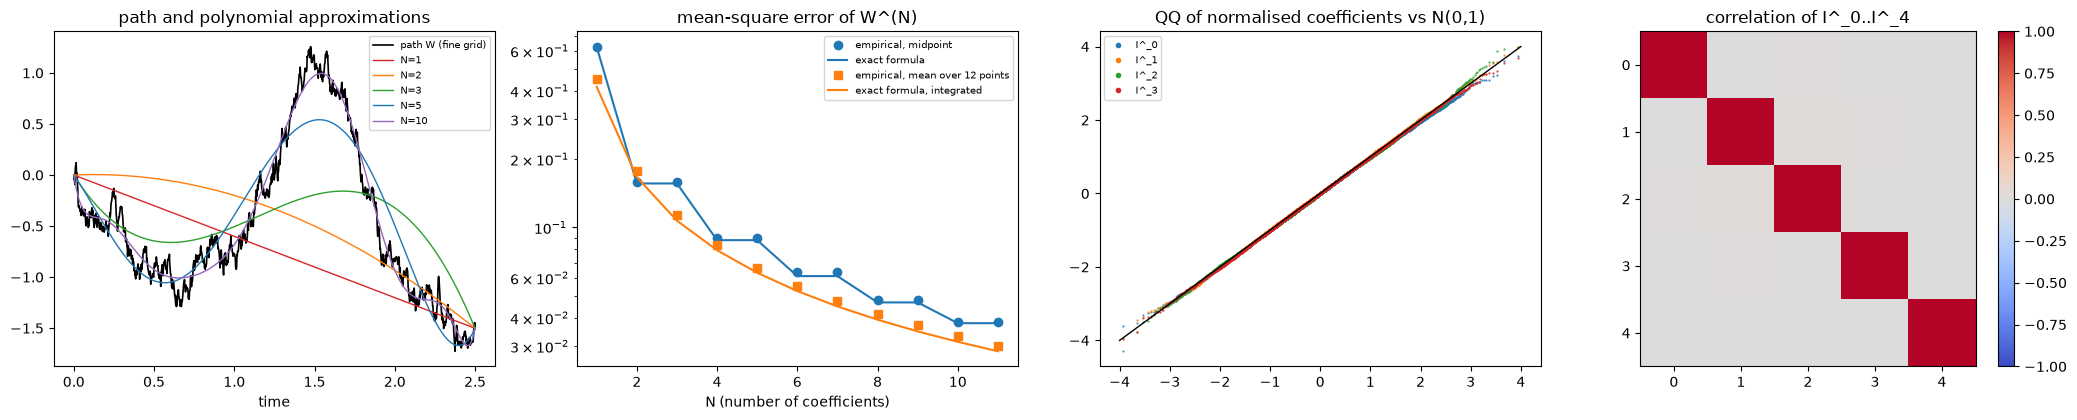

max |off-diagonal correlation| = 0.0196  (3/sqrt(P) = 0.0274)
  I^_0: mean -0.0103  var 0.9853  KS D=0.0073 p=0.535
  I^_1: mean  0.0121  var 1.0067  KS D=0.0088 p=0.313
  I^_2: mean -0.0081  var 0.9963  KS D=0.0080 p=0.421
  I^_3: mean -0.0039  var 1.0032  KS D=0.0053 p=0.890
midpoint error of W^(3): empirical 0.15867, formula 0.15625


In [12]:
NF = 11
Wall = leg_weights(N_FINE, NF)
Iall = dWf_tr @ Wall                                        # raw coefficients of [0, T], all training paths (12000, NF)
Ihat_all = Iall * hat_scale(T_END, NF)
xg = np.arange(N_FINE + 1) / N_FINE
Wpath = np.concatenate([[0.0], np.cumsum(dWf_tr[0])])
def W_approx(Iraw, N, x):
    return sum((2 * n + 1) * Iraw[n] * leg_int(n, x) for n in range(N))
_QX, _QW = np.polynomial.legendre.leggauss(24)
_QX, _QW = 0.5 * (_QX + 1.0), 0.5 * _QW
fig, ax = plt.subplots(1, 4, figsize=(21, 4.3))
ax[0].plot(xg * T_END, Wpath, 'k', lw=1.2, label='path W (fine grid)')
for N_, c_ in zip((1, 2, 3, 5, 10), ('C3', 'C1', 'C2', 'C0', 'C4')):
    ax[0].plot(xg * T_END, W_approx(Iall[0], N_, xg), color=c_, lw=1, label=f'N={N_}')
ax[0].set_title('path and polynomial approximations'); ax[0].set_xlabel('time'); ax[0].legend(fontsize=7)
Ns = np.arange(1, NF + 1)
emp_mid, th_mid, emp_int, th_int = [], [], [], []
cs = np.concatenate([np.zeros((12000, 1)), np.cumsum(dWf_tr, axis=1)], axis=1)
xm = 0.5
for N_ in Ns:
    wp = sum((2 * n + 1) * Iall[:, n] * leg_int(n, xm) for n in range(N_))
    Wm = dWf_tr[:, :N_FINE // 2].sum(1)
    emp_mid.append(np.mean((Wm - wp) ** 2))
    th_mid.append(T_END * (xm - sum((2 * n + 1) * leg_int(n, xm) ** 2 for n in range(N_))))
    th_int.append(T_END * np.sum(_QW * (_QX - sum((2 * n + 1) * leg_int(n, _QX) ** 2 for n in range(N_)))))
    pts = np.arange(1, 13) / 13.0
    errs = []
    for p_ in pts:
        jj = int(round(p_ * N_FINE))
        wp2 = sum((2 * n + 1) * Iall[:, n] * leg_int(n, jj / N_FINE) for n in range(N_))
        errs.append(np.mean((cs[:, jj] - wp2) ** 2))
    emp_int.append(np.mean(errs))
ax[1].semilogy(Ns, emp_mid, 'o', color='C0', label='empirical, midpoint'); ax[1].semilogy(Ns, th_mid, '-', color='C0', label='exact formula')
ax[1].semilogy(Ns, emp_int, 's', color='C1', label='empirical, mean over 12 points'); ax[1].semilogy(Ns, th_int, '-', color='C1', label='exact formula, integrated')
ax[1].set_title('mean-square error of W^(N)'); ax[1].set_xlabel('N (number of coefficients)'); ax[1].legend(fontsize=7)
pp = (np.arange(1, 12001) - 0.5) / 12000
for n, c_ in zip(range(4), ('C0', 'C1', 'C2', 'C3')):
    ax[2].plot(norm_ppf(pp), np.sort(Ihat_all[:, n]), '.', ms=1, color=c_, label=f'I^_{n}')
ax[2].plot([-4, 4], [-4, 4], 'k', lw=1); ax[2].set_title('QQ of normalised coefficients vs N(0,1)'); ax[2].legend(fontsize=7, markerscale=6)
Cm = np.corrcoef(Ihat_all[:, :5].T)
im = ax[3].imshow(Cm, vmin=-1, vmax=1, cmap='coolwarm'); ax[3].set_title('correlation of I^_0..I^_4'); plt.colorbar(im, ax=ax[3])
fig.tight_layout(); plt.show()
off = np.max(np.abs(Cm - np.eye(5)))
print(f'max |off-diagonal correlation| = {off:.4f}  (3/sqrt(P) = {3 / np.sqrt(12000):.4f})')
for n in range(4):
    D_, p_ = ks_normal(Ihat_all[:, n], 0.0, 1.0)
    print(f'  I^_{n}: mean {Ihat_all[:, n].mean(): .4f}  var {Ihat_all[:, n].var():.4f}  KS D={D_:.4f} p={p_:.3f}')
print(f'midpoint error of W^(3): empirical {emp_mid[2]:.5f}, formula {th_mid[2]:.5f}')

**After F1.** The coefficients are Gaussian, uncorrelated and of unit variance, and the error of $W^{(N)}$ follows the exact formula. Nothing in this figure depends on the process.

## N4 — The multiplicative map $\Psi_\nu$ and its hand-written gradients

The map of §0.5. PG , both with inputs $(z,\hat I_{0..K-1},\sqrt h)$, $z=8\tanh(\log(x/\mu)/8)$. Psi_fwd returns the value and a cache. Psi_bwd the parameter gradient for an upstream gradient and $\mathrm dL/\mathrm dx$.

$$\partial_x\Psi=e^{E}\Bigl(1+\bigl(1-\tanh^2(\tilde E/c)\bigr)\bigl(h\,\partial_zM^{(1)}+w\,\partial_zM^{(2)}\bigr)\,x\,z'(x)\Bigr),\qquad x\,z'(x)=1-\tanh^2\bigl(\log(x/\mu)/8\bigr),$$

by a forward tangent pass along the $z$-input. The last layer of each head is multiplied by $0.1$ at initialisation, so $\Psi\approx\mathrm{id}$ at the start.

### The perceptron routines

**What comes next::** Initialisation, forward pass, reverse pass (parameter and input gradient) and a forward tangent pass, for SiLU networks with a linear last layer.



In [13]:
def mlp_init(sizes, rng):
    P = []
    for i in range(len(sizes) - 1):
        lim = np.sqrt(6.0 / (sizes[i] + sizes[i + 1]))
        W = rng.uniform(-lim, lim, size=(sizes[i], sizes[i + 1]))
        c = np.zeros(sizes[i + 1])
        P.append([W, c])
    return P

def mlp_forward(P, A0):
    # forward pass; returns output and the cache (inputs of each layer, pre-activations)
    a = A0
    As, zs = [A0], []
    L = len(P)
    for l in range(L):
        W, c = P[l]
        z = a @ W + c
        zs.append(z)
        a = silu(z) if l < L - 1 else z
        As.append(a)
    return a, (As, zs)

def mlp_backward(P, cache, gout):
    # reverse pass: parameter gradients and gradient with respect to the input
    As, zs = cache
    L = len(P)
    grads = [None] * L
    g = gout
    for l in reversed(range(L)):
        W, c = P[l]
        gz = g if l == L - 1 else g * silu_d1(zs[l])
        grads[l] = [As[l].T @ gz, gz.sum(0)]
        g = gz @ W.T
    return grads, g

def mlp_tangent(P, A0, seed):
    # forward pass with a first-order tangent (directional derivative along `seed` in input space)
    a = A0
    s = np.tile(np.asarray(seed, float), (A0.shape[0], 1))
    L = len(P)
    for l in range(L):
        W, c = P[l]
        z = a @ W + c
        t = s @ W
        if l < L - 1:
            s = silu_d1(z) * t
            a = silu(z)
        else:
            s = t
            a = z
    return a, s

In [14]:
def Psi_init():
    r = rg(777, 13)
    PG = {'F': mlp_init([KC + 2] + [NET_W] * NET_D + [1], r), 'g': mlp_init([KC + 2] + [NET_W] * NET_D + [1], r)}
    for k in PG:
        PG[k][-1][0] *= 0.1
    return PG

def state_feature(x):
    # z = ZC tanh(log(x / mu) / ZC) and its derivative dz/dx
    t = np.tanh(np.log(x / MU) / ZC)
    return ZC * t, (1.0 - t * t) / x

def _inputs(x, Ih, h):
    h = np.broadcast_to(np.asarray(h, float), x.shape)
    sh = np.sqrt(h)
    return np.column_stack([state_feature(x)[0], Ih[:, :KC], sh]), h, sh

def Psi_fwd(PG, x, Ih, h):
    # Psi = x exp(E),  E = c tanh(E~ / c),  E~ = h M1(z, I, sqrt h) + w M2(z, I, sqrt h),  w = I_0 sqrt h,  z = state_feature(x)
    X_in, h, sh = _inputs(x, Ih, h)
    oF, cF = mlp_forward(PG['F'], X_in)
    og, cg = mlp_forward(PG['g'], X_in)
    w = Ih[:, 0] * sh
    th = np.tanh((h * oF[:, 0] + w * og[:, 0]) / LOGCAP)
    ex = np.exp(LOGCAP * th)
    out = x * ex
    return out, (cF, cg, h, w, x, ex, th, out)

def Psi_bwd(PG, cache, gout):
    cF, cg, h, w, x, ex, th, out = cache
    gE = gout * out * (1.0 - th * th)                    # dL / dE~
    gF, gxF = mlp_backward(PG['F'], cF, (h * gE)[:, None])
    gg, gxg = mlp_backward(PG['g'], cg, (w * gE)[:, None])
    dx = gout * ex + (gxF[:, 0] + gxg[:, 0]) * state_feature(x)[1]     # direct factor exp(E), plus the path through z
    return {'F': gF, 'g': gg}, dx

def Psi(PG, x, Ih, h):
    return Psi_fwd(PG, x, Ih, h)[0]

def Psi_dx(PG, x, Ih, h):
    X_in, h, sh = _inputs(x, Ih, h)
    seed = [1.0] + [0.0] * (KC + 1)
    oF, sF = mlp_tangent(PG['F'], X_in, seed)
    og, sg = mlp_tangent(PG['g'], X_in, seed)
    w = Ih[:, 0] * sh
    th = np.tanh((h * oF[:, 0] + w * og[:, 0]) / LOGCAP)
    return np.exp(LOGCAP * th) * (1.0 + (1.0 - th * th) * (h * sF[:, 0] + w * sg[:, 0]) * x * state_feature(x)[1])

def Psi_heads(PG, x, Ih, h):
    X_in, _, _ = _inputs(x, Ih, h)
    return mlp_forward(PG['F'], X_in)[0][:, 0], mlp_forward(PG['g'], X_in)[0][:, 0]

def tree_P_check_nets(seed_id, scale=0.5):
    r = rg(777, 3, seed_id)
    PG = {'F': mlp_init([KC + 2] + [NET_W] * NET_D + [1], r), 'g': mlp_init([KC + 2] + [NET_W] * NET_D + [1], r)}
    for k in PG:
        for l in range(len(PG[k])):
            PG[k][l][1] = r.normal(0, 0.1, PG[k][l][1].shape)
        PG[k][-1][0] *= scale
    return PG

print('parameters of Psi:', n_params(Psi_init()))
sub_rows = np.arange(0, 12000, 4)
for L in LV:
    lr_ = np.abs(np.log(Xf_tr[sub_rows, L:] / Xf_tr[sub_rows, :-L]))
    print(f'  windows of {L:4d} cells: largest |log(X_t / X_s)| = {lr_.max():.3f}, 99.99% quantile {np.quantile(lr_, 0.9999):.3f}   (cap {LOGCAP})')

parameters of Psi: 17922
  windows of    2 cells: largest |log(X_t / X_s)| = 2.463, 99.99% quantile 0.743   (cap 10.0)
  windows of    8 cells: largest |log(X_t / X_s)| = 3.158, 99.99% quantile 1.418   (cap 10.0)
  windows of   24 cells: largest |log(X_t / X_s)| = 4.399, 99.99% quantile 2.215   (cap 10.0)
  windows of   48 cells: largest |log(X_t / X_s)| = 4.597, 99.99% quantile 2.725   (cap 10.0)
  windows of   80 cells: largest |log(X_t / X_s)| = 5.344, 99.99% quantile 3.202   (cap 10.0)
  windows of  240 cells: largest |log(X_t / X_s)| = 6.191, 99.99% quantile 4.019   (cap 10.0)
  windows of  480 cells: largest |log(X_t / X_s)| = 6.868, 99.99% quantile 4.522   (cap 10.0)
  windows of 1200 cells: largest |log(X_t / X_s)| = 4.791, 99.99% quantile 4.724   (cap 10.0)


### Tests of the map (T-P1 to T-P3)

 T-P1: the parameter gradient of $\sum a\,\Psi$ against finite differences for both heads, and $\partial_x\Psi$ (tangent pass) against central differences. 
 
 T-P2: the input gradient dx of Psi_bwd, and $\Psi=x$ when the last layers vanish. 
 
 T-P3: for large random weights and states from $10^{-6}$ to $10^{2}$, $\Psi$ is finite, positive and $|\log(\Psi/x)|\le c$.

**Why.** These are the building blocks of every loss. Actually, T-P3 is the guarantee that a chain of map calls cannot reach zero or explode.


In [15]:
TG_ = tree_P_check_nets(0)
rt = rg(777, 3, 300)
xq = np.exp(rt.normal(np.log(0.5), 0.8, 64)); Iq = rt.normal(size=(64, KC)); hq = np.exp(rt.uniform(np.log(0.01), np.log(2.5), 64)); aq = rt.normal(size=64)
f_ = lambda T: float(np.sum(aq * Psi(T, xq, Iq, hq)))
_, cc = Psi_fwd(TG_, xq, Iq, hq)
gq, dxq = Psi_bwd(TG_, cc, aq)
report('T-P1', fd_check(f_, TG_, gq, (777, 3, 301)), PASS_LEVEL, 'Psi: parameter gradient (both heads)')
def fx(e):
    return Psi(TG_, xq * (1 + e), Iq, hq)
Dx = lambda e: (fx(e) - fx(-e)) / (2 * e * xq)
fd = (4 * Dx(5e-5) - Dx(1e-4)) / 3
report('T-P1', np.max(np.abs(Psi_dx(TG_, xq, Iq, hq) - fd) / (np.abs(fd) + 1e-12)), PASS_LEVEL, 'dPsi/dx (tangent pass) vs central differences')
fdx = aq * fd
report('T-P2', np.max(np.abs(dxq - fdx) / (np.abs(fdx) + 1e-12)), PASS_LEVEL, 'input gradient dx of Psi_bwd vs central differences')
P0 = Psi_init()
for k in P0:
    P0[k][-1][0][:] = 0.0
report('T-P2', np.max(np.abs(Psi(P0, xq, Iq, hq) - xq) / xq), 1e-14, 'Psi = identity when the last layers are zero')
Tbig = tree_P_check_nets(9, scale=50.0)
xe = np.logspace(-6, 2, 400); Ie = rt.normal(0, 4, size=(400, KC)); he = np.full(400, T_END)
pe = Psi(Tbig, xe, Ie, he)
ok_ = np.all(np.isfinite(pe)) and np.all(pe > 0)
report('T-P3', 0.0 if ok_ else 1.0, 0.5, 'Psi finite and positive for large weights and extreme states')
report('T-P3', max(0.0, np.max(np.abs(np.log(pe / xe))) - LOGCAP), 1e-12, '|log(Psi / x)| <= cap')

T-P1  Psi: parameter gradient (both heads)                               err= 5.36e-08  PASS
T-P1  dPsi/dx (tangent pass) vs central differences                      err= 5.16e-12  PASS
T-P2  input gradient dx of Psi_bwd vs central differences                err= 5.16e-12  PASS
T-P2  Psi = identity when the last layers are zero                       err= 0.00e+00  PASS
T-P3  Psi finite and positive for large weights and extreme states       err= 0.00e+00  PASS
T-P3  |log(Psi / x)| <= cap                                              err= 0.00e+00  PASS


## N5 — Training the forward map with the SSFM objective

### N5.1 Windows, validation sets and rulers

**What.** A window is a pair of fine-grid indices $(a,a+L)$ on one path: input $x=X_a$, the $K$ normalised coefficients of the fine increments inside the window, length $h=L\,\mathrm dt$, target $x_t=X_{a+L}$. build_windows draws a fixed set of windows for each $L\in\{2,8,24,48,80,240,480,1200\}$. The **score** of a map is the rms of $(\Psi-x_t)/\mathrm{sd}(X_t)$ at each length, averaged over the lengths ("1" means "no better than knowing the law of $X_t$"). The ruler at each length is the identity $\Psi(x)=x$.

**Why.** One fixed validation set gives the training curves a common axis; the identity is the "do nothing" error.

**Expect.** The identity score grows with $h$.

In [16]:
NTR = SPLITS['train'][1] - SPLITS['train'][0]

def build_windows(split, nwin, key, Ls=LV):
    g = rg(*key)
    Xf, dWf = get('Xf', split), get('dWf', split)
    out = {}
    for L in Ls:
        pi = g.integers(0, Xf.shape[0], nwin)
        a = g.integers(0, N_FINE - L + 1, nwin)
        out[L] = dict(pi=pi, a=a, x=Xf[pi, a], xt=Xf[pi, a + L], Ih=coefs_batch(dWf, pi, a, np.full(nwin, L)),
                      h=L * DT, sd=np.sqrt(v_exact((a + L) * DT)), L=L)
    return out

def std_rmse(PG, W):
    return np.array([np.sqrt(np.mean(((Psi(PG, W[L]['x'], W[L]['Ih'], W[L]['h']) - W[L]['xt']) / W[L]['sd']) ** 2)) for L in W])

def ruler_identity(W):
    return np.array([np.sqrt(np.mean(((W[L]['x'] - W[L]['xt']) / W[L]['sd']) ** 2)) for L in W])

VAL = build_windows('val', N_VAL, (777, 60))
RUL_ID = ruler_identity(VAL)
HV = np.array([L * DT for L in LV])
show(pd.DataFrame({'h': HV, 'identity score': RUL_ID}, index=[f'L={L}' for L in LV]).T)

,L=2,L=8,L=24,L=48,L=80,L=240,L=480,L=1200
h,0.004167,0.01667,0.05,0.1,0.1667,0.5,1,2.5
identity score,0.1024,0.212,0.3435,0.4984,0.6165,1.093,1.513,2.871


### N5.2 Samplers


* **Tangent sample.** A window of $L\in\{1,2,3,4\}$ fine cells on a random training path at a random time. 
 input $X_s$ and the coefficients of the observed increments; target the observed $X_t$. A share TAN_LOW_SHARE $=25\%$ of the windows start at a state below the $5\%$ quantile (§0.6).

* **Semigroup sample.** A window of $L$ fine cells, $L$ even and uniform on $\{4,6,\dots,1200\}$ (no curriculum), and its two halves. The three coefficient vectors come from the same observed increments, so the Chen relation holds by construction (U3). No target is used.


In [17]:
def _windows(g, B, Ls):
    # random training path, window length from Ls (fine cells), window start a in [0, N_FINE - L]
    pi = g.integers(0, NTR, B)
    L = Ls[g.integers(0, len(Ls), B)]
    a = (g.random(B) * (N_FINE + 1 - L)).astype(int)
    return pi, a, L

LS_COC = 2 * np.arange(max(1, (L_TAN + 1) // 2), N_FINE // 2 + 1)   # even window lengths 4, 6, ..., 1200

def sample_coc(g, B):
    pi, a, L = _windows(g, B, LS_COC)
    x = Xf_tr[pi, a]
    Ih = coefs_batch(dWf_tr, pi, a, L)
    I1 = coefs_batch(dWf_tr, pi, a, L // 2)               # earlier half [a, a + L/2)
    I2 = coefs_batch(dWf_tr, pi, a + L // 2, L // 2)      # later half   [a + L/2, a + L)
    return x, Ih, I1, I2, L * DT

_Q_LOW = np.quantile(Xf_tr[:, ::10], LOW_Q)
LOW_PI, LOW_A = np.nonzero(Xf_tr[:, :N_FINE - L_TAN + 1] < _Q_LOW)       # windows that start at a low state

def sample_tan(g, B):
    pi, a, L = _windows(g, B, np.arange(1, L_TAN + 1))
    m = int(TAN_LOW_SHARE * B)
    if m > 0:
        j = g.integers(0, len(LOW_PI), m)
        pi[:m], a[:m] = LOW_PI[j], LOW_A[j]
    return Xf_tr[pi, a], coefs_batch(dWf_tr, pi, a, L), L * DT, Xf_tr[pi, a + L]

### N5.3 The losses and their gradients

1) $\mathcal L_{\rm tan}=\mathbb E\bigl[(\Psi(x,\hat I,h)-x^{\rm target})^2/(h\,x)\bigr]$ over the tangent sub-batch.
2) $\mathcal L_{\rm coc}=\mathbb E\bigl[(\Psi(x,\hat I,h)-\mathrm{sg}[\Psi_{\rm ema}(\Psi_{\rm ema}(x,\hat I^{(1)},\tfrac h2),\hat I^{(2)},\tfrac h2)])^2/(h\,x)\bigr]$ over the semigroup sub-batch, the teacher being the EMA weights applied twice with stop-gradient.

* The joint gradient $\eta\nabla\mathcal L_{\rm tan}+(1-\eta)\nabla\mathcal L_{\rm coc}$, $\eta=0.75$.

In [18]:
def loss_tan(PG, x, Ih, h, tgt):
    out, cache = Psi_fwd(PG, x, Ih, h)
    r = out - tgt
    wgt = 1.0 / (h * x)
    grads, _ = Psi_bwd(PG, cache, 2.0 * r * wgt / len(x))
    return float(np.mean(r ** 2 * wgt)), grads

def coc_teacher(PG, x, I1, I2, h):
    # composition of the two half-window maps: earlier half first, then the later half
    xu = Psi(PG, x, I1, h / 2)
    return Psi(PG, xu, I2, h / 2)

def loss_coc(PG, x, Ih, I1, I2, h, teacher):
    out, cache = Psi_fwd(PG, x, Ih, h)
    r = out - teacher
    wgt = 1.0 / (h * x)
    grads, _ = Psi_bwd(PG, cache, 2.0 * r * wgt / len(x))
    return float(np.mean(r ** 2 * wgt)), grads

def joint_grad(g_tan, g_coc):
    return tree_add(tree_scale(g_tan, ETA), g_coc, 1.0 - ETA)

TGn = tree_P_check_nets(1)
x_, I_, h_, t_ = sample_tan(rg(777, 3, 311), 48)
report('T-L1', fd_check(lambda T: loss_tan(T, x_, I_, h_, t_)[0], TGn, loss_tan(TGn, x_, I_, h_, t_)[1], (777, 3, 312), scale_rel=True),
       PASS_LEVEL, 'tangent loss gradient')
x2_, I2h_, I1_, I2_, h2_ = sample_coc(rg(777, 3, 313), 48)
teach = coc_teacher(tree_P_check_nets(2), x2_, I1_, I2_, h2_)
report('T-L1', fd_check(lambda T: loss_coc(T, x2_, I2h_, I1_, I2_, h2_, teach)[0], TGn, loss_coc(TGn, x2_, I2h_, I1_, I2_, h2_, teach)[1], (777, 3, 314), scale_rel=True),
       PASS_LEVEL, 'semigroup loss gradient (teacher held fixed)')
jv = lambda T: ETA * loss_tan(T, x_, I_, h_, t_)[0] + (1 - ETA) * loss_coc(T, x2_, I2h_, I1_, I2_, h2_, teach)[0]
jg = joint_grad(loss_tan(TGn, x_, I_, h_, t_)[1], loss_coc(TGn, x2_, I2h_, I1_, I2_, h2_, teach)[1])
report('T-L1', fd_check(jv, TGn, jg, (777, 3, 315), scale_rel=True), PASS_LEVEL, 'joint gradient')

T-L1  tangent loss gradient                                              err= 1.64e-09  PASS
T-L1  semigroup loss gradient (teacher held fixed)                       err= 6.21e-12  PASS
T-L1  joint gradient                                                     err= 2.51e-10  PASS


### N5.4 Training, validation, freezing

In [19]:
def val_fn_G(A):
    return float(np.mean(std_rmse(arrays_to_tree(A, ['F', 'g']), VAL)))

def cosine_lr_s(it, n_it):
    # optax.cosine_decay_schedule(1e-3, n_it, alpha = 1e-5 / 1e-3)
    return LR_S_MIN + 0.5 * (LR_S - LR_S_MIN) * (1 + np.cos(np.pi * it / max(n_it, 1)))

def ema_step(E, M, it):
    d = min(EMA_S, (1.0 + it) / (10.0 + it)) if EMA_WARMUP else EMA_S
    return tree_add(tree_scale(E, d), M, 1.0 - d)

def train_ssfm(n_it, B, label=''):
    P0 = Psi_init()
    M, ema, st = tree_copy(P0), tree_copy(P0), adam_init(P0)
    n_tan = int(ETA * B)
    n_coc = B - n_tan
    log = {k: [] for k in ('loss', 'L_tan', 'L_coc', 'gnorm', 'lr', 'sec')}
    vlog = {'it': [], 'score': [], 'rmse': [], 'se': []}
    t_start = time.time()
    for it in range(n_it):
        t0 = time.time()
        x, Ih, h, tgt = sample_tan(rg(777, 40, it), n_tan)
        Lt, g_t = loss_tan(M, x, Ih, h, tgt)
        x, Ih, I1, I2, h = sample_coc(rg(777, 42, it), n_coc)
        Lc, g_c = loss_coc(M, x, Ih, I1, I2, h, coc_teacher(ema, x, I1, I2, h))
        if not np.isfinite(Lt + Lc):
            raise RuntimeError(f'{label}: non-finite loss at iteration {it} (tangent {Lt}, semigroup {Lc}); nothing is frozen')
        grad, gn = clip_tree(joint_grad(g_t, g_c), CLIP_S)
        lr = cosine_lr_s(it, n_it)
        M = adam_step(M, grad, st, lr)
        ema = ema_step(ema, M, it)
        for k, v in (('loss', ETA * Lt + (1 - ETA) * Lc), ('L_tan', Lt), ('L_coc', Lc), ('gnorm', gn), ('lr', lr), ('sec', time.time() - t0)):
            log[k].append(v)
        if it % VAL_EVERY == 0 or it == n_it - 1:
            r_ = std_rmse(ema, VAL)
            vlog['it'].append(it); vlog['score'].append(float(np.mean(r_))); vlog['rmse'].append(r_)
            vlog['se'].append(strong_val(ema))
        if (it + 1) % max(1, n_it // 10) == 0:
            print(f'  {label} it {it + 1:6d}/{n_it}  batch tangent {Lt:.3e}  semigroup {Lc:.3e}  val score {vlog["score"][-1]:.4f}  val strong error {vlog["se"][-1]:.4f}  ({time.time() - t_start:.0f}s)', flush=True)
    return ema, {k: np.array(v) for k, v in log.items()}, {k: np.array(v) for k, v in vlog.items()}

def train_or_load(mid, n_it, B):
    reg = read_registry()
    lp = os.path.join(RES_DIR, 'log_' + mid + '.npz')
    if mid in reg and not OVERWRITE_FROZEN and os.path.exists(reg[mid]['file']) and os.path.exists(lp):
        PG = arrays_to_tree(load_frozen(mid), ['F', 'g'])
        Z = np.load(lp)
        log = {k[2:]: Z[k] for k in Z.files if k.startswith('t_')}
        vlog = {k[2:]: Z[k] for k in Z.files if k.startswith('v_')}
        print(f'{mid}: loaded the frozen model (set OVERWRITE_FROZEN = True to retrain)')
        return PG, log, vlog
    t0 = time.time()
    PG, log, vlog = train_ssfm(n_it, B, label=mid)
    np.savez(lp, **{'t_' + k: v for k, v in log.items()}, **{'v_' + k: v for k, v in vlog.items()})
    freeze(mid, tree_to_arrays(PG), dict(params=n_params(PG), iterations=n_it, batch=B, eta=ETA, ema=EMA_S, ema_warmup=EMA_WARMUP, zc=ZC, tan_low_share=TAN_LOW_SHARE,
                                         lr=[LR_S, LR_S_MIN], clip=CLIP_S, logcap=LOGCAP, streams=['[777,13]', '[777,40,it]', '[777,42,it]'],
                                         val_score=float(vlog['score'][-1]), sec_per_it=float(np.mean(log['sec']))), val_fn_G)
    print(f'{mid} trained in {time.time() - t0:.0f}s')
    return PG, log, vlog

def running_mean(v, k=50):
    k = max(1, min(k, len(v)))
    return np.convolve(v, np.ones(k) / k, mode='valid')

def plot_G_training(log, vlog, title):
    fig, ax = plt.subplots(2, 3, figsize=(19, 8))
    ax = ax.ravel()
    k = max(1, len(log['loss']) // 40)
    ax[0].semilogy(running_mean(log['loss'], k), label='joint (0.75 tangent + 0.25 semigroup)', lw=1.3)
    ax[0].semilogy(running_mean(log['L_tan'], k), label='tangent term', lw=1)
    ax[0].semilogy(running_mean(np.maximum(log['L_coc'], 1e-300), k), label='semigroup term', lw=1)
    ax[0].set_title('batch losses (running mean)'); ax[0].set_xlabel('iteration'); ax[0].legend(fontsize=7)
    ax[1].semilogy(vlog['it'], vlog['score'], 'o-', ms=3, label='validation score')
    ax[1].axhline(np.mean(RUL_ID), color='grey', ls=':', lw=1, label='identity')
    ax[1].set_title('validation score (EMA weights)'); ax[1].set_xlabel('iteration'); ax[1].legend(fontsize=8)
    R = np.array(vlog['rmse'])
    for j, L in enumerate(LV):
        ax[2].semilogy(vlog['it'], R[:, j], lw=1, label=f'h={L * DT:.3g}')
    ax[2].set_title('validation error by window length'); ax[2].set_xlabel('iteration'); ax[2].legend(fontsize=7, ncol=2)
    ax[3].semilogy(vlog['it'], vlog['se'], 'o-', ms=3, label='map')
    ax[3].set_title('validation strong error (n = 20..50)'); ax[3].set_xlabel('iteration'); ax[3].legend(fontsize=8)
    ax[4].semilogy(log['gnorm'], lw=0.5, label='gradient norm (before clipping)'); ax[4].axhline(CLIP_S, color='r', ls='--', lw=0.8, label=f'clip {CLIP_S:g}')
    ax[4].set_title('gradient norm'); ax[4].set_xlabel('iteration'); ax[4].legend(fontsize=7)
    ax[5].plot(log['lr']); ax[5].set_title('learning rate'); ax[5].set_xlabel('iteration')
    for a_ in ax:
        a_.set_xlim(0, len(log['loss']))
    fig.suptitle(title); fig.tight_layout(); plt.show()

### N5.4b Strong error: reconstruction of $X_T$ from $X_0$ by a chain of map calls
 The score is

* the **strong error** $\mathrm{SE}=\frac16\sum_{n\in\{20,24,25,30,40,50\}}\varepsilon_n$, $\ \varepsilon_n=\sqrt{\mathbb E(\hat Z_n-X_T)^2}/\mathrm{sd}(X_T)$;

The expectation is over all paths of the split.

In [20]:
def chained_recon(P_, split, n, rows=None, gfun=None):
    # Z_0 = X_0, Z_(k+1) = Psi(Z_k, I_[t_k, t_(k+1)], T / n); P_ = weights of the map, or gfun(x, Ih, h)
    x, Ig = get('x', split, n), get('Ih', split, n)
    if rows is not None:
        x, Ig = x[rows], Ig[rows]
    g_ = gfun if gfun is not None else (lambda s, I, h: Psi(P_, s, I, h))
    Z = np.empty_like(x)
    Z[:, 0] = x[:, 0]
    for k in range(n):
        Z[:, k + 1] = g_(Z[:, k], Ig[:, k, :], T_END / n)
    return Z

def recon_stats(P_, split, gfun=None, ns=None):
    # standardised rms error at t = T and averaged over the nodes t_1 .. t_n, all paths of the split
    ns = NS_TAB if ns is None else ns
    out = {}
    for n_ in ns:
        x = get('x', split, n_)
        Z = chained_recon(P_, split, n_, gfun=gfun)
        sd_ = np.sqrt(v_exact(np.arange(n_ + 1) * T_END / n_))
        e_ = np.sqrt(np.mean((Z - x) ** 2, axis=0)) / sd_
        out[n_] = (float(e_[-1]), float(np.mean(e_[1:])))
    return out

def strong_of(st):
    return float(np.mean([st[n_][0] for n_ in NS_AVG]))

def strong_sq(P_, split, gfun=None):
    # per-path squared standardised error of the reconstructed X_T for every n in NS_AVG: (len(NS_AVG), P)
    sdT = np.sqrt(v_exact(T_END))
    rows = []
    for n_ in NS_AVG:
        x = get('x', split, n_)
        Z = chained_recon(P_, split, n_, gfun=gfun)
        rows.append(((Z[:, -1] - x[:, -1]) / sdT) ** 2)
    return np.array(rows)

def strong_val(P_, gfun=None):
    return float(np.mean(np.sqrt(strong_sq(P_, 'val', gfun).mean(axis=1))))

def recon_table(P_, split, label):
    st = recon_stats(P_, split)
    print(f'standardised rms error of the reconstructed X_T (row X_T) and mean over the nodes (row nodes); {split} split, chains on [0, T] from X_0')
    print(f'{"n intervals":30s}' + ''.join(f'{n_:>8d}' for n_ in NS_TAB) + '   | strong error (n = 20..50)')
    for nm, s_ in ((label[:22], st),):
        print(f'{nm:22s} {"X_T":>7s}' + ''.join(f'{s_[n_][0]:8.3f}' for n_ in NS_TAB) + f'   | {strong_of(s_):8.4f}')
        print(f'{"":22s} {"nodes":>7s}' + ''.join(f'{s_[n_][1]:8.3f}' for n_ in NS_TAB))
    return st

def recon_fig(P_, split, title, pi=0):
    Xf = get('Xf', split); tt = np.arange(N_FINE + 1) * DT
    fig, ax = plt.subplots(2, 3, figsize=(15, 7.2), sharey=True)
    for a_, n_ in zip(ax.ravel(), NS_REC):
        Z = chained_recon(P_, split, n_, np.array([pi]))[0]
        a_.plot(tt, Xf[pi], color='0.6', lw=1, label='ground truth $X_t$')
        a_.plot(np.arange(n_ + 1) * T_END / n_, Z, 'o-', color='C4', ms=4 if n_ <= 20 else 3, lw=1.2, label='forward flow map (chained)')
        a_.axhline(0, color='r', lw=0.6)
        a_.set_title(f'n = {n_}'); a_.set_xlabel('time'); a_.set_xlim(0, T_END)
    for a_ in ax[:, 0]:
        a_.set_ylabel('solution')
    h_, l_ = ax[0, 0].get_legend_handles_labels()
    fig.legend(h_, l_, loc='upper center', ncol=2, fontsize=10, frameon=True)
    fig.suptitle(title, y=1.0, fontsize=10); fig.tight_layout(rect=(0, 0, 1, 0.94)); plt.show()

### Training the map

SSFM: loaded the frozen model (set OVERWRITE_FROZEN = True to retrain)


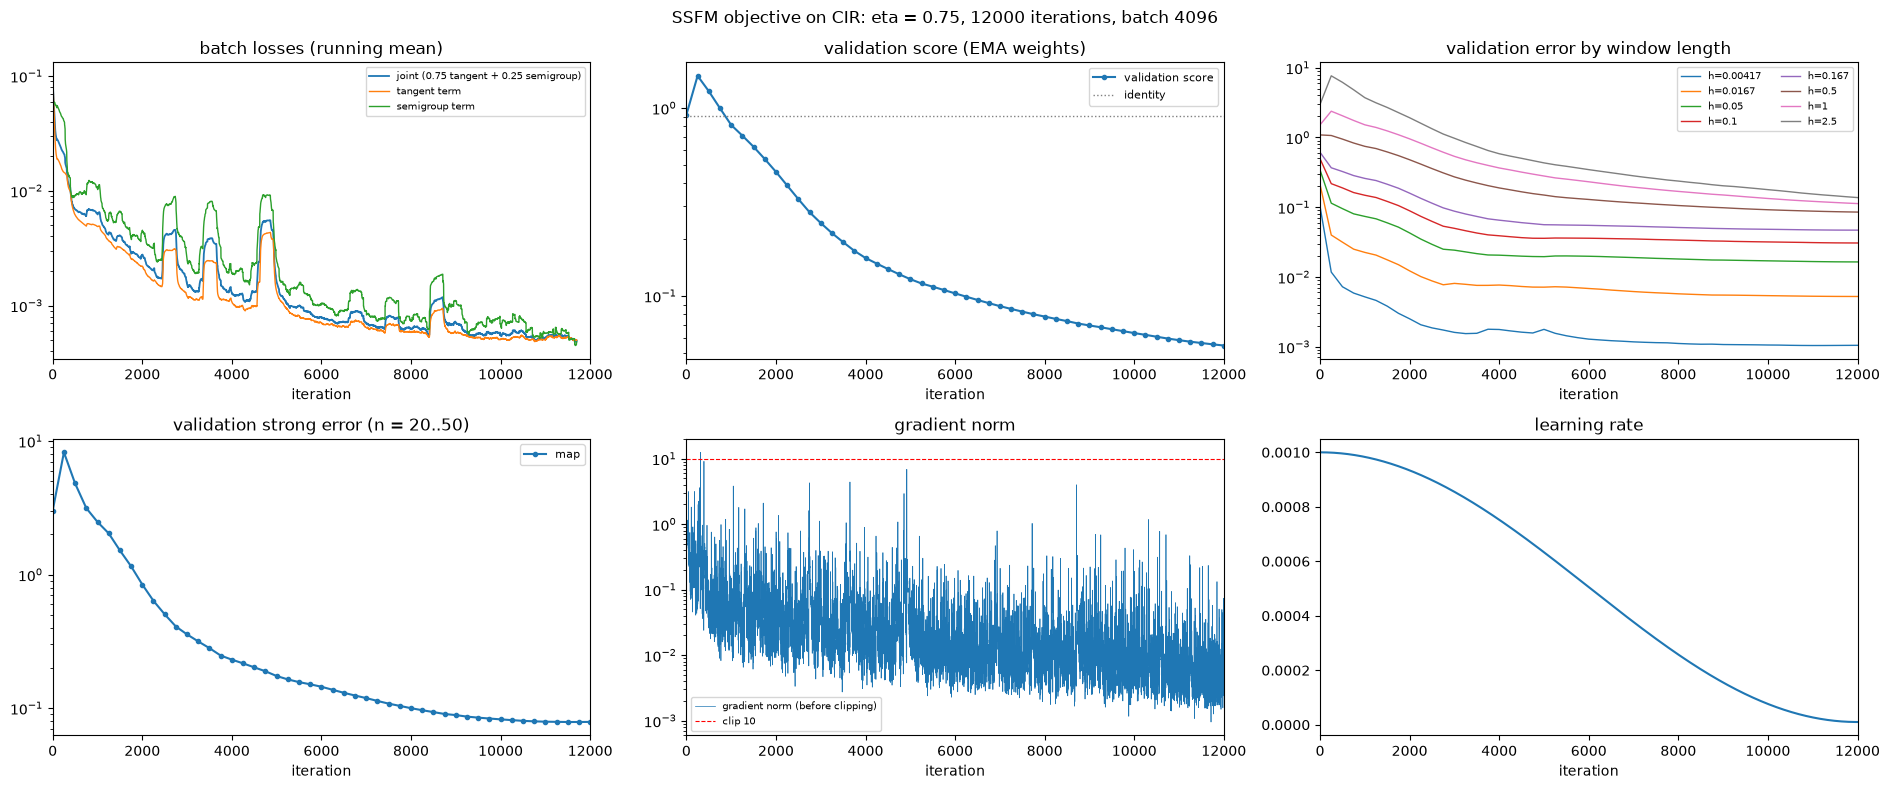

In [21]:
PS, logS, vlogS = train_or_load('SSFM', IT_G, B_G)
plot_G_training(logS, vlogS, f'SSFM objective on CIR: eta = {ETA}, {IT_G} iterations, batch {B_G}')

**F5.0 — reconstruction of a validation path from $X_0$ with the initial weights.**

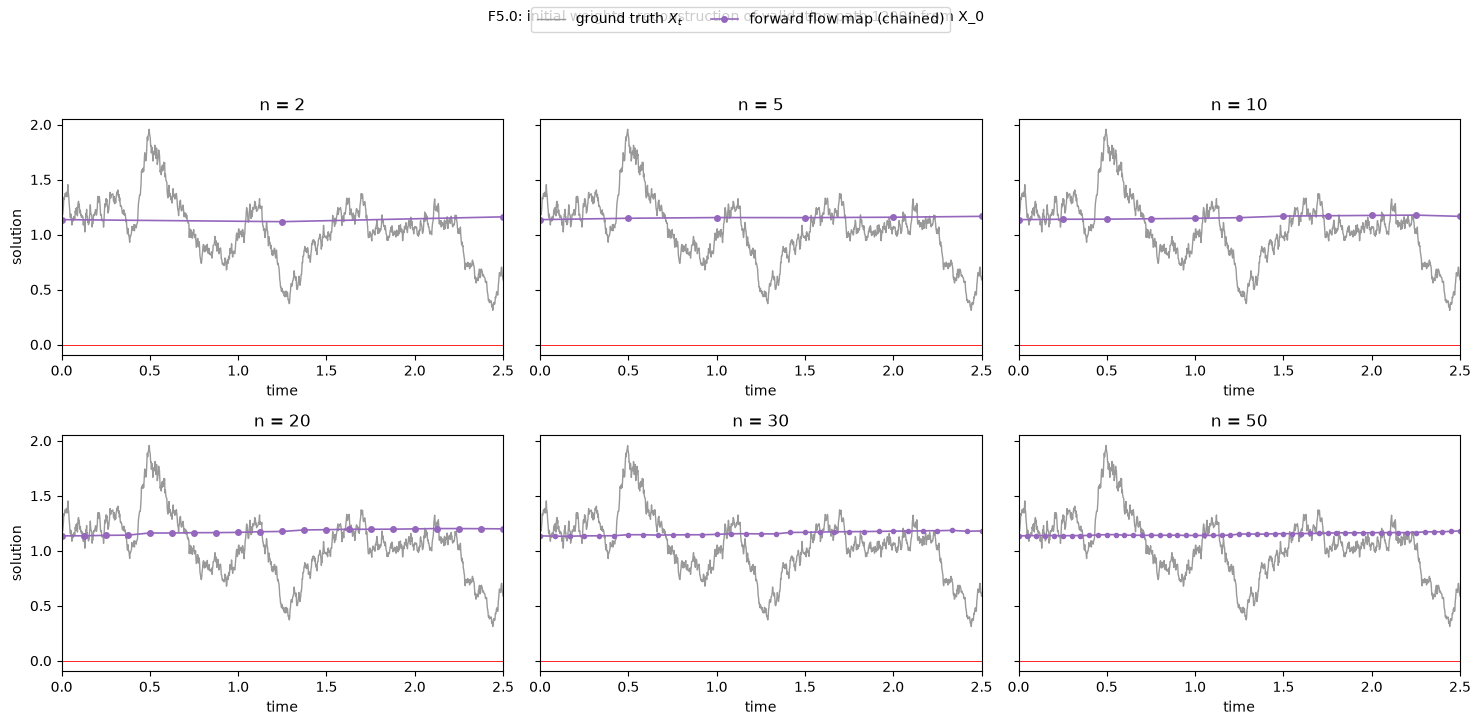

standardised rms error of the reconstructed X_T (row X_T) and mean over the nodes (row nodes); val split, chains on [0, T] from X_0
n intervals                          1       2       5      10      20      24      25      30      40      50   | strong error (n = 20..50)
initial weights            X_T   3.034   3.021   3.014   3.018   3.037   3.044   3.046   3.053   3.067   3.081   |   3.0545
                         nodes   3.034   2.671   2.346   2.224   2.169   2.161   2.160   2.154   2.148   2.147


In [22]:
P_INIT = Psi_init()
recon_fig(P_INIT, 'val', 'F5.0: initial weights - reconstruction of validation path 12000 from X_0', pi=0)
_ = recon_table(P_INIT, 'val', 'initial weights')

**F5.1 — reconstruction of a validation path from $X_0$ after training (final EMA weights).**

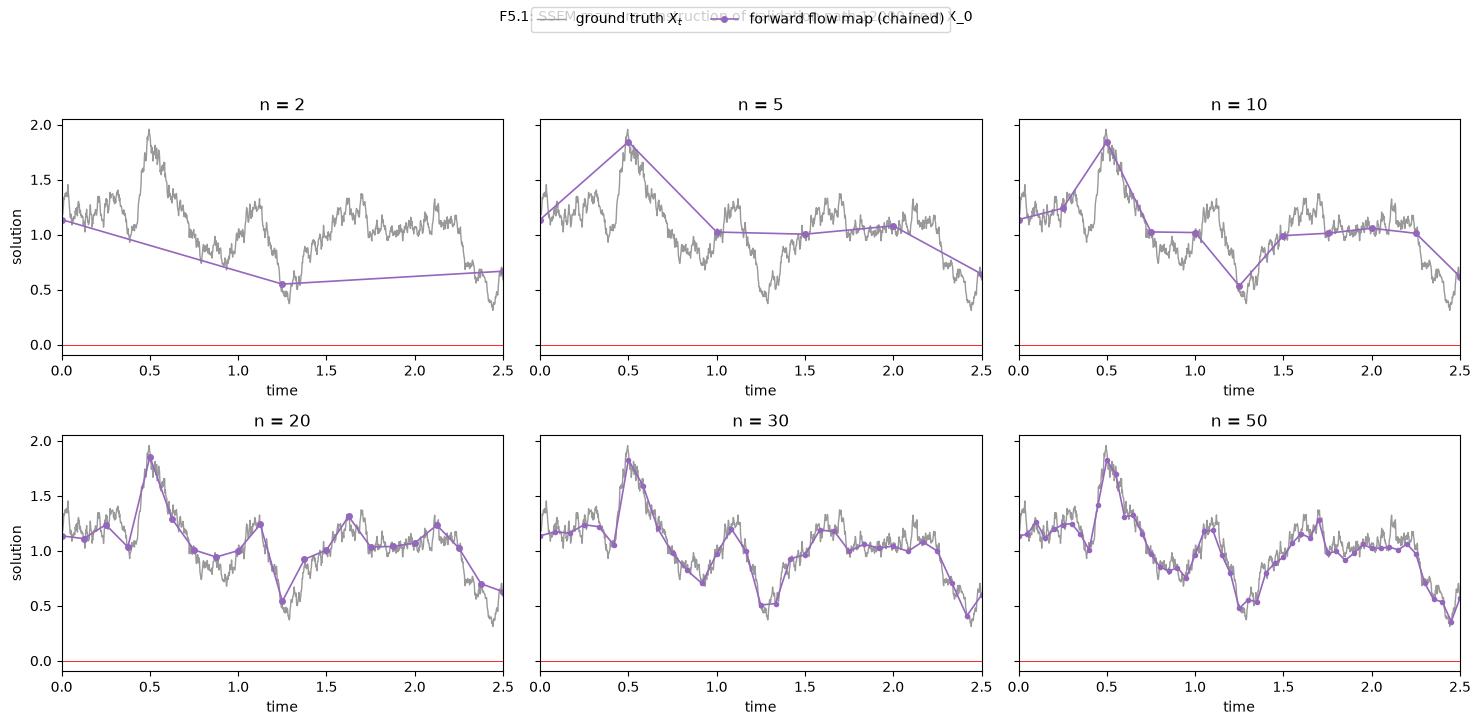

standardised rms error of the reconstructed X_T (row X_T) and mean over the nodes (row nodes); val split, chains on [0, T] from X_0
n intervals                          1       2       5      10      20      24      25      30      40      50   | strong error (n = 20..50)
SSFM map                   X_T   0.137   0.136   0.103   0.087   0.082   0.080   0.079   0.079   0.077   0.076   |   0.0789
                         nodes   0.137   0.135   0.101   0.082   0.070   0.067   0.067   0.065   0.062   0.061


In [23]:
recon_fig(PS, 'val', 'F5.1: SSFM map - reconstruction of validation path 12000 from X_0', pi=0)
_ = recon_table(PS, 'val', 'SSFM map')

**After F5.1.** Read the table by column: $n=1$ is the one-shot error, the other columns the chains, the last column the strong error. A single path can look good or bad by chance; the table over all validation paths is the evidence.

### N5.5 The trained map on the validation windows and the validation strong error

The standardised validation error of the frozen map at every window length next to the identity ruler, and the validation strong error of the map.

standardised validation error by window length


,h=0.00417,h=0.0167,h=0.05,h=0.1,h=0.167,h=0.5,h=1,h=2.5,mean
SSFM map (tangent + semigroup),0.001046,0.005247,0.01642,0.03069,0.04691,0.08517,0.1128,0.1375,0.05448
identity,0.1024,0.212,0.3435,0.4984,0.6165,1.093,1.513,2.871,0.9061


validation: standardised rms error of the reconstructed X_T


,n=1,n=20,n=24,n=25,n=30,n=40,n=50,strong error
SSFM map (tangent + semigroup),0.1373,0.08165,0.07962,0.07947,0.07854,0.07747,0.07637,0.07885


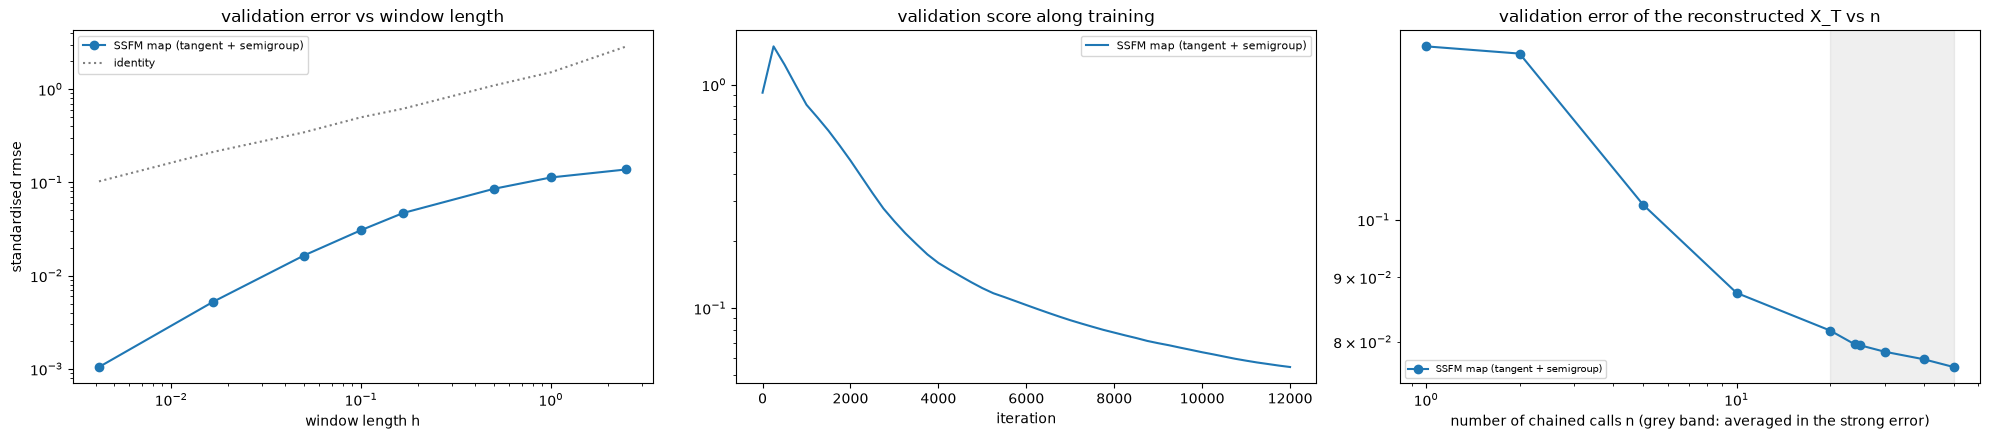

In [24]:
MODELS = {'SSFM': PS}
LABEL = {'SSFM': 'SSFM map (tangent + semigroup)'}
MAP_ID = 'SSFM'
rows = {LABEL[mid]: std_rmse(P_, VAL) for mid, P_ in MODELS.items()}
rows['identity'] = RUL_ID
df_ = pd.DataFrame(rows, index=[f'h={h:.3g}' for h in HV]).T
df_['mean'] = df_.mean(axis=1)
print('standardised validation error by window length')
show(df_)
ST_VAL = {mid: recon_stats(P_, 'val') for mid, P_ in MODELS.items()}
SE_VAL = {mid: strong_of(ST_VAL[mid]) for mid in MODELS}
rows = {LABEL[mid]: {**{f'n={n_}': ST_VAL[mid][n_][0] for n_ in (1,) + NS_AVG}, 'strong error': SE_VAL[mid]} for mid in MODELS}
print('validation: standardised rms error of the reconstructed X_T')
show(pd.DataFrame(rows).T)
fig, ax = plt.subplots(1, 3, figsize=(20, 4.5))
for mid, P_ in MODELS.items():
    ax[0].loglog(HV, std_rmse(P_, VAL), 'o-', label=LABEL[mid])
    ax[1].semilogy(vlogS['it'], vlogS['score'], label=LABEL[mid])
    ax[2].semilogy(NS_TAB, [ST_VAL[mid][n_][0] for n_ in NS_TAB], 'o-', label=LABEL[mid])
ax[2].axvspan(NS_AVG[0], NS_AVG[-1], color='grey', alpha=0.12); ax[2].set_xscale('log')
ax[2].set_xlabel('number of chained calls n (grey band: averaged in the strong error)'); ax[2].set_title('validation error of the reconstructed X_T vs n'); ax[2].legend(fontsize=7)
ax[0].loglog(HV, RUL_ID, ':', color='grey', label='identity')
ax[0].set_xlabel('window length h'); ax[0].set_ylabel('standardised rmse'); ax[0].set_title('validation error vs window length'); ax[0].legend(fontsize=8)
ax[1].set_xlabel('iteration'); ax[1].set_title('validation score along training'); ax[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

## N6 — Diagnostics on the test split

The test split opens here. The map is frozen (final EMA weights, nothing selected on validation). All numbers are on the test paths $16000$–$19999$ and come from a single run.

standardised test error by window length


,h=0.00417,h=0.0167,h=0.05,h=0.1,h=0.167,h=0.5,h=1,h=2.5,mean
SSFM map (tangent + semigroup),0.001006,0.005277,0.01675,0.03142,0.04587,0.08481,0.1142,0.1373,0.05457
identity,0.1019,0.2064,0.3547,0.4944,0.6423,1.076,1.517,2.808,0.9002


bootstrap 95% interval of the standardised rms error of the map (resampling the test windows)


,h=0.00417,h=0.0167,h=0.05,h=0.1,h=0.167,h=0.5,h=1,h=2.5
rms,0.001006,0.005277,0.01675,0.03142,0.04587,0.08481,0.1142,0.1373
ci_low,0.0009789,0.005071,0.01624,0.03028,0.04437,0.08245,0.1122,0.1331
ci_high,0.001036,0.005486,0.01727,0.03252,0.04738,0.08719,0.1163,0.1417


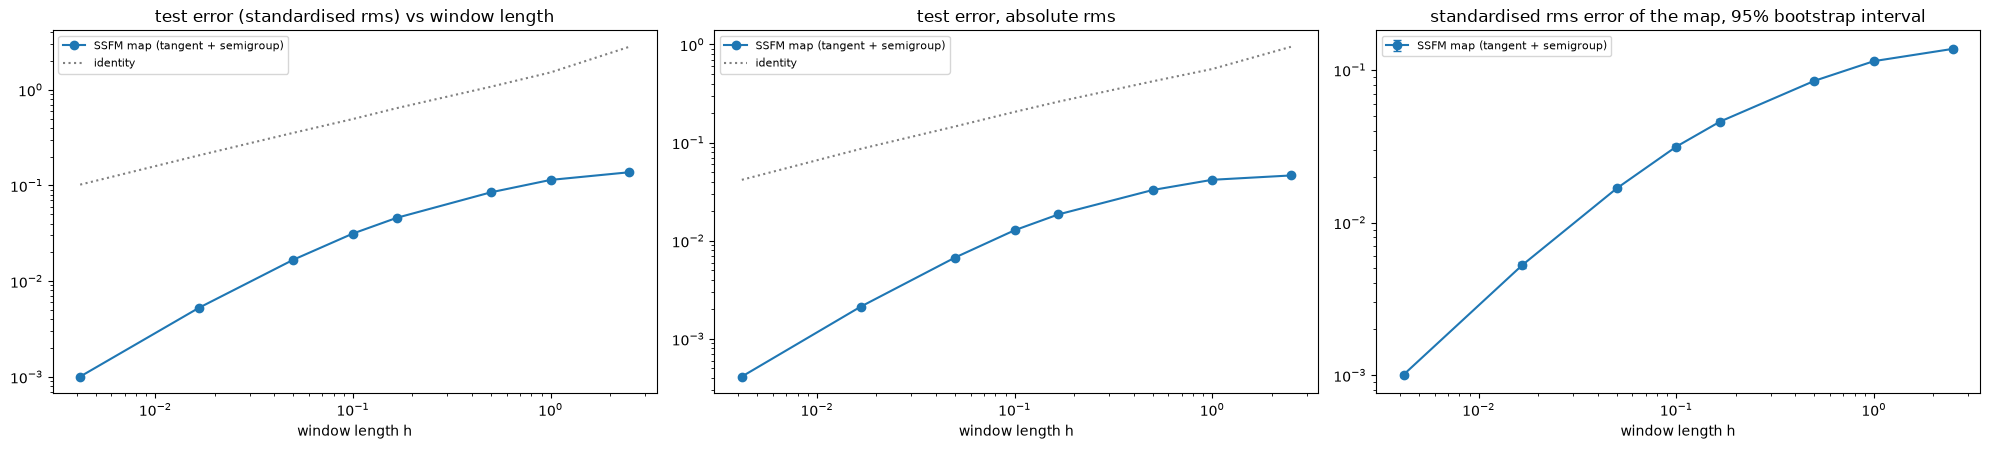

In [25]:
TEST_UNLOCKED = True
TEST = build_windows('test', N_TEST_WIN, (777, 61))
RUL_ID_T = ruler_identity(TEST)
SQ = {mid: {L: ((Psi(P_, TEST[L]['x'], TEST[L]['Ih'], TEST[L]['h']) - TEST[L]['xt']) / TEST[L]['sd']) ** 2 for L in TEST} for mid, P_ in MODELS.items()}
RM = {mid: np.array([np.sqrt(np.mean(SQ[mid][L])) for L in LV]) for mid in MODELS}
rows = {LABEL[mid]: RM[mid] for mid in MODELS}
rows['identity'] = RUL_ID_T
df_ = pd.DataFrame(rows, index=[f'h={h:.3g}' for h in HV]).T
df_['mean'] = df_.mean(axis=1)
print('standardised test error by window length')
show(df_)
IDX_B = paired_boot_idx(N_TEST_WIN, N_BOOT, (777, 91))
BOOT = {}
for mid in MODELS:
    for L in LV:
        BOOT[(mid, L)] = boot_ci(np.sqrt(SQ[mid][L][IDX_B].mean(1)))
print('bootstrap 95% interval of the standardised rms error of the map (resampling the test windows)')
show(pd.DataFrame({f'h={L * DT:.3g}': {'rms': RM[MAP_ID][j], 'ci_low': BOOT[(MAP_ID, L)][0], 'ci_high': BOOT[(MAP_ID, L)][1]} for j, L in enumerate(LV)}))
fig, ax = plt.subplots(1, 3, figsize=(20, 4.6))
for mid in MODELS:
    ax[0].loglog(HV, RM[mid], 'o-', label=LABEL[mid])
    ax[1].loglog(HV, [np.sqrt(np.mean((Psi(MODELS[mid], TEST[L]['x'], TEST[L]['Ih'], TEST[L]['h']) - TEST[L]['xt']) ** 2)) for L in LV], 'o-', label=LABEL[mid])
ax[0].loglog(HV, RUL_ID_T, ':', color='grey', label='identity')
ax[0].set_xlabel('window length h'); ax[0].set_title('test error (standardised rms) vs window length'); ax[0].legend(fontsize=8)
ax[1].loglog(HV, [np.sqrt(np.mean((TEST[L]['x'] - TEST[L]['xt']) ** 2)) for L in LV], ':', color='grey', label='identity')
ax[1].set_xlabel('window length h'); ax[1].set_title('test error, absolute rms'); ax[1].legend(fontsize=8)
lo_ = np.array([BOOT[(MAP_ID, L)][0] for L in LV]); hi_ = np.array([BOOT[(MAP_ID, L)][1] for L in LV]); m_ = RM[MAP_ID]
ax[2].errorbar(HV, m_, yerr=[m_ - lo_, hi_ - m_], fmt='o-', capsize=3, label=LABEL[MAP_ID])
ax[2].set_xscale('log'); ax[2].set_yscale('log')
ax[2].set_xlabel('window length h'); ax[2].set_title('standardised rms error of the map, 95% bootstrap interval'); ax[2].legend(fontsize=8)
fig.tight_layout(); plt.show()

### N6.2 Strong error on the test split

**What.** For every $n\in\{1,2,5,10,20,24,25,30,40,50\}$ the error $\varepsilon_n$ of the reconstructed $X_T$ on the $4000$ test paths, and the strong error with a $95\%$ paired bootstrap interval ($2000$ resamples of paths).

test split, chains on [0, T] from X_0: standardised rms error of the reconstructed X_T (lower is better)


,n=1,n=2,n=5,n=10,n=20,n=24,n=25,n=30,n=40,n=50,strong error,ci_low,ci_high
map,,,,,,,,,,,,,
SSFM map (tangent + semigroup),0.1382,0.1361,0.102,0.08577,0.07867,0.07805,0.07804,0.07682,0.07576,0.07532,0.07711,0.07484,0.07986


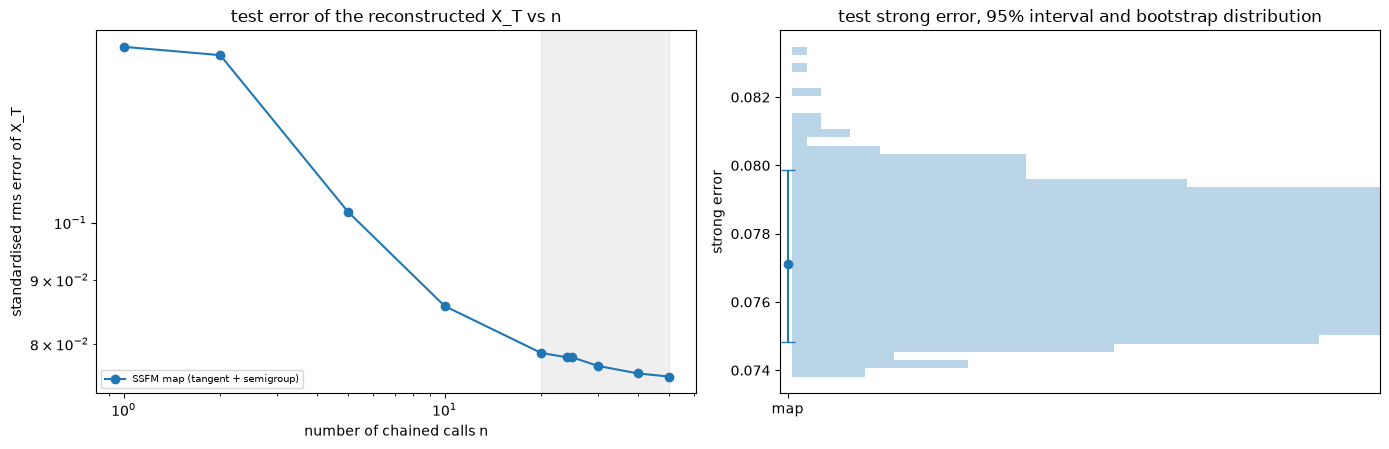

In [26]:
ST_TEST = {mid: recon_stats(P_, 'test') for mid, P_ in MODELS.items()}
SQT = {mid: strong_sq(P_, 'test') for mid, P_ in MODELS.items()}
IDX_S = paired_boot_idx(SQT[MAP_ID].shape[1], N_BOOT, (777, 92))
def se_boot(sq):
    # strong error of every bootstrap resample: mean over n in NS_AVG of the rms over resampled paths
    return np.mean([np.sqrt(sq[j][IDX_S].mean(axis=1)) for j in range(sq.shape[0])], axis=0)
SEB = {mid: se_boot(SQT[mid]) for mid in MODELS}
SE_TEST = {mid: strong_of(ST_TEST[mid]) for mid in MODELS}
rows = []
for mid in MODELS:
    lo, hi = boot_ci(SEB[mid])
    r_ = {'map': LABEL[mid]}; r_.update({f'n={n_}': ST_TEST[mid][n_][0] for n_ in NS_TAB}); r_.update({'strong error': SE_TEST[mid], 'ci_low': lo, 'ci_high': hi})
    rows.append(r_)
print('test split, chains on [0, T] from X_0: standardised rms error of the reconstructed X_T (lower is better)')
show(pd.DataFrame(rows).set_index('map'))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
for mid in MODELS:
    ax[0].loglog(NS_TAB, [ST_TEST[mid][n_][0] for n_ in NS_TAB], 'o-', label=LABEL[mid])
ax[0].axvspan(NS_AVG[0], NS_AVG[-1], color='grey', alpha=0.12)
ax[0].set_xlabel('number of chained calls n'); ax[0].set_ylabel('standardised rms error of X_T'); ax[0].set_title('test error of the reconstructed X_T vs n'); ax[0].legend(fontsize=7)
lo_, hi_ = boot_ci(SEB[MAP_ID]); v_ = SE_TEST[MAP_ID]
ax[1].errorbar([0], [v_], yerr=[[v_ - lo_], [hi_ - v_]], fmt='o', capsize=5, color='C0')
ax[1].hist(SEB[MAP_ID], bins=40, orientation='horizontal', alpha=0.3, color='C0', bottom=0.3)
ax[1].set_xticks([0]); ax[1].set_xticklabels(['map']); ax[1].set_xlim(-0.5, 0.5 + 0.02 * N_BOOT)
ax[1].set_ylabel('strong error'); ax[1].set_title('test strong error, 95% interval and bootstrap distribution')
fig.tight_layout(); plt.show()

**After.** Read the strong error together with the left panel, because the average hides whether the map is bad at all $n$ or only at some.

### N6.3 Distribution of the per-path error: percentile tables, histograms, signed error

**Per-path quantities.** For a test path $i$ and a chain of $n$ calls, $\hat Z^{(n)}_{T,i}$ estimates $X_{T,i}$. With $\mathrm{sd}(X_T)$ the exact marginal standard deviation:

* the **absolute error** $e^{(n)}_i=|\hat Z^{(n)}_{T,i}-X_{T,i}|/\mathrm{sd}(X_T)$, and the **strong error of the path** $e_i=\tfrac16\sum_{n\in\{20,\dots,50\}}e^{(n)}_i$;

* the **signed error** $s_i=\tfrac16\sum_n(\hat Z^{(n)}_{T,i}-X_{T,i})/\mathrm{sd}(X_T)$: positive means the map over-estimates the final state;

* the **signed relative error** $\tfrac16\sum_n(\hat Z^{(n)}_{T,i}-X_{T,i})/X_{T,i}$, the natural scale for a positive, multiplicative process.

**Tables.** For the strong error of the path, for $n=5$ and for $n=50$: rms, median and mean; then the paths sorted by error and cut at the percentiles $0,10,\dots,90,95,99,99.9,100$, with the smallest, largest and mean error of each slice.

**Figures.**

1. Sorted errors against percentile rank (log axis).

2. Histograms of the strong error of the path, linear and logarithmic frequency.

3. Signed error: histograms (absolute and relative), then the bias against the true $X_T$ (twenty equal-size groups by $X_T$; median and quartiles of $s_i$ per group), then the signed error **along time** for $n=50$ (median and quartiles at every node).

**Why.** A strong error far above the median reveals a heavy tail of bad chains; a signed error with a non-zero centre or a trend in $X_T$ reveals a systematic bias that the absolute error hides. For CIR the interesting region is near zero, where the noise is smallest in absolute terms and largest in relative terms.


In [42]:
PCT_EDGES = [0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 95, 99, 99.9, 100]
LAB_PE = dict(LABEL)
SD_T = np.sqrt(v_exact(T_END))
XT_TEST = get('Xf', 'test')[:, -1]

def path_err(P_, n, gfun=None):
    Z = chained_recon(P_, 'test', n, gfun=gfun)
    return np.abs(Z[:, -1] - XT_TEST) / SD_T

def path_signed(P_, gfun=None, rel=False):
    out = []
    for n_ in NS_AVG:
        Z = chained_recon(P_, 'test', n_, gfun=gfun)
        out.append((Z[:, -1] - XT_TEST) / (XT_TEST if rel else SD_T))
    return np.mean(out, axis=0)

def pct_table(e):
    s = np.sort(e); N = len(s); rows = []
    for a, b in zip(PCT_EDGES[:-1], PCT_EDGES[1:]):
        i0, i1 = int(round(a / 100 * N)), int(round(b / 100 * N))
        seg = s[i0:max(i1, i0 + 1)]
        rows.append((f'[{a:g}, {b:g}]', seg[0], seg[-1], seg.mean()))
    return pd.DataFrame(rows, columns=['percentile bin', 'min', 'max', 'mean']).set_index('percentile bin')

PE = {}
for name, fn_ in (('strong (avg n=20..50)', lambda P_, g=None: np.mean([path_err(P_, n_, g) for n_ in NS_AVG], axis=0)),
                  ('n = 5', lambda P_, g=None: path_err(P_, 5, g)),
                  ('n = 50', lambda P_, g=None: path_err(P_, 50, g))):
    PE[name] = {mid: fn_(MODELS[mid]) for mid in MODELS}
    print(f'\n=== per-path standardised error of X_T, test split ({len(XT_TEST)} paths): {name} ===')
    show(pd.DataFrame({LAB_PE[mid]: dict(rms=np.sqrt(np.mean(PE[name][mid] ** 2)), median=np.median(PE[name][mid]), mean=PE[name][mid].mean()) for mid in PE[name]}).T)
    print('error by slice of paths sorted by error (first row: best 10%; last row: worst 0.1%)')
    show(pd.concat({LAB_PE[mid]: pct_table(PE[name][mid]) for mid in PE[name]}, axis=1))


=== per-path standardised error of X_T, test split (4000 paths): strong (avg n=20..50) ===


,rms,median,mean
SSFM map (tangent + semigroup),0.07391,0.05756,0.06224


error by slice of paths sorted by error (first row: best 10%; last row: worst 0.1%)


SSFM map (tangent + semigroup)                
                                          min     max    mean
percentile bin                                               
[0, 10]                              0.006694 0.02236 0.01722
[10, 20]                              0.02237 0.03019 0.02613
[20, 30]                              0.03019 0.03845 0.03428
[30, 40]                              0.03845 0.04771 0.04296
[40, 50]                              0.04774 0.05755 0.05263
[50, 60]                              0.05757 0.06634 0.06205
[60, 70]                              0.06635 0.07484 0.07065
[70, 80]                              0.07487 0.08463  0.0798
[80, 90]                              0.08467  0.1018 0.09189
[90, 95]                               0.1019  0.1264  0.1121
[95, 99]                               0.1264  0.2083  0.1546
[99, 99.9]                             0.2097   0.297  0.2454
[99.9, 100]                            0.3437  0.7578  0.4793


=== per-path standardised error of X_T, test split (4000 paths): n = 5 ===


,rms,median,mean
SSFM map (tangent + semigroup),0.102,0.08069,0.08583


... (2 outputs left out)


=== per-path standardised error of X_T, test split (4000 paths): n = 50 ===


,rms,median,mean
SSFM map (tangent + semigroup),0.07532,0.0538,0.06


error by slice of paths sorted by error (first row: best 10%; last row: worst 0.1%)


SSFM map (tangent + semigroup)                
                                          min     max    mean
percentile bin                                               
[0, 10]                             9.635e-06 0.01222 0.00621
[10, 20]                              0.01241 0.02399 0.01841
[20, 30]                                0.024  0.0351 0.02973
[30, 40]                              0.03515 0.04466 0.03991
[40, 50]                               0.0447 0.05379 0.04909
[50, 60]                              0.05381 0.06351 0.05855
[60, 70]                              0.06351 0.07333 0.06842
[70, 80]                              0.07343 0.08597 0.07949
[80, 90]                              0.08607  0.1077 0.09586
[90, 95]                               0.1077  0.1391  0.1208
[95, 99]                               0.1391  0.2034  0.1653
[99, 99.9]                             0.2034  0.3092  0.2479
[99.9, 100]                            0.3094  0.9928  0.5452

**After the tables and the sorted errors.** Read the last two rows of each slice table: they are the worst $1\%$ and $0.1\%$ of the paths. If the rms is close to the median, the error is spread evenly; if it is much larger, a few paths dominate it, and the sorted-error curve shows where its right end lifts off.

**Histograms of the strong error of the path.** Top: linear frequency; bottom: logarithmic frequency. The horizontal axis is cut at the $99.5\%$ quantile, paths beyond it are counted in the last bar (their number is in the title). Red dashed: median; blue dotted: rms.

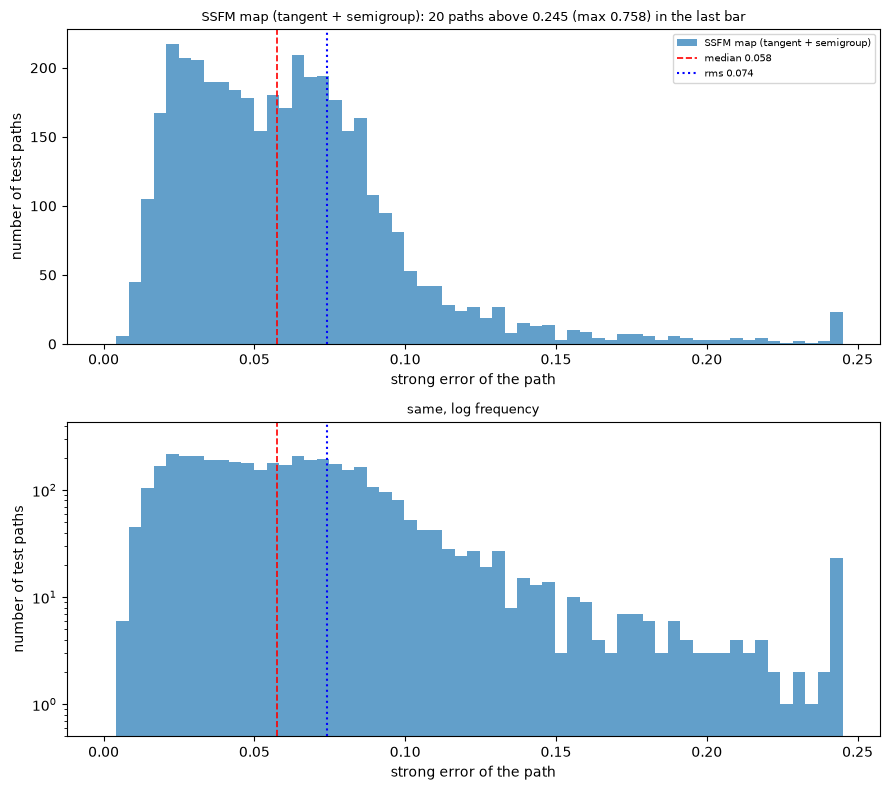

In [28]:
NAME = 'strong (avg n=20..50)'
ids = list(MODELS)
fig, ax = plt.subplots(2, len(ids), figsize=(9 * len(ids), 8), squeeze=False)
tops = {mid: max(np.quantile(PE[NAME][mid], 0.995), 1e-9) for mid in ids}
cmax = max(np.histogram(np.clip(PE[NAME][mid], 0, tops[mid]), bins=np.linspace(0, tops[mid], 60))[0].max() for mid in ids)
for k, mid in enumerate(ids):
    e = PE[NAME][mid]; top = tops[mid]
    bins = np.linspace(0, top, 60)
    rms_ = np.sqrt(np.mean(e ** 2))
    col = f'C{k}'
    for r_ in range(2):
        a_ = ax[r_, k]
        a_.hist(np.clip(e, 0, top), bins=bins, color=col, alpha=0.7, label=LAB_PE[mid])
        a_.axvline(np.median(e), color='r', ls='--', lw=1.2, label=f'median {np.median(e):.3f}')
        if rms_ < top:
            a_.axvline(rms_, color='b', ls=':', lw=1.5, label=f'rms {rms_:.3f}')
        a_.set_xlabel('strong error of the path'); a_.set_ylabel('number of test paths')
    ax[1, k].set_yscale('log'); ax[1, k].set_ylim(0.5, 2.0 * cmax); ax[1, k].set_title('same, log frequency', fontsize=9)
    ax[0, k].set_title(f'{LAB_PE[mid]}: {np.sum(e > top)} paths above {top:.3f} (max {np.max(e):.3g}) in the last bar', fontsize=9)
    ax[0, k].legend(fontsize=7)
fig.tight_layout(); plt.show()

**After the histograms.** A long right tail on the logarithmic panel is a set of paths on which the map fails. Compare the median lines: the median is the typical path, the rms is pulled by the tail.

**Signed error.** Top row: histograms of the signed error $s_i$ and of the signed relative error of the map, with the share of over-estimated paths. Bottom row: median and quartiles of the signed error per group of true $X_T$ (twenty equal-size groups), and the same for the signed relative error of the map.

signed error of the reconstructed X_T on the test paths, averaged over n = 20..50 (positive = over-estimation)


,mean,median,sd,pct_over_estimated,rel_mean,rel_median,rel_sd
SSFM map (tangent + semigroup),0.0205,0.03919,0.0701,69.92,0.05085,0.03079,0.1031


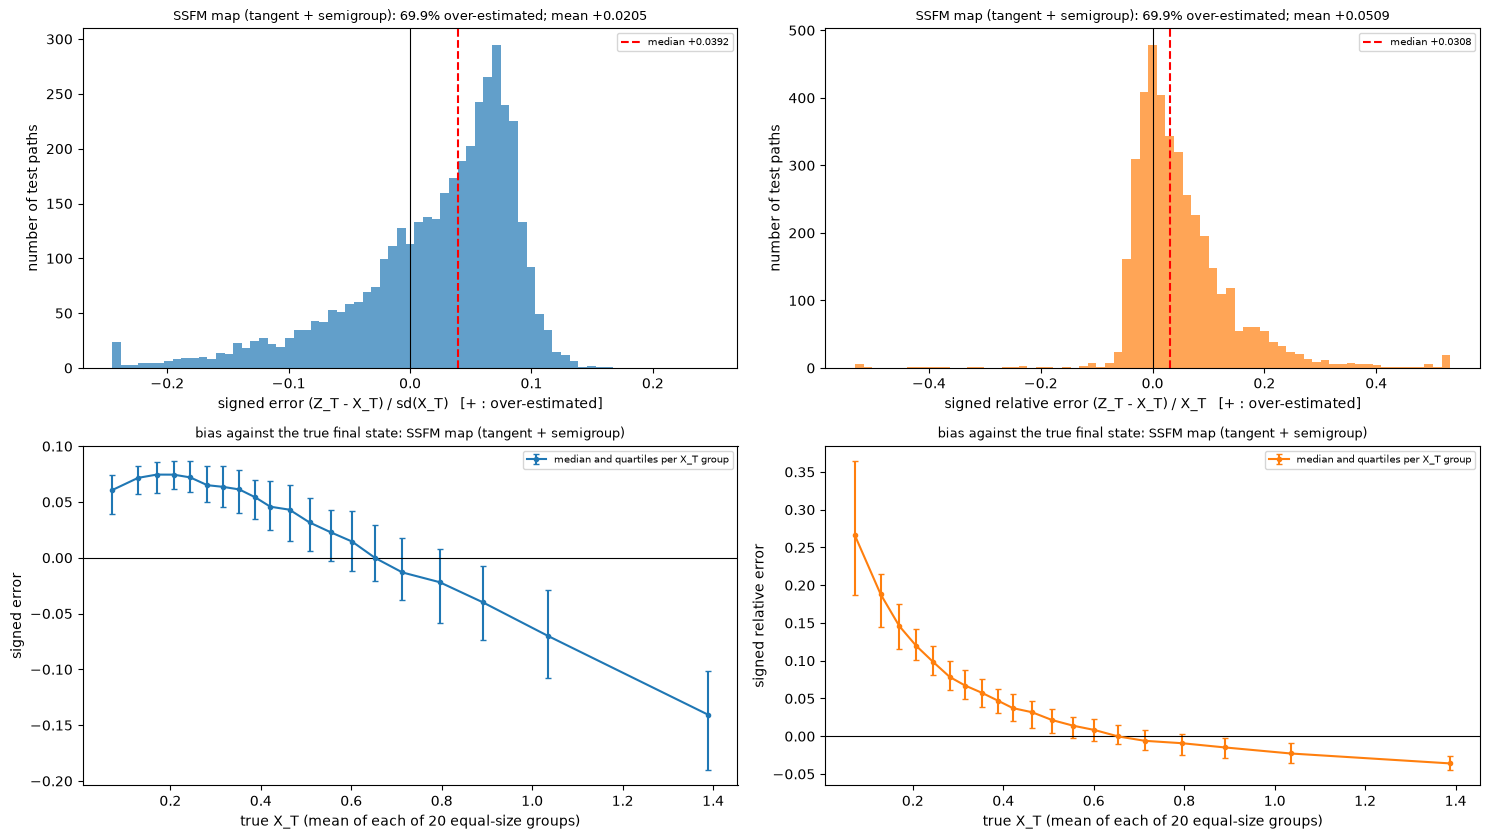

In [29]:
SG = {mid: path_signed(MODELS[mid]) for mid in MODELS}
SGR = {mid: path_signed(MODELS[mid], rel=True) for mid in MODELS}
rows = {}
for mid in ids:
    rows[LAB_PE[mid]] = dict(mean=SG[mid].mean(), median=np.median(SG[mid]), sd=SG[mid].std(), pct_over_estimated=100 * np.mean(SG[mid] > 0),
                             rel_mean=SGR[mid].mean(), rel_median=np.median(SGR[mid]), rel_sd=SGR[mid].std())
print('signed error of the reconstructed X_T on the test paths, averaged over n = 20..50 (positive = over-estimation)')
show(pd.DataFrame(rows).T)
qb = np.quantile(XT_TEST, np.linspace(0, 1, 21))
ib = np.clip(np.digitize(XT_TEST, qb[1:-1]), 0, 19)
xm_b = np.array([XT_TEST[ib == b].mean() for b in range(20)])
def bin_profile(s_):
    med = np.array([np.median(s_[ib == b]) for b in range(20)])
    q1 = np.array([np.quantile(s_[ib == b], 0.25) for b in range(20)]); q3 = np.array([np.quantile(s_[ib == b], 0.75) for b in range(20)])
    return med, q1, q3
fig, ax = plt.subplots(2, 2, figsize=(15, 8.5))
for k, (mid, s_, lab_) in enumerate([(MAP_ID, SG[MAP_ID], 'signed error (Z_T - X_T) / sd(X_T)'),
                                       (MAP_ID, SGR[MAP_ID], 'signed relative error (Z_T - X_T) / X_T')]):
    col = 'C0' if k == 0 else 'C1'
    lim = np.quantile(np.abs(s_), 0.995); lim = lim if lim > 0 else 1.0
    ax[0, k].hist(np.clip(s_, -lim, lim), bins=np.linspace(-lim, lim, 70), color=col, alpha=0.7)
    ax[0, k].axvline(0, color='k', lw=0.8); ax[0, k].axvline(np.median(s_), color='r', ls='--', label=f'median {np.median(s_):+.3g}')
    ax[0, k].set_xlabel(lab_ + '   [+ : over-estimated]'); ax[0, k].set_ylabel('number of test paths')
    ax[0, k].set_title(f'{LAB_PE[mid]}: {100 * np.mean(s_ > 0):.1f}% over-estimated; mean {s_.mean():+.3g}', fontsize=9); ax[0, k].legend(fontsize=7)
    med, q1, q3 = bin_profile(s_)
    ax[1, k].errorbar(xm_b, med, yerr=[med - q1, q3 - med], fmt='o-', color=col, capsize=2, ms=3, label='median and quartiles per X_T group')
    ax[1, k].axhline(0, color='k', lw=0.8)
    ax[1, k].set_xlabel('true X_T (mean of each of 20 equal-size groups)'); ax[1, k].set_ylabel(lab_.split(' (')[0]); ax[1, k].legend(fontsize=7)
    ax[1, k].set_title(f'bias against the true final state: {LAB_PE[mid]}', fontsize=9)
fig.tight_layout(); plt.show()

**After the signed-error figure.** A histogram centred at $0$ with half the paths on each side means no global bias. In the bottom row a flat profile at $0$ means no state-dependent bias; a decreasing profile means the map pulls the final state towards the middle of its law (over-estimates small $X_T$, under-estimates large ones), which is what a conditional mean does when it cannot see the residual path. The relative panel magnifies the region near zero, where the absolute error is small but the multiplicative structure of the map matters most.

**Signed error along time.** For the chain with $n=50$, the signed error $(\hat Z_k-X_{t_k})/\mathrm{sd}(X_{t_k})$ at every node: median, quartiles and the $5\%$–$95\%$ band over the test paths. Right: the rms at every node.

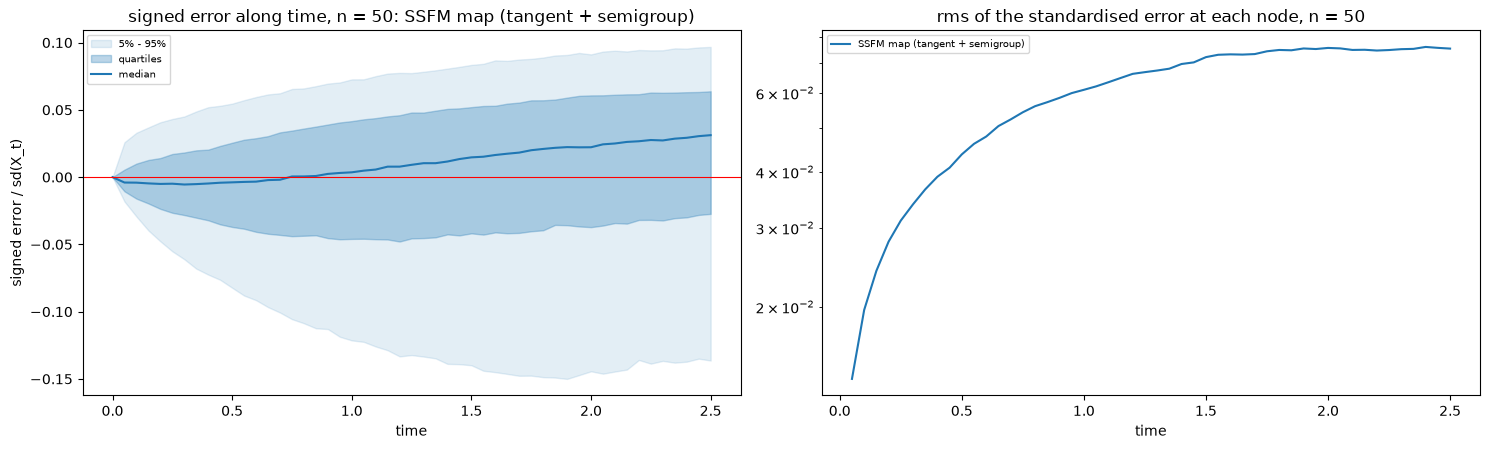

In [30]:
n_ = 50
xt_n = get('x', 'test', n_); tk = np.arange(n_ + 1) * T_END / n_; sdk = np.sqrt(v_exact(tk))
s_ = (chained_recon(MODELS[MAP_ID], 'test', n_) - xt_n) / sdk
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
q = np.quantile(s_, [0.05, 0.25, 0.5, 0.75, 0.95], axis=0)
ax[0].fill_between(tk, q[0], q[4], color='C0', alpha=0.12, label='5% - 95%')
ax[0].fill_between(tk, q[1], q[3], color='C0', alpha=0.3, label='quartiles')
ax[0].plot(tk, q[2], color='C0', lw=1.5, label='median'); ax[0].axhline(0, color='r', lw=0.8)
ax[0].set_xlabel('time'); ax[0].set_ylabel('signed error / sd(X_t)'); ax[0].set_title(f'signed error along time, n = {n_}: {LAB_PE[MAP_ID]}'); ax[0].legend(fontsize=7)
ax[1].semilogy(tk[1:], np.sqrt(np.mean(s_[:, 1:] ** 2, axis=0)), color='C0', label=LAB_PE[MAP_ID])
ax[1].set_xlabel('time'); ax[1].set_title('rms of the standardised error at each node, n = 50'); ax[1].legend(fontsize=7)
fig.tight_layout(); plt.show()

**After.** The chain starts from the exact $X_0$, so the error is zero at $t=0$. Early in the chain the path moves fastest (from $X_0$, mean $1.2$, towards $\mu=0.5$), so that is where a drift error shows; later the mean contraction damps earlier errors and the band should settle to a level set by the one-step error. A median that drifts away from $0$ along time is an accumulating bias.

### N6.4 Reconstruction of test paths from $X_0$

**What.** F6: the reconstruction figure on test path 16000 and the table over all test paths. F6b: four test paths chosen at the $10\%$, $50\%$, $90\%$ and $99\%$ percentiles of the strong error of the path, with the chains $n=5$ and $n=50$. Then the error statistics: the **direct** error $\Psi(X_0,\hat I_{[0,h]},h)$ against $X_h$ on a grid of $25$ window lengths ($1000$ paths), the error along time for $n=5$ and $n=50$, and the one-shot reconstruction of $X_T$ (rms, slope of $\hat X_T$ on $X_T$, variance ratio).

**Why.** The reconstruction is the visual counterpart of the strong error; the percentile paths show what a typical and a bad path look like.

**Expect.** One path is an illustration; the tables are the evidence.

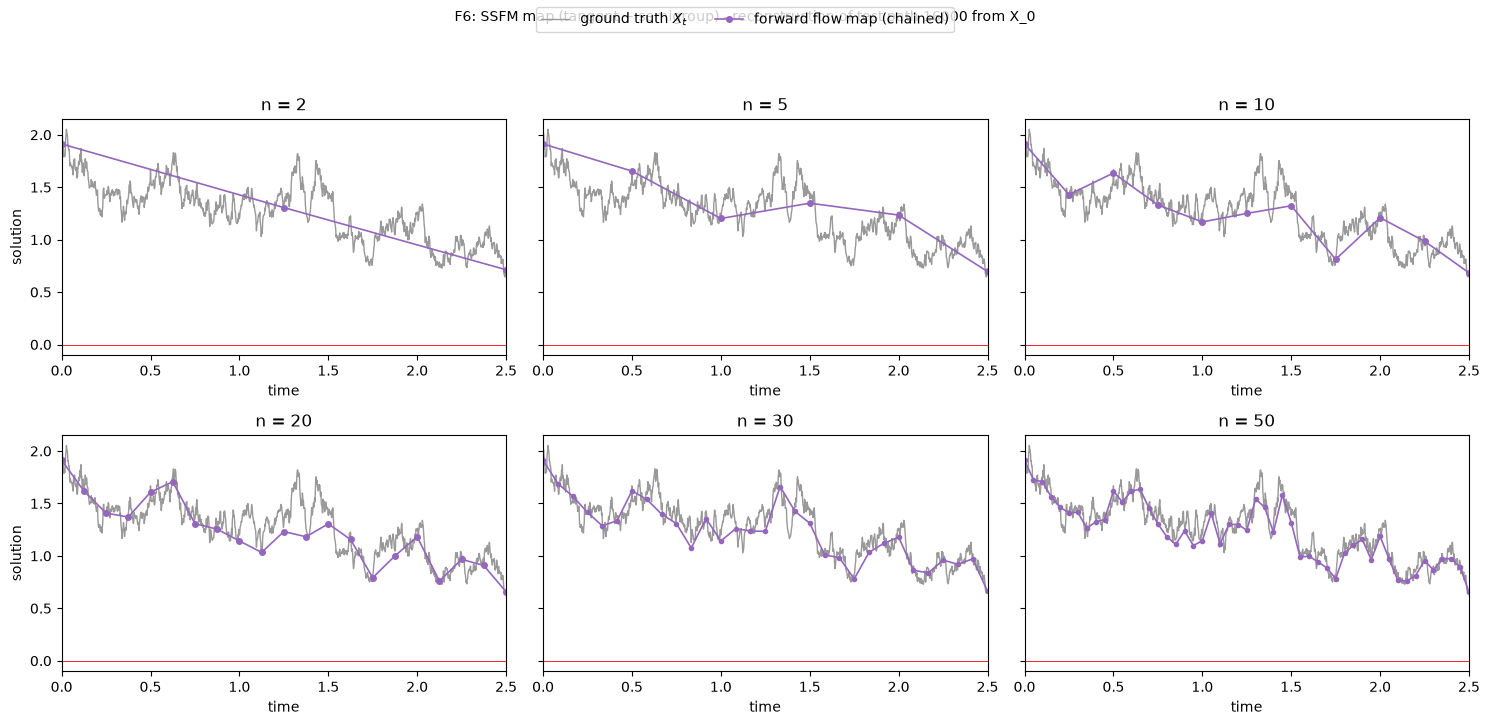

standardised rms error of the reconstructed X_T (row X_T) and mean over the nodes (row nodes); test split, chains on [0, T] from X_0
n intervals                          1       2       5      10      20      24      25      30      40      50   | strong error (n = 20..50)
SSFM map (tangent + se     X_T   0.138   0.136   0.102   0.086   0.079   0.078   0.078   0.077   0.076   0.075   |   0.0771
                         nodes   0.138   0.133   0.101   0.082   0.069   0.067   0.067   0.064   0.061   0.060


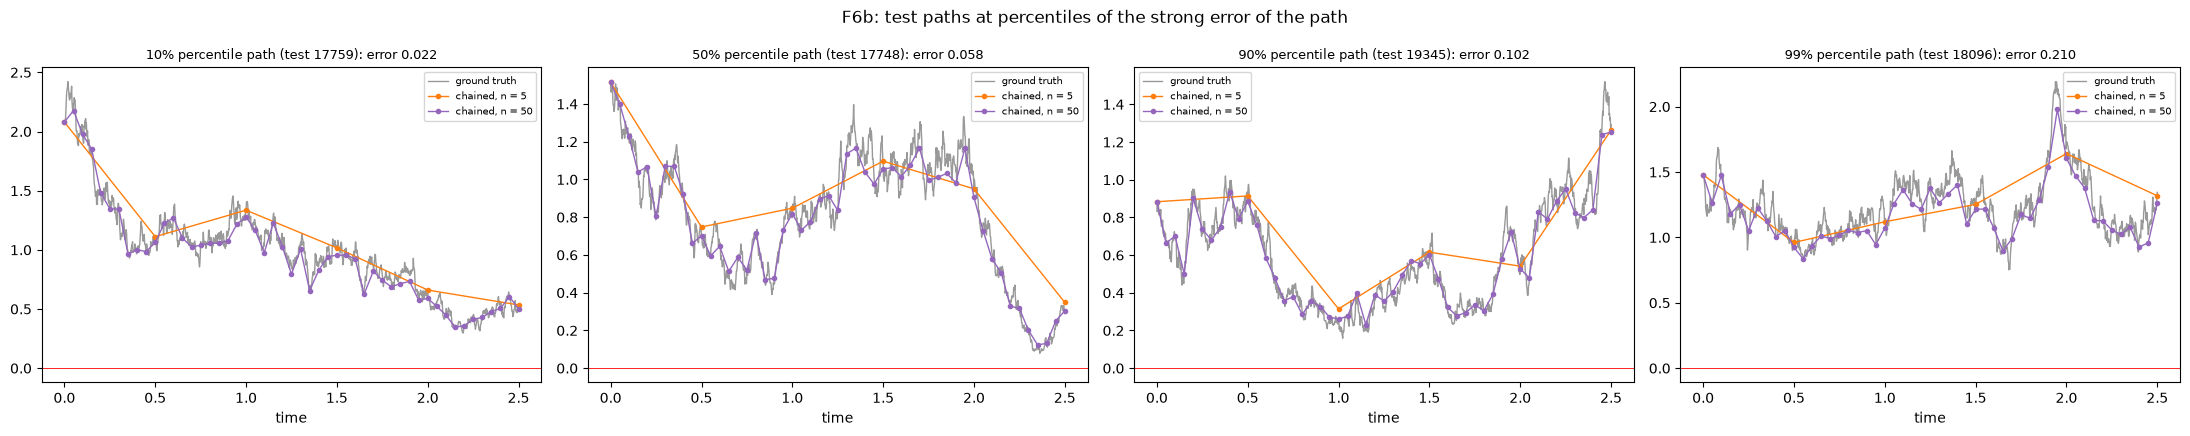

In [31]:
PI0 = REF_PATH - SPLITS['test'][0]
Xte = get('Xf', 'test'); dWte = get('dWf', 'test')
for mid in MODELS:
    recon_fig(MODELS[mid], 'test', f'F6: {LABEL[mid]} - reconstruction of test path {REF_PATH} from X_0', pi=PI0)
_ = recon_table(MODELS[MAP_ID], 'test', LABEL[MAP_ID])
e_path = PE['strong (avg n=20..50)'][MAP_ID]
order = np.argsort(e_path)
picks = [order[min(len(order) - 1, int(q * len(order)))] for q in (0.10, 0.50, 0.90, 0.99)]
tt = np.arange(N_FINE + 1) * DT
fig, ax = plt.subplots(1, 4, figsize=(22, 4.4))
for a_, pi_, q in zip(ax, picks, (10, 50, 90, 99)):
    a_.plot(tt, Xte[pi_], color='0.6', lw=1, label='ground truth')
    for n_, c_ in ((5, 'C1'), (50, 'C4')):
        Z = chained_recon(MODELS[MAP_ID], 'test', n_, np.array([pi_]))[0]
        a_.plot(np.arange(n_ + 1) * T_END / n_, Z, 'o-', ms=3, lw=1, color=c_, label=f'chained, n = {n_}')
    a_.axhline(0, color='r', lw=0.6)
    a_.set_title(f'{q}% percentile path (test {SPLITS["test"][0] + pi_}): error {e_path[pi_]:.3f}', fontsize=9); a_.set_xlabel('time'); a_.legend(fontsize=7)
fig.suptitle('F6b: test paths at percentiles of the strong error of the path'); fig.tight_layout(); plt.show()

**After F6.** Look for agreement in the first steps, where the path moves fastest, and for the behaviour near small states. In F6b the $99\%$ path is a bad case; whether it is bad because it visits small states, or because of a fast excursion, is the question to ask of it.

### N6.5 Laws of the reconstructed paths, and the forward map as a sampler

**What.** (a) The chained reconstruction with $n=50$ gives, for each test path, $\hat Z_0=X_0,\dots,\hat Z_{50}$; the eight panels of F0 are applied to it on the grid $t_k=kT/50$ (law at $t_0$ and $T$, standardised increments with the true coefficients, PIT of $\hat Z_{50}$ under the exact transition from $X_0$, quadratic-variation ratio). (b) The one-shot map $\Psi(X_0,\hat I',T)$ with the paired coefficients and with shuffled coefficients (independent of $X_0$ and of the path).

**Why.** (a) tests the law of the reconstruction; (b) separates the pathwise statement (only the paired coefficients track the path) from the law-level one.

**Expect.** (a) The reconstructed end close to the exact law of $X_T$; the increments on the coarse grid ($\Delta t=0.05$) carry a discretisation offset, and their spread is reduced because a conditional mean removes the unseen part of the noise. (b) Both one-shot samples are close to the law of $X_T$; only the paired one lies on the diagonal of the scatter.

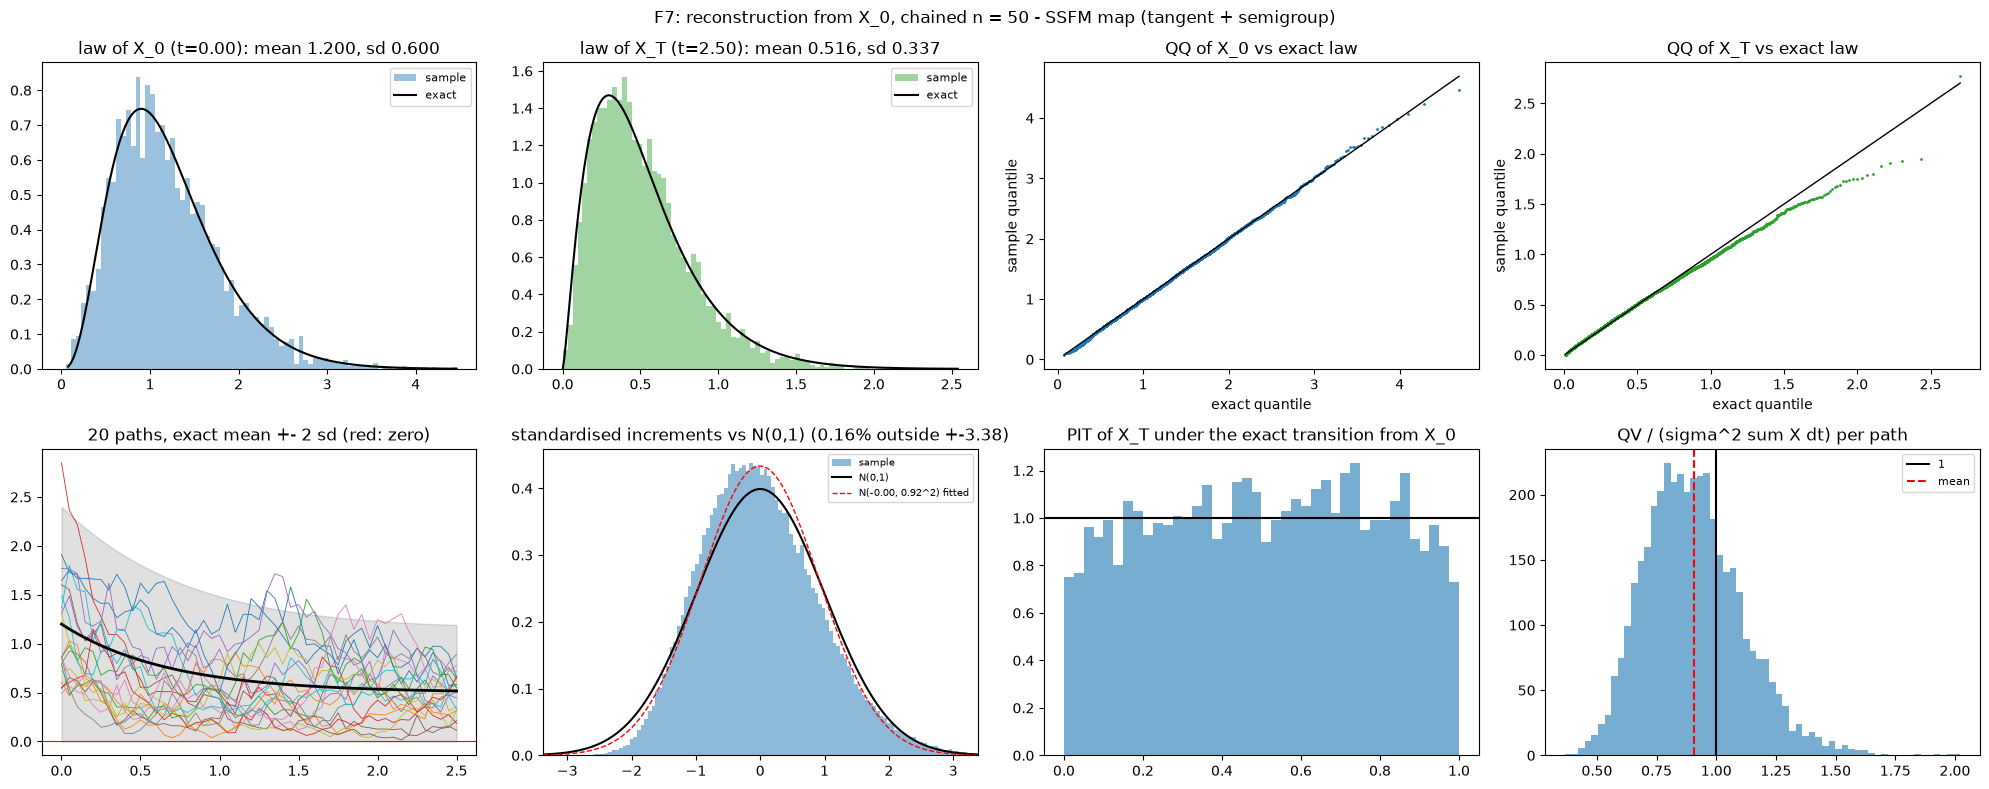

KS0_D=0.008323  KS0_p=0.9423  KST_D=0.02299  KST_p=0.02869  PIT_D=0.02244  PIT_p=0.03511  K2=6.606e+05  K2_p=0  JB=5.356e+11  JB_p=0  QV_ratio=0.9056  min_state=7.99e-07


In [33]:
t50 = np.arange(51) * T_END / 50
LAWSTAT = {}
for mid in MODELS:
    LAWSTAT[mid] = law_panels(chained_recon(MODELS[mid], 'test', 50), t50, f'F7: reconstruction from X_0, chained n = 50 - {LABEL[mid]}')

**After F7.** Read the right end ($t=T$) and the PIT panel first: that is the reconstructed law. A KS $p$-value is a statement about these $4000$ reconstructions only. The left end is the input and is not a test of the map.

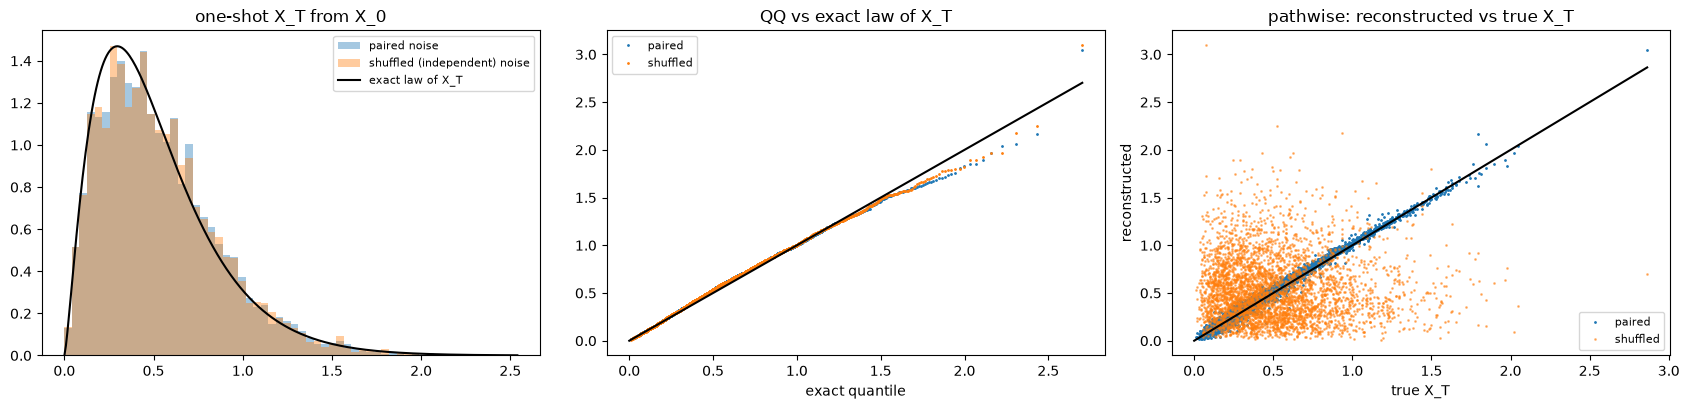

paired   : mean 0.5354 (exact 0.5165)  var 0.10942 (exact 0.11367)  KS D=0.0435 p=5.03e-07   rms to true X_T / sd = 0.138
shuffled : mean 0.5357 (exact 0.5165)  var 0.11039 (exact 0.11367)  KS D=0.0442 p=3.16e-07   rms to true X_T / sd = 1.400


In [34]:
Pm = MODELS[MAP_ID]
perm = rg(777, 3, 401).permutation(Xte.shape[0])
xh_pair = Psi(Pm, Xte[:, 0], Ifull, T_END)
xh_shuf = Psi(Pm, Xte[:, 0], Ifull[perm], T_END)
mT, sT = m_exact(T_END), SD_T
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
u = np.linspace(1e-4, mT + 6 * sT, 300)
for xh, lab in ((xh_pair, 'paired noise'), (xh_shuf, 'shuffled (independent) noise')):
    ax[0].hist(xh, bins=60, range=(0, u[-1]), density=True, alpha=0.4, label=lab)
ax[0].plot(u, marg_pdf(u, T_END), 'k', label='exact law of X_T'); ax[0].set_title('one-shot X_T from X_0'); ax[0].legend(fontsize=8)
pp = (np.arange(1, Xte.shape[0] + 1) - 0.5) / Xte.shape[0]
qT = marg_ppf(pp, T_END)
for xh, lab in ((xh_pair, 'paired'), (xh_shuf, 'shuffled')):
    ax[1].plot(qT, np.sort(xh), '.', ms=2, label=lab)
ax[1].plot([0, qT[-1]], [0, qT[-1]], 'k'); ax[1].set_title('QQ vs exact law of X_T'); ax[1].legend(fontsize=8); ax[1].set_xlabel('exact quantile')
ax[2].plot(xTt, xh_pair, '.', ms=2, label='paired'); ax[2].plot(xTt, xh_shuf, '.', ms=2, alpha=0.5, label='shuffled')
ax[2].plot([0, xTt.max()], [0, xTt.max()], 'k'); ax[2].set_xlabel('true X_T'); ax[2].set_ylabel('reconstructed'); ax[2].set_title('pathwise: reconstructed vs true X_T'); ax[2].legend(fontsize=8)
fig.tight_layout(); plt.show()
for xh, lab in ((xh_pair, 'paired'), (xh_shuf, 'shuffled')):
    D_, p_ = ks_test(xh, lambda v: marg_cdf(v, T_END))
    print(f'{lab:9s}: mean {xh.mean():.4f} (exact {mT:.4f})  var {xh.var():.5f} (exact {sT ** 2:.5f})  KS D={D_:.4f} p={p_:.3g}   rms to true X_T / sd = {np.sqrt(np.mean((xh - xTt) ** 2)) / sT:.3f}')

**After.** Both samples should be close to the law of $X_T$, but only the paired one tracks the path; the shuffled one has an rms to $X_T$ of the order of $\sqrt2\,\mathrm{sd}(X_T)$, as for independent draws of the same law. That is the strong-versus-weak distinction of the paper.

### N6.6 Recovery of the drift and the diffusion from the map

**What.** On $41$ states $x$ spanning the central $99\%$ of the training states, and windows $h\in\{0.005,0.01,0.02,0.04,0.08,0.16\}$, draw N_RO coefficient vectors $\hat I\sim N(0,I_K)$ (antithetic) and compute

$$\hat b_h(x)=\frac{\mathbb E_{\hat I}[\Psi(x,\hat I,h)]-x}{h},\qquad \hat\sigma^2_h(x)=\frac{\mathrm{Var}_{\hat I}[\Psi(x,\hat I,h)]}{h},$$

and the head read-outs $x\,\mathbb E[M^{(1)}+\tfrac12(M^{(2)})^2]\to b(x)$ and $\sqrt x\,\mathbb E[M^{(2)}]\to\sigma$ (§0.5). The exact-flow values at finite $h$ (§0.7) are shown, and the $O(h)$ offset is removed by Richardson extrapolation. Fits: $\hat b(x)=\hat\theta(\hat\mu-x)$, and $\hat\sigma^2=\mathrm{mean}_x\,\hat\sigma^2_h(x)/x$. The Monte-Carlo error of the read-out is measured with an independent draw.

**Why.** The final aim of a Neural SDE is the coefficients. The loss never contains $b$ or $\sigma$, so agreement with $\theta(\mu-x)$ and $\sigma\sqrt x$ is a recovery from data, limited by the finite-window bias and the budget.

**Expect.** $\hat b$ close to the truth in the central range, with an $O(h)$ offset before extrapolation; $\hat\sigma(x)/\sqrt x$ flat in $x$ and close to $0.8$.

In [35]:
HR = (0.005, 0.01, 0.02, 0.04, 0.08, 0.16)
xs_all = np.array(Xf_tr[:, ::10]).ravel()
q_lo, q_hi = np.quantile(xs_all, [0.005, 0.995])
YG = np.linspace(q_lo, q_hi, 41)

def readout(P_, h, key):
    g = rg(*key)
    Z = g.normal(size=(N_RO // 2, KC)); Z = np.concatenate([Z, -Z])
    bh, s2, hb, hs = [], [], [], []
    for y0 in YG:
        y = np.full(len(Z), y0)
        out = Psi(P_, y, Z, h)
        bh.append((out.mean() - y0) / h); s2.append(out.var() / h)
        m1, m2 = Psi_heads(P_, y, Z, h)
        hb.append(y0 * np.mean(m1 + 0.5 * m2 ** 2)); hs.append(np.sqrt(y0) * np.mean(m2))
    return np.array(bh), np.array(s2), np.array(hb), np.array(hs)

def b_exact_flow(h):
    return THETA * (MU - YG) * (1 - np.exp(-THETA * h)) / (THETA * h)

def s2_exact_flow(h):
    return cond_var(YG, h) / h

def fit_theta_mu(bvals):
    sl, ic = np.polyfit(YG, bvals, 1)
    return float(-sl), float(ic / -sl)

RO = {mid: {h: readout(P_, h, (777, 70, k)) for k, h in enumerate(HR)} for mid, P_ in MODELS.items()}
mc_ = readout(MODELS[MAP_ID], 0.01, (777, 71))
print(f'Monte-Carlo error of the read-out of b (max over x, h = 0.01): {np.max(np.abs(mc_[0] - RO[MAP_ID][0.01][0])):.4f}')

REC = {}
rows = {}
for mid in MODELS:
    for h in (0.01, 0.02, 0.04):
        bp, s2p = RO[mid][h][0], RO[mid][h][1]
        br, s2r = 2 * RO[mid][h][0] - RO[mid][2 * h][0], 2 * RO[mid][h][1] - RO[mid][2 * h][1]
        thp, mup = fit_theta_mu(bp); thr, mur = fit_theta_mu(br)
        REC[(mid, h)] = dict(theta=thp, mu=mup, sigma=float(np.sqrt(np.mean(s2p / YG))), theta_r=thr, mu_r=mur,
                             sigma_r=float(np.sqrt(max(np.mean(s2r / YG), 0))), b_rmse=float(np.sqrt(np.mean((br - THETA * (MU - YG)) ** 2))))
        rows[f'{mid}, h={h}'] = REC[(mid, h)]
rows['exact flow, h=0.01 (plain)'] = dict(theta=fit_theta_mu(b_exact_flow(0.01))[0], mu=fit_theta_mu(b_exact_flow(0.01))[1], sigma=float(np.sqrt(np.mean(s2_exact_flow(0.01) / YG))))
rows['truth'] = dict(theta=THETA, mu=MU, sigma=SIGMA, theta_r=THETA, mu_r=MU, sigma_r=SIGMA, b_rmse=0.0)
print('recovered coefficients: plain read-out (theta, mu, sigma) and Richardson (theta_r, mu_r, sigma_r); b_rmse = rms of the Richardson drift against the truth')
show(pd.DataFrame(rows).T)

Monte-Carlo error of the read-out of b (max over x, h = 0.01): 0.0169
recovered coefficients: plain read-out (theta, mu, sigma) and Richardson (theta_r, mu_r, sigma_r); b_rmse = rms of the Richardson drift against the truth


,theta,mu,sigma,theta_r,mu_r,sigma_r,b_rmse
"SSFM, h=0.01",1.498,0.4805,0.8064,1.508,0.4824,0.8529,0.05896
"SSFM, h=0.02",1.488,0.4786,0.7569,1.513,0.4737,0.7846,0.06929
"SSFM, h=0.04",1.462,0.4837,0.7281,1.513,0.4724,0.7405,0.06705
"exact flow, h=0.01 (plain)",1.489,0.5,0.7939,NaN,NaN,NaN,NaN
truth,1.5,0.5,0.8,1.5,0.5,0.8,0


### Figure F8 — recovered drift and diffusion

Panel 1: $\hat b(x)$ (Richardson at $h=0.01$) against the truth $\theta(\mu-x)$ and the exact-flow read-outs at $h=0.01$ and $0.04$. 
Panel 2: $\hat\sigma(x)$ (Richardson) against $\sigma\sqrt x$. 
Panel 3: $\hat\theta$ against $h$, plain and Richardson. Panel 4: the head read-outs at $h=0.005$, $x\,\mathbb E[M^{(1)}+\tfrac12(M^{(2)})^2]$ against $b$ and $\sqrt x\,\mathbb E M^{(2)}$ against $\sigma$. The grey band is the central $99\%$ of the data states.

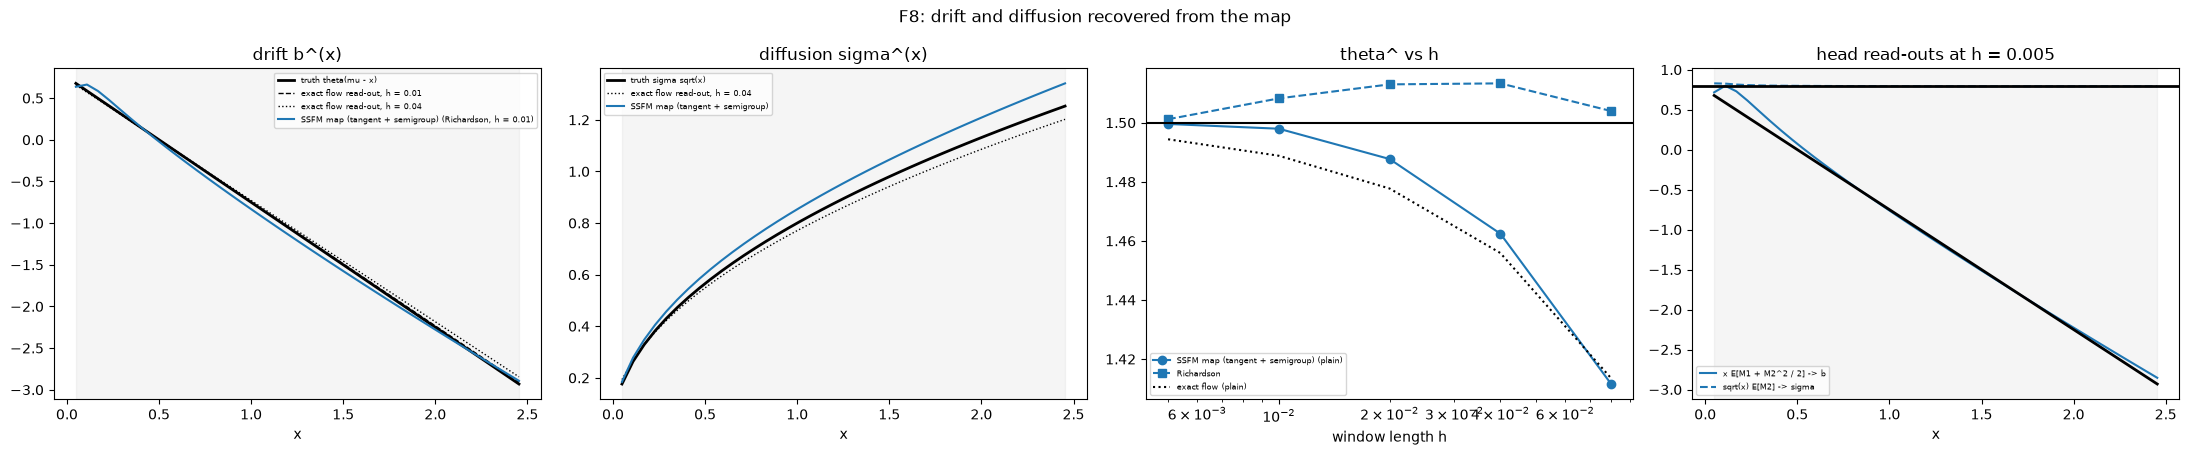

In [36]:
fig, ax = plt.subplots(1, 4, figsize=(22, 4.6))
ax[0].plot(YG, THETA * (MU - YG), 'k', lw=2, label='truth theta(mu - x)')
ax[0].plot(YG, b_exact_flow(0.01), 'k--', lw=1, label='exact flow read-out, h = 0.01')
ax[0].plot(YG, b_exact_flow(0.04), 'k:', lw=1, label='exact flow read-out, h = 0.04')
ax[1].plot(YG, SIGMA * np.sqrt(YG), 'k', lw=2, label='truth sigma sqrt(x)')
ax[1].plot(YG, np.sqrt(s2_exact_flow(0.04)), 'k:', lw=1, label='exact flow read-out, h = 0.04')
for k, mid in enumerate(MODELS):
    br = 2 * RO[mid][0.01][0] - RO[mid][0.02][0]; s2r = 2 * RO[mid][0.01][1] - RO[mid][0.02][1]
    ax[0].plot(YG, br, color=f'C{k}', label=LABEL[mid] + ' (Richardson, h = 0.01)')
    ax[1].plot(YG, np.sqrt(np.maximum(s2r, 0)), color=f'C{k}', label=LABEL[mid])
    ax[3].plot(YG, RO[mid][0.005][2], color=f'C{k}', label='x E[M1 + M2^2 / 2] -> b')
    ax[3].plot(YG, RO[mid][0.005][3], color=f'C{k}', ls='--', label='sqrt(x) E[M2] -> sigma')
    th_plain = [fit_theta_mu(RO[mid][h][0])[0] for h in HR[:-1]]
    th_rich = [fit_theta_mu(2 * RO[mid][h][0] - RO[mid][2 * h][0])[0] for h in HR[:-1]]
    ax[2].plot(HR[:-1], th_plain, 'o-', color=f'C{k}', label=LABEL[mid] + ' (plain)'); ax[2].plot(HR[:-1], th_rich, 's--', color=f'C{k}', label='Richardson')
ax[2].plot(HR[:-1], [THETA * (1 - np.exp(-THETA * h)) / (THETA * h) for h in HR[:-1]], 'k:', label='exact flow (plain)')
ax[2].axhline(THETA, color='k'); ax[2].set_xscale('log'); ax[2].set_xlabel('window length h'); ax[2].set_title('theta^ vs h')
ax[3].plot(YG, THETA * (MU - YG), 'k', lw=2); ax[3].axhline(SIGMA, color='k', lw=2)
ax[3].set_title('head read-outs at h = 0.005')
for a_ in (ax[0], ax[1], ax[3]):
    a_.axvspan(q_lo, q_hi, color='grey', alpha=0.08); a_.set_xlabel('x')
ax[0].set_title('drift b^(x)'); ax[1].set_title('diffusion sigma^(x)')
for a_ in ax:
    a_.legend(fontsize=6)
fig.suptitle('F8: drift and diffusion recovered from the map'); fig.tight_layout(); plt.show()

**After F8.** At a finite window an exact map lies on the dashed exact-flow curve, not on the truth.

The Richardson curve is the one to compare with the truth. The head read-outs are diagnostics only: the heads are not constrained individually, only $\Psi$ is. Near the lower end of the band the diffusion read-out is the most sensitive part, because there the noise is smallest in absolute terms.

### N6.7 Properties of the learned map

**What.** On the test windows, per length: (i) positivity of $\partial_x\Psi$ (the CIR flow is increasing in $x$) and the mean of $\partial_x\Psi$ against $\mathbb E\,\partial_x\phi=e^{-\theta h}$; (ii) the semigroup residual, rms of $\bigl(\Psi(x,\hat I,h)-\Psi(\Psi(x,\hat I^{(1)},\tfrac h2),\hat I^{(2)},\tfrac h2)\bigr)/\mathrm{sd}$; (iii) the Jacobian cocycle residual, the mean relative difference between $\partial_x\Psi_{s,t}(x)$ and $\partial_x\Psi_{u,t}(\Psi_{s,u}(x))\,\partial_x\Psi_{s,u}(x)$; (iv) the spatial inverse: $x^*$ with $\Psi(x^*,\hat I,h)=x_t$ by Newton's method in $\log x$, against the true $x_s$, and the share of windows where Newton converged. Also the smallest state over all test chains.

**Why.** These are the relations of the flow, especially since only the semigroup is imposed by the loss.

SSFM map (tangent + semigroup)


,h=0.00417,h=0.0167,h=0.05,h=0.1,h=0.167,h=0.5,h=1,h=2.5
min dPsi/dx,0.7222,0.6446,0.4037,0.1482,0.1301,0.09265,-1.737,-0.2185
mean dPsi/dx,0.9948,0.9746,0.9252,0.8632,0.7891,0.5112,0.264,0.01949
exact mean gain e^(-theta h),0.9938,0.9753,0.9277,0.8607,0.7788,0.4724,0.2231,0.02352
semigroup residual,0.001018,0.004137,0.01006,0.016,0.02048,0.03352,0.04458,0.091
Jacobian cocycle residual,0.0007302,0.002297,0.006335,0.01242,0.0201,0.0537,0.1184,1.93
inverse error (standardised),0.001012,0.005673,0.02036,0.04394,0.07058,0.208,0.4671,7.32
Newton converged,1,1,1,1,1,1,1,0.9992


smallest state over all test chains n in (1, 2, 5, 10, 20, 24, 25, 30, 40, 50): 7.990e-07 (smallest true test state 7.747e-04)


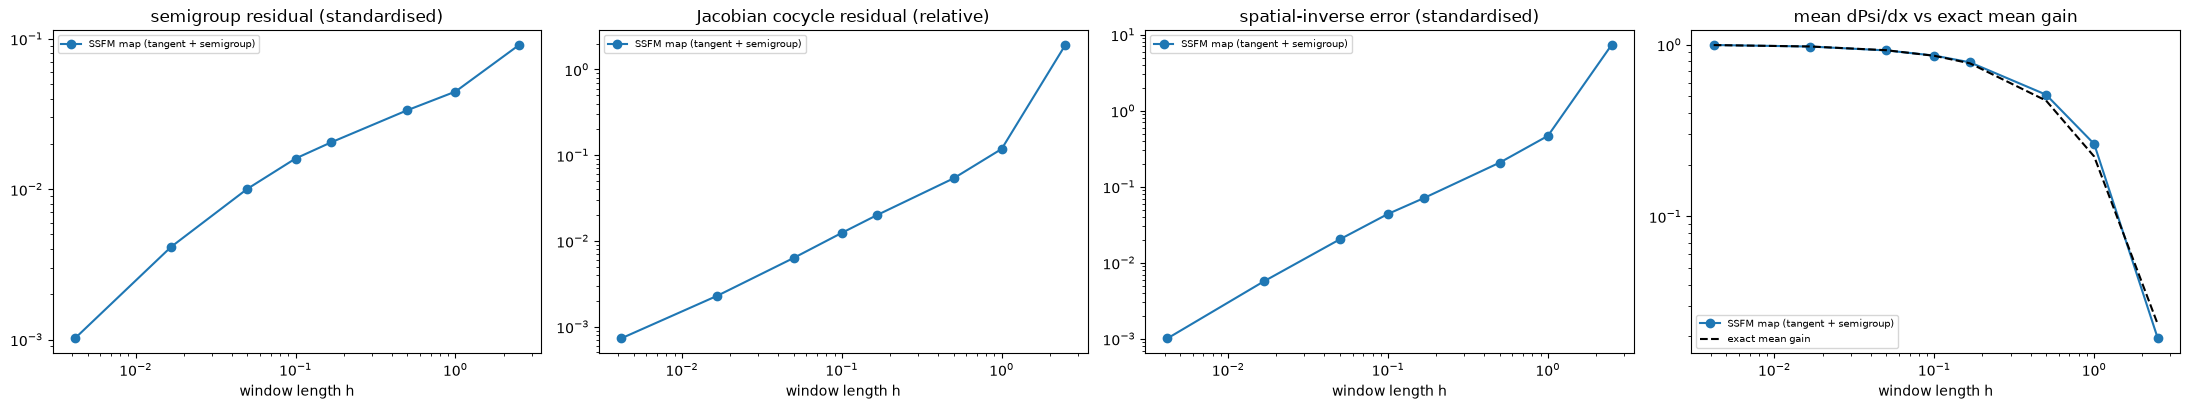

In [37]:
def newton_inverse(P_, y, Ih, h, iters=40):
    # solve Psi(x, I, h) = y for x > 0 by Newton on u = log x (Psi is increasing in x for the exact flow)
    u = np.log(y)
    for _ in range(iters):
        x = np.exp(u)
        f = Psi(P_, x, Ih, h) - y
        d = np.maximum(Psi_dx(P_, x, Ih, h) * x, 1e-8)       # dPsi / du
        u = u - np.clip(f / d, -1.0, 1.0)
    x = np.exp(u)
    return x, np.abs(Psi(P_, x, Ih, h) - y)

PROP = {}
for mid, P_ in MODELS.items():
    mn, mean_g, coc, jac, inv, conv = [], [], [], [], [], []
    for L in LV:
        W = TEST[L]
        dx = Psi_dx(P_, W['x'], W['Ih'], W['h'])
        mn.append(dx.min()); mean_g.append(dx.mean())
        Lh = L // 2
        I1 = coefs_batch(dWte, W['pi'], W['a'], np.full(len(W['a']), Lh))
        I2 = coefs_batch(dWte, W['pi'], W['a'] + Lh, np.full(len(W['a']), Lh))
        comp = coc_teacher(P_, W['x'], I1, I2, W['h'])
        direct = Psi(P_, W['x'], W['Ih'], W['h'])
        coc.append(np.sqrt(np.mean(((comp - direct) / W['sd']) ** 2)))
        xm_ = Psi(P_, W['x'], I1, W['h'] / 2)
        Dc = Psi_dx(P_, xm_, I2, W['h'] / 2) * Psi_dx(P_, W['x'], I1, W['h'] / 2)
        jac.append(np.mean(np.abs(dx - Dc) / np.abs(Dc)))
        xs_, res_ = newton_inverse(P_, W['xt'], W['Ih'], W['h'])
        inv.append(np.sqrt(np.mean(((xs_ - W['x']) / np.sqrt(v_exact(W['a'] * DT))) ** 2)))
        conv.append(np.mean(res_ < 1e-8))
    PROP[mid] = dict(min_dx=np.array(mn), mean_dx=np.array(mean_g), coc=np.array(coc), jac=np.array(jac), inv=np.array(inv), conv=np.array(conv))
    df_ = pd.DataFrame({'min dPsi/dx': mn, 'mean dPsi/dx': mean_g, 'exact mean gain e^(-theta h)': np.exp(-THETA * HV),
                        'semigroup residual': coc, 'Jacobian cocycle residual': jac, 'inverse error (standardised)': inv, 'Newton converged': conv},
                       index=[f'h={h:.3g}' for h in HV]).T
    print(LABEL[mid]); show(df_)
min_state = min(float(chained_recon(MODELS[MAP_ID], 'test', n_).min()) for n_ in NS_TAB)
print(f'smallest state over all test chains n in {NS_TAB}: {min_state:.3e} (smallest true test state {float(Xte.min()):.3e})')
fig, ax = plt.subplots(1, 4, figsize=(22, 4.2))
for k, mid in enumerate(MODELS):
    ax[0].semilogy(HV, PROP[mid]['coc'], 'o-', label=LABEL[mid]); ax[1].semilogy(HV, PROP[mid]['jac'], 'o-', label=LABEL[mid])
    ax[2].semilogy(HV, PROP[mid]['inv'], 'o-', label=LABEL[mid]); ax[3].plot(HV, PROP[mid]['mean_dx'], 'o-', label=LABEL[mid])
ax[3].plot(HV, np.exp(-THETA * HV), 'k--', label='exact mean gain'); ax[3].set_yscale('log')
for a_, t_ in zip(ax, ('semigroup residual (standardised)', 'Jacobian cocycle residual (relative)', 'spatial-inverse error (standardised)', 'mean dPsi/dx vs exact mean gain')):
    a_.set_xscale('log'); a_.set_title(t_); a_.set_xlabel('window length h'); a_.legend(fontsize=7)
fig.tight_layout(); plt.show()

### N6.8 The near-zero zone of the learned map

**What.** Three checks of how the learned map behaves near $0$.

(a) **States visited.** Every state $\hat Z_k$ produced by the chains $n\in\{1,2,5,10,20,24,25,30,40,50\}$ on the $4000$ test paths, against the true states $X_{t_k}$ at the same nodes. First the number of nodes that are $<0$, $=0$, non-finite and $>0$. Then, for $n=5,25,50$, the number of test paths whose minimum over the nodes falls in each interval $[0,10^{-6}),[10^{-6},10^{-4}),[10^{-4},10^{-3}),[10^{-3},0.01),[0.01,0.02),[0.02,0.05),[0.05,0.1),[0.1,0.2),[0.2,0.5),[0.5,\infty)$, with two extra classes $<0$ and $=0$, as a table and as bar charts (map next to truth). Last, the minimum of each path, map against truth.

(b) **The exponent.** Along the chains $\Psi=x\,e^{E}$ exactly, so $E_k=\log(\hat Z_{k+1}/\hat Z_k)$. Its distribution, and the share of calls with $|E|>0.5c$ and $|E|>0.9c$ (the cap $c=10$ active).

(c) **Below the data.** For states $x$ from $10^{-8}$ to $2$ and $h\in\{0.05,0.5\}$, the $5\%$, $50\%$ and $95\%$ quantiles of $\Psi(x,\hat I,h)$ over $\hat I\sim N(0,I_K)$, against the exact quantiles of $X_{s+h}\mid X_s=x$ (non-central $\chi^2$). The grey band is the central $99\%$ of the training states.

**Why.** Positivity is guaranteed by construction, but a positive map can still collapse towards $0$ (a chain shrinking by $e^{-c}$ per step) or hold paths away from $0$ that should come close. The minimum printed in §N6.7 is a single number; these checks show the whole zone.

**Expect.** (a) No node $<0$, $=0$ or non-finite, by construction of the map. The bars of the map close to the bars of the truth in every interval, down to the smallest true minima (about $10^{-3}$ on the test split). (b) The cap essentially never active. (c) Inside the grey band the map's quantiles follow the exact ones (the map sees only $K$ coefficients, so its spread is slightly smaller); below the band the map extrapolates, and what matters is that it pushes small states up, as the exact law does.

number of nodes by sign (all test chains n = 1..50, nodes t_1..t_n)


,< 0,= 0,non-finite,> 0,total
map (chained),0,0,0,828000,828000
truth (same nodes),0,0,0,828000,828000
truth (fine paths),0,0,0,4804000,4804000


smallest state: map 7.990e-07   truth at the same nodes 7.747e-04   (smallest fine test state 7.747e-04)
number of test paths (out of 4000) whose minimum over the nodes falls in each interval


,"truth, n=5","map, n=5","truth, n=25","map, n=25","truth, n=50","map, n=50","truth, fine path"
< 0,0,0,0,0,0,0,0
= 0,0,0,0,0,0,0,0
"[0, 1e-06)",0,0,0,0,0,1,0
"[1e-06, 0.0001)",0,0,0,2,0,1,0
"[0.0001, 0.001)",0,0,1,1,2,6,3
"[0.001, 0.01)",4,2,15,14,24,25,87
"[0.01, 0.02)",15,8,49,26,81,40,162
"[0.02, 0.05)",116,48,307,140,391,214,544
"[0.05, 0.1)",388,265,713,525,784,614,858
"[0.1, 0.2)",1040,846,1228,1306,1234,1427,1173


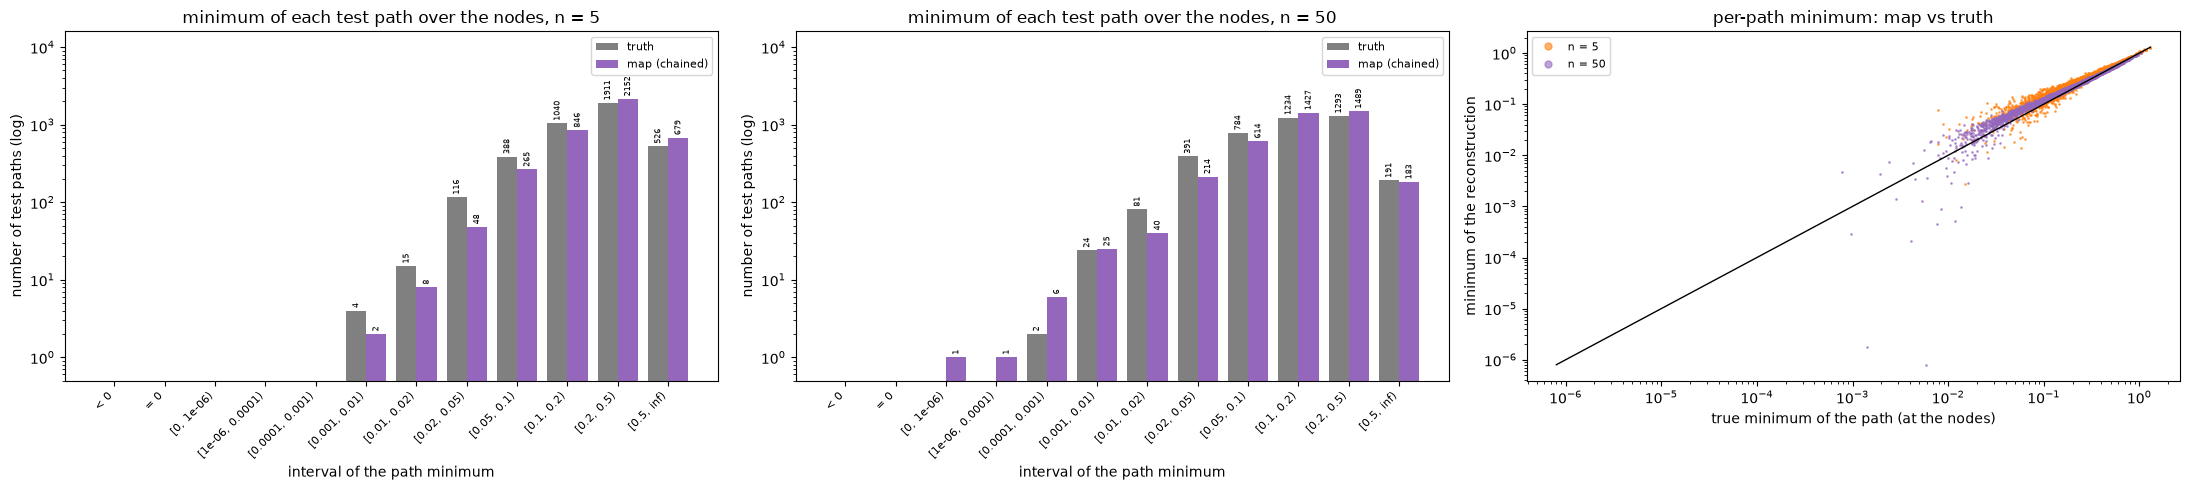

In [38]:
EPS_HIT = (0.01, 1e-3, 1e-4)                      # used in the summary file
EDGES = [0.0, 1e-6, 1e-4, 1e-3, 1e-2, 2e-2, 5e-2, 0.1, 0.2, 0.5, np.inf]
LAB_INT = [f'[{a:g}, {b:g})' for a, b in zip(EDGES[:-1], EDGES[1:])]
Pm = MODELS[MAP_ID]
Z_ALL, X_ALL_N, E_ALL = [], [], []
MIN_MAP, MIN_TRUE = {}, {}
for n_ in NS_TAB:
    Z = chained_recon(Pm, 'test', n_)
    x = get('x', 'test', n_)
    Z_ALL.append(Z[:, 1:].ravel()); X_ALL_N.append(x[:, 1:].ravel())
    with np.errstate(divide='ignore', invalid='ignore'):
        E_ALL.append(np.log(Z[:, 1:] / Z[:, :-1]).ravel())
    MIN_MAP[n_], MIN_TRUE[n_] = Z.min(axis=1), x.min(axis=1)
Z_ALL, X_ALL_N, E_ALL = np.concatenate(Z_ALL), np.concatenate(X_ALL_N), np.concatenate(E_ALL)
E_ALL = E_ALL[np.isfinite(E_ALL)]

def node_counts(v):
    return {'< 0': int(np.sum(v < 0)), '= 0': int(np.sum(v == 0)), 'non-finite': int(np.sum(~np.isfinite(v))), '> 0': int(np.sum(v > 0)), 'total': int(v.size)}

print('number of nodes by sign (all test chains n = 1..50, nodes t_1..t_n)')
show(pd.DataFrame({'map (chained)': node_counts(Z_ALL), 'truth (same nodes)': node_counts(X_ALL_N), 'truth (fine paths)': node_counts(np.asarray(Xte).ravel())}).T)
print(f'smallest state: map {np.nanmin(Z_ALL):.3e}   truth at the same nodes {X_ALL_N.min():.3e}   (smallest fine test state {float(Xte.min()):.3e})')

def path_counts(m):
    # number of paths whose minimum is < 0, = 0, or lies in each interval of EDGES
    out = {'< 0': int(np.sum(m < 0)), '= 0': int(np.sum(m == 0))}
    pos = m[m > 0]
    cnt, _ = np.histogram(pos, bins=EDGES)
    out.update({lab: int(c) for lab, c in zip(LAB_INT, cnt)})
    return out

PATHCNT = {}
for n_ in (5, 25, 50):
    PATHCNT[f'truth, n={n_}'] = path_counts(MIN_TRUE[n_])
    PATHCNT[f'map, n={n_}'] = path_counts(MIN_MAP[n_])
PATHCNT['truth, fine path'] = path_counts(np.asarray(Xte).min(axis=1))
print(f'number of test paths (out of {Xte.shape[0]}) whose minimum over the nodes falls in each interval')
show(pd.DataFrame(PATHCNT))

cats = ['< 0', '= 0'] + LAB_INT
xpos = np.arange(len(cats))
fig, ax = plt.subplots(1, 3, figsize=(22, 5))
for j, n_ in enumerate((5, 50)):
    ct, cm = PATHCNT[f'truth, n={n_}'], PATHCNT[f'map, n={n_}']
    b1 = ax[j].bar(xpos - 0.2, [ct[c] for c in cats], width=0.4, color='0.5', label='truth')
    b2 = ax[j].bar(xpos + 0.2, [cm[c] for c in cats], width=0.4, color='C4', label='map (chained)')
    for bars in (b1, b2):
        for r in bars:
            if r.get_height() > 0:
                ax[j].text(r.get_x() + r.get_width() / 2, r.get_height() * 1.08, f'{int(r.get_height())}', ha='center', va='bottom', fontsize=6, rotation=90)
    ax[j].set_yscale('log'); ax[j].set_ylim(0.5, 4 * Xte.shape[0])
    ax[j].set_xticks(xpos); ax[j].set_xticklabels(cats, rotation=45, ha='right', fontsize=8)
    ax[j].set_xlabel('interval of the path minimum'); ax[j].set_ylabel('number of test paths (log)')
    ax[j].set_title(f'minimum of each test path over the nodes, n = {n_}'); ax[j].legend(fontsize=8)
for n_, c_ in ((5, 'C1'), (50, 'C4')):
    ax[2].loglog(MIN_TRUE[n_], np.maximum(MIN_MAP[n_], 1e-300), '.', ms=2, color=c_, alpha=0.6, label=f'n = {n_}')
m_lo = min(min(MIN_TRUE[n_].min(), np.maximum(MIN_MAP[n_], 1e-300).min()) for n_ in (5, 50)); m_hi = max(max(MIN_TRUE[n_].max(), MIN_MAP[n_].max()) for n_ in (5, 50))
ax[2].loglog([m_lo, m_hi], [m_lo, m_hi], 'k', lw=1)
ax[2].set_xlabel('true minimum of the path (at the nodes)'); ax[2].set_ylabel('minimum of the reconstruction')
ax[2].set_title('per-path minimum: map vs truth'); ax[2].legend(fontsize=8, markerscale=5)
fig.tight_layout(); plt.show()

**After (a).** The first two classes must be empty for the map; a count there is a bug, not a training error. In the bar charts, map bars taller than the truth in the low intervals mean chains that collapse towards $0$; map bars missing where the truth has paths mean paths held away from $0$. In the scatter, points below the diagonal at small true minima are undershoots.

exponent E = log(Z_(k+1) / Z_k) over 828000 map calls: max |E| = 4.945 (cap 10.0)
  share with |E| > 0.5 cap: 0.00e+00   |E| > 0.9 cap: 0.00e+00


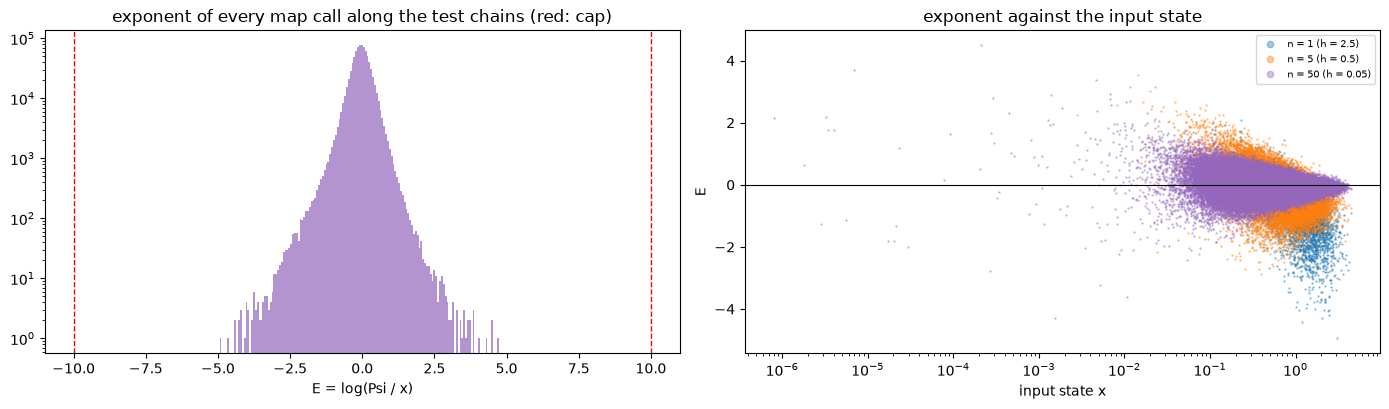

In [39]:
aE = np.abs(E_ALL)
print(f'exponent E = log(Z_(k+1) / Z_k) over {E_ALL.size} map calls: max |E| = {aE.max():.3f} (cap {LOGCAP})')
print(f'  share with |E| > 0.5 cap: {np.mean(aE > 0.5 * LOGCAP):.2e}   |E| > 0.9 cap: {np.mean(aE > 0.9 * LOGCAP):.2e}')
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].hist(E_ALL, bins=150, color='C4', alpha=0.7); ax[0].set_yscale('log')
for v_ in (-LOGCAP, LOGCAP):
    ax[0].axvline(v_, color='r', ls='--', lw=1)
ax[0].set_xlabel('E = log(Psi / x)'); ax[0].set_title('exponent of every map call along the test chains (red: cap)')
for n_, c_ in ((1, 'C0'), (5, 'C1'), (50, 'C4')):
    Z = chained_recon(Pm, 'test', n_)
    ax[1].plot(Z[:, :-1].ravel(), np.log(Z[:, 1:] / Z[:, :-1]).ravel(), '.', ms=1.5, alpha=0.4, color=c_, label=f'n = {n_} (h = {T_END / n_:.3g})')
ax[1].set_xscale('log'); ax[1].axhline(0, color='k', lw=0.8)
ax[1].set_xlabel('input state x'); ax[1].set_ylabel('E'); ax[1].set_title('exponent against the input state'); ax[1].legend(fontsize=7, markerscale=6)
fig.tight_layout(); plt.show()

**After (b).** In the right panel the exponent should be positive and growing as $x$ decreases (the drift pushes small states up, $\mathrm d\log X$ has drift $\approx(\theta\mu-\sigma^2/2)/X$ near $0$), and more so for long windows. Negative exponents at the smallest states are the signature of a collapse.

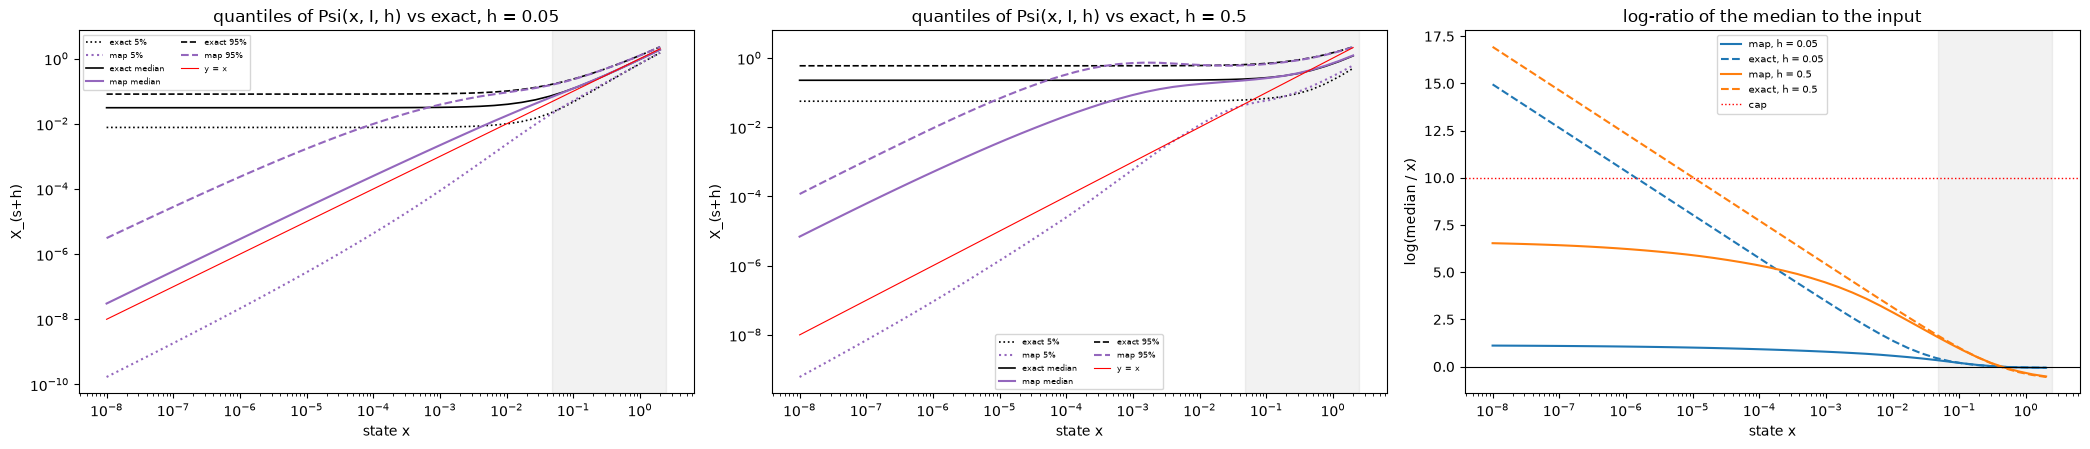

h = 0.05: inside the data band, max |log(map / exact)| over the three quantiles = 0.099;  below the band the map median / x ranges from 1.42 to 3.05  (exact: >= 1.59)
h = 0.5: inside the data band, max |log(map / exact)| over the three quantiles = 0.261;  below the band the map median / x ranges from 5.1 to 691  (exact: >= 5.61)


In [40]:
def cir_ppf(q, x, h):
    # quantile of X_(s+h) given X_s = x (non-central chi-square)
    c = _c(h)
    return sps.ncx2.ppf(q, CIR_DF, 2 * c * x * np.exp(-THETA * h)) / (2 * c)

XS = np.logspace(-8, np.log10(2.0), 41)
q_lo, q_hi = np.quantile(np.array(Xf_tr[:, ::10]).ravel(), [0.005, 0.995])
Zs = rg(777, 3, 500).normal(size=(N_RO // 2, KC)); Zs = np.concatenate([Zs, -Zs])
fig, ax = plt.subplots(1, 3, figsize=(21, 4.6))
STRESS = {}
for j, h in enumerate((0.05, 0.5)):
    qm = np.array([np.quantile(Psi(Pm, np.full(len(Zs), x0), Zs, h), [0.05, 0.5, 0.95]) for x0 in XS])
    qe = np.array([cir_ppf(np.array([0.05, 0.5, 0.95]), x0, h) for x0 in XS])
    STRESS[h] = (qm, qe)
    for k, (lab, ls) in enumerate((('5%', ':'), ('median', '-'), ('95%', '--'))):
        ax[j].loglog(XS, qe[:, k], color='k', ls=ls, lw=1.2, label=f'exact {lab}')
        ax[j].loglog(XS, qm[:, k], color='C4', ls=ls, lw=1.5, label=f'map {lab}')
    ax[j].loglog(XS, XS, color='r', lw=0.8, label='y = x')
    ax[j].axvspan(q_lo, q_hi, color='grey', alpha=0.1)
    ax[j].set_xlabel('state x'); ax[j].set_ylabel('X_(s+h)'); ax[j].set_title(f'quantiles of Psi(x, I, h) vs exact, h = {h}'); ax[j].legend(fontsize=6, ncol=2)
    ax[2].semilogx(XS, np.log(qm[:, 1] / XS), color=f'C{j}', label=f'map, h = {h}')
    ax[2].semilogx(XS, np.log(qe[:, 1] / XS), color=f'C{j}', ls='--', label=f'exact, h = {h}')
ax[2].axvspan(q_lo, q_hi, color='grey', alpha=0.1); ax[2].axhline(0, color='k', lw=0.8); ax[2].axhline(LOGCAP, color='r', ls=':', lw=1, label='cap')
ax[2].set_xlabel('state x'); ax[2].set_ylabel('log(median / x)'); ax[2].set_title('log-ratio of the median to the input'); ax[2].legend(fontsize=7)
fig.tight_layout(); plt.show()
in_band = (XS >= q_lo) & (XS <= q_hi)
for h in (0.05, 0.5):
    qm, qe = STRESS[h]
    print(f'h = {h}: inside the data band, max |log(map / exact)| over the three quantiles = {np.max(np.abs(np.log(qm[in_band] / qe[in_band]))):.3f};'
          f'  below the band the map median / x ranges from {np.min(qm[~in_band & (XS < q_lo), 1] / XS[~in_band & (XS < q_lo)]):.3g}'
          f' to {np.max(qm[~in_band & (XS < q_lo), 1] / XS[~in_band & (XS < q_lo)]):.3g}  (exact: >= {np.min(qe[XS < q_lo, 1] / XS[XS < q_lo]):.3g})')

**After (c).** Inside the grey band the purple and black curves should coincide, apart from a slightly narrower map spread at $h=0.5$. Below the band only the direction matters: the exact median grows much faster than $x$ (the log-ratio in the right panel rises steeply), because a CIR state near $0$ is pushed up by the drift. A map median at or below $y=x$ there is the mechanism by which a chain could drift into $0$; the input saturation of §0.5 makes the map's response below the band flat, so it repeats what it learned at the lowest observed states.

The right panel also shows a limit of the form itself. From a state near $0$ the exact median of $X_{s+h}$ tends to a constant, so the log-ratio it needs grows like $\log(1/x)$ and passes the cap $c=10$ below $x\approx10^{-5}$ ($h=0.05$) or $10^{-4}$ ($h=0.5$). Below that the map cannot recover as fast as the exact process, whatever the training. This is far below the data (smallest state about $5\cdot10^{-4}$), but it is the reason the cap cannot be made much smaller.

### N6.9 Summary table and file

In [41]:
ROWS = []
def add(metric, value):
    ROWS.append((VARIANT, MAP_ID, metric, float(value)))
add('strong_error_val', SE_VAL[MAP_ID])
add('strong_error_test', SE_TEST[MAP_ID]); add('strong_error_test_ci_low', boot_ci(SEB[MAP_ID])[0]); add('strong_error_test_ci_high', boot_ci(SEB[MAP_ID])[1])
for n_ in NS_TAB:
    add(f'eps_n{n_}_test', ST_TEST[MAP_ID][n_][0])
for j, L in enumerate(LV):
    add(f'test_std_rmse_h{L * DT:.4g}', RM[MAP_ID][j])
add('one_shot_rms', ONE[MAP_ID]['rms']); add('one_shot_slope', ONE[MAP_ID]['slope'])
add('median_path_error', np.median(PE['strong (avg n=20..50)'][MAP_ID])); add('p99_path_error', np.quantile(PE['strong (avg n=20..50)'][MAP_ID], 0.99))
add('signed_error_mean', SG[MAP_ID].mean()); add('signed_rel_error_mean', SGR[MAP_ID].mean())
add('min_dPsi_dx', PROP[MAP_ID]['min_dx'].min()); add('min_chain_state', min_state)
for e in (0.01, 1e-3, 1e-4):
    add(f'p_min_below_{e:g}_map_n50', np.mean(MIN_MAP[50] < e)); add(f'p_min_below_{e:g}_truth_n50', np.mean(MIN_TRUE[50] < e))
add('max_abs_exponent', aE.max()); add('share_exponent_above_half_cap', np.mean(aE > 0.5 * LOGCAP))
for k_ in ('theta_r', 'mu_r', 'sigma_r', 'b_rmse'):
    add(f'{k_}_h0.01', REC[(MAP_ID, 0.01)][k_])
SUMMARY = pd.DataFrame(ROWS, columns=['variant', 'model', 'metric', 'value'])
path_ = os.path.join(SHARED_DIR, 'summary_CIR_stage1_fwd.csv')
SUMMARY.to_csv(path_, index=False)
show(SUMMARY.set_index('metric')[['value']].T)
print('written:', path_)
print(f'tests: {sum(ok for *_, ok in TEST_LOG)} / {len(TEST_LOG)} passed')

metric,strong_error_val,strong_error_test,strong_error_test_ci_low,strong_error_test_ci_high,eps_n1_test,eps_n2_test,eps_n5_test,eps_n10_test,eps_n20_test,eps_n24_test,eps_n25_test,eps_n30_test,eps_n40_test,eps_n50_test,test_std_rmse_h0.004167,test_std_rmse_h0.01667,test_std_rmse_h0.05,test_std_rmse_h0.1,test_std_rmse_h0.1667,test_std_rmse_h0.5,test_std_rmse_h1,test_std_rmse_h2.5,one_shot_rms,one_shot_slope,median_path_error,p99_path_error,signed_error_mean,signed_rel_error_mean,min_dPsi_dx,min_chain_state,p_min_below_0.01_map_n50,p_min_below_0.01_truth_n50,p_min_below_0.001_map_n50,p_min_below_0.001_truth_n50,p_min_below_0.0001_map_n50,p_min_below_0.0001_truth_n50,max_abs_exponent,share_exponent_above_half_cap,theta_r_h0.01,mu_r_h0.01,sigma_r_h0.01,b_rmse_h0.01
value,0.07885,0.07711,0.07484,0.07986,0.1382,0.1361,0.102,0.08577,0.07867,0.07805,0.07804,0.07682,0.07576,0.07532,0.001006,0.005277,0.01675,0.03142,0.04587,0.08481,0.1142,0.1373,0.1382,0.9999,0.05756,0.2083,0.0205,0.05085,-1.737,7.99e-07,0.00825,0.0065,0.002,0.0005,0.0005,0,4.945,0,1.508,0.4824,0.8529,0.05896


written: results_shared/summary_CIR_stage1_fwd.csv
tests: 12 / 12 passed
